# PRCP-1027 · Skin Disorder Prediction
### Differential diagnosis of erythemato-squamous diseases with Machine Learning and Explainable AI

| | |
|---|---|
| **Domain** | Healthcare / Dermatology |
| **Problem type** | Multiclass classification (6 classes) on structured clinical + histopathological data |
| **Deliverable** | This single, fully executed notebook (Task 1 report, Task 2 model, Task 3 doctor suggestions, Model Comparison Report, Challenges Report) |

---
## 1. Project introduction and objectives

### Three original requirements
1. **Task 1 – Data analysis report:** a complete analysis of the given data.
2. **Task 2 – Predictive model:** a machine-learning model that predicts the class of skin disease.
3. **Task 3 – Suggestions to doctors:** how doctors can identify these diseases as early as possible.

Plus two reports requested in the brief: a **Model Comparison Report** (recommend the best model for production) and a **Report on Challenges faced** (data challenges and the technique used, with reasons).

### Additional capabilities added
Advanced model comparison · hyperparameter optimisation (RandomizedSearchCV + Optuna) · feature selection experiments · class-imbalance experiments (class weights, random oversampling, SMOTE) · cross-validation stability · probability calibration & uncertainty analysis · SHAP explainability · model serialisation.

### Dataset overview
The UCI *Dermatology* database. Each row is one patient. Patients were first evaluated clinically; skin samples were then taken and **22 histopathological features** were graded under a microscope. All clinical/histopathological features are graded 0–3 (0 = absent, 3 = largest amount), `family_history` is 0/1, `Age` is in years.
All counts and statistics quoted below are **computed from the data in this notebook**, not typed in by hand.

### Six target disease categories
| Class | Disease |
|---|---|
| 1 | Psoriasis |
| 2 | Seborrheic dermatitis |
| 3 | Lichen planus |
| 4 | Pityriasis rosea |
| 5 | Chronic dermatitis |
| 6 | Pityriasis rubra pilaris |

### Technology stack
Python · Pandas · NumPy · SciPy · Statsmodels · Matplotlib / Seaborn · Scikit-learn · Imbalanced-learn · XGBoost · CatBoost · Optuna · SHAP · Joblib.

### Expected outcomes
A validated, leakage-free pipeline; a defensible choice of production model based on cross-validated **macro-F1** and class-wise recall; an explanation of which findings drive predictions; and practical, appropriately cautious recommendations for clinicians.

>

## Revision note (post-audit corrections)
This notebook was revised after an evaluation audit. **All original code cells, their source and their stored outputs are unchanged**, and the original final test results (Section 18) are preserved. What changed:

| Where | Change |
|---|---|
| Sections 13, 17, 18 (text) | The statement that the test set is "touched once" was **incorrect** and has been replaced with an accurate description of how the test set is read (see Section 13). |
| **18.1** (new) | Calibration diagnostics: per-class Brier score, reliability diagrams with counts and Wilson intervals, probability-extremes check, and an overfitting / selection-optimism check. The existing sigmoid and isotonic experiments are kept. |
| **18.2** (new) | Privacy-preserving misclassification analysis (actual class, predicted class, full six-class probability distribution; pseudonymous case IDs, no feature values). |
| Section 19 (notes, new cells) | SHAP is labelled a post-evaluation explanation of the *uncalibrated* model; test-set permutation importance is labelled descriptive only; a training-patient SHAP ranking is added for comparison. |
| **20.1** (new) | Revised, more cautious clinician-facing wording, low-confidence explanation, specialist-review warnings, and `predict_with_support_v2`. The original "Suggestions to doctors" cell is kept for the audit trail but is **superseded** by 20.1. |
| Limitations | Bullets added on calibration, probabilities, high-confidence errors and test-set reads. |

**New cells have no stored outputs until you run them (Run All).** Phrases in *preserved outputs* that still use the old wording (for example the Section 21 challenges table entry "untouched test set", and the dataset row numbers printed in Sections 18–19) are historical outputs; re-running the notebook regenerates them from the unchanged code cells, so the old wording is superseded by Section 13.

>

## 2. Problem statement and business understanding

**Why are these six diseases hard to tell apart?** Psoriasis, seborrheic dermatitis, lichen planus, pityriasis rosea, chronic dermatitis and pityriasis rubra pilaris all present with **erythema (redness) and scaling**, with very small clinical differences.

**Why is clinical examination alone not enough?** Because the clinical picture overlaps, a **biopsy** is usually needed. Unfortunately the diseases also **share many histopathological features**, and a disease can show the features of another disease in its early stage and only develop its characteristic features later.

**Why do histopathological observations matter?** They add microscopic evidence (e.g. basal-layer damage, rete-ridge changes, infiltrate type) that is not visible on examination. Section 10 quantifies how much each evidence type contributes in this dataset.

**How can multiclass classification help doctors?** A model that combines all graded findings can give a *second opinion* with class probabilities, flag atypical/low-confidence patients for specialist review, and show which findings drove a prediction.

**What does the model predict?** One of six classes (1–6) for a patient, from 34 inputs (11 clinical, 22 histopathological, age).

```text
Patient → Clinical Examination → Histopathological Examination → Feature Collection
        → Data Preprocessing → Machine Learning Model → Predicted Disease Class + probabilities
        → Doctor Review (final diagnosis always by a qualified clinician)
```

## 3. Dataset description and data dictionary
The dictionary below is built in code from the real column names. Note: the problem statement text says clinical features number "12", but its own attribute list (and the CSV) contain **11 clinical** attributes (items 1–11, family history being the 11th), **22 histopathological** attributes (items 12–33) and **Age** (item 34) = 34 predictors.

In [89]:
CLINICAL = ["erythema","scaling","definite_borders","itching","koebner_phenomenon","polygonal_papules",
            "follicular_papules","oral_mucosal_involvement","knee_and_elbow_involvement","scalp_involvement","family_history"]
HISTO = ["melanin_incontinence","eosinophils_in_the_infiltrate","PNL_infiltrate","fibrosis_of_the_papillary_dermis",
         "exocytosis","acanthosis","hyperkeratosis","parakeratosis","clubbing_of_the_rete_ridges",
         "elongation_of_the_rete_ridges","thinning_of_the_suprapapillary_epidermis","spongiform_pustule",
         "munro_microabcess","focal_hypergranulosis","disappearance_of_the_granular_layer",
         "vacuolisation_and_damage_of_basal_layer","spongiosis","saw-tooth_appearance_of_retes",
         "follicular_horn_plug","perifollicular_parakeratosis","inflammatory_monoluclear_inflitrate","band-like_infiltrate"]
FEATURES = CLINICAL + HISTO + ["Age"]

DESC = {
 "erythema":"Redness of the skin", "scaling":"Scaling of the skin surface",
 "definite_borders":"Sharply demarcated lesion borders", "itching":"Itching (pruritus)",
 "koebner_phenomenon":"Lesions appearing at sites of skin injury", "polygonal_papules":"Flat-topped polygonal papules",
 "follicular_papules":"Papules centred on hair follicles", "oral_mucosal_involvement":"Lesions inside the mouth",
 "knee_and_elbow_involvement":"Lesions on knees and elbows", "scalp_involvement":"Lesions on the scalp",
 "family_history":"1 if any of these diseases occurred in the family, else 0",
 "melanin_incontinence":"Melanin pigment dropped into the dermis", "eosinophils_in_the_infiltrate":"Eosinophils among infiltrate cells",
 "PNL_infiltrate":"Polymorphonuclear leukocytes in the infiltrate", "fibrosis_of_the_papillary_dermis":"Fibrosis of the papillary dermis",
 "exocytosis":"Inflammatory cells migrating into the epidermis", "acanthosis":"Thickening of the epidermis",
 "hyperkeratosis":"Thickening of the stratum corneum", "parakeratosis":"Retained nuclei in the stratum corneum",
 "clubbing_of_the_rete_ridges":"Club-shaped rete ridges", "elongation_of_the_rete_ridges":"Elongated rete ridges",
 "thinning_of_the_suprapapillary_epidermis":"Thin epidermis above dermal papillae", "spongiform_pustule":"Neutrophil collections in spongiotic epidermis",
 "munro_microabcess":"Neutrophil collections in the stratum corneum", "focal_hypergranulosis":"Focal thickening of the granular layer",
 "disappearance_of_the_granular_layer":"Granular layer absent", "vacuolisation_and_damage_of_basal_layer":"Basal-layer vacuolisation / damage",
 "spongiosis":"Intercellular oedema of the epidermis", "saw-tooth_appearance_of_retes":"Saw-tooth shape of rete ridges",
 "follicular_horn_plug":"Keratin plug in hair follicles", "perifollicular_parakeratosis":"Parakeratosis around follicles",
 "inflammatory_monoluclear_inflitrate":"Mononuclear inflammatory infiltrate (column name spelled as in CSV)",
 "band-like_infiltrate":"Band of infiltrate at the dermo-epidermal junction", "Age":"Patient age in years (stored as text; '?' = missing)"}
import pandas as pd
rows = []
for f in FEATURES:
    grp = "Clinical" if f in CLINICAL else ("Histopathological" if f in HISTO else "Demographic")
    exp = "0 or 1" if f=="family_history" else ("years (numeric)" if f=="Age" else "0, 1, 2, 3 (ordinal)")
    rows.append([f, grp, DESC[f], exp, "string (contains '?')" if f=="Age" else "integer"])
rows.append(["class","Target","Disease class: 1 Psoriasis, 2 Seborrheic dermatitis, 3 Lichen planus, 4 Pityriasis rosea, 5 Chronic dermatitis, 6 Pityriasis rubra pilaris","1–6","integer"])
data_dictionary = pd.DataFrame(rows, columns=["feature","group","description","expected values","raw dtype"])
print(len(CLINICAL), "clinical +", len(HISTO), "histopathological + Age =", len(FEATURES), "predictors")
data_dictionary

11 clinical + 22 histopathological + Age = 34 predictors


,feature,group,description,expected values,raw dtype
0,erythema,Clinical,Redness of the skin,"0, 1, 2, 3 (ordinal)",integer
1,scaling,Clinical,Scaling of the skin surface,"0, 1, 2, 3 (ordinal)",integer
2,definite_borders,Clinical,Sharply demarcated lesion borders,"0, 1, 2, 3 (ordinal)",integer
3,itching,Clinical,Itching (pruritus),"0, 1, 2, 3 (ordinal)",integer
4,koebner_phenomenon,Clinical,Lesions appearing at sites of skin injury,"0, 1, 2, 3 (ordinal)",integer
5,polygonal_papules,Clinical,Flat-topped polygonal papules,"0, 1, 2, 3 (ordinal)",integer
6,follicular_papules,Clinical,Papules centred on hair follicles,"0, 1, 2, 3 (ordinal)",integer
7,oral_mucosal_involvement,Clinical,Lesions inside the mouth,"0, 1, 2, 3 (ordinal)",integer
8,knee_and_elbow_involvement,Clinical,Lesions on knees and elbows,"0, 1, 2, 3 (ordinal)",integer
9,scalp_involvement,Clinical,Lesions on the scalp,"0, 1, 2, 3 (ordinal)",integer


## 4. Importing libraries and configuration

In [90]:
import os, warnings, time, json, random
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_validate, cross_val_predict, RandomizedSearchCV)
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report,
                             confusion_matrix, balanced_accuracy_score, matthews_corrcoef, log_loss, make_scorer)

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)

DATA_PATH = "/content/dataset_35_dermatology (1).csv"
FIG_DIR, EVAL_DIR, MODEL_DIR = "../artifacts/figures", "../artifacts/evaluation", "../models"
for d in (FIG_DIR, EVAL_DIR, MODEL_DIR, "../data/processed"):
    os.makedirs(d, exist_ok=True)

CLASS_NAMES = {1:"Psoriasis", 2:"Seborrheic dermatitis", 3:"Lichen planus",
               4:"Pityriasis rosea", 5:"Chronic dermatitis", 6:"Pityriasis rubra pilaris"}
SHORT = {1:"Psoriasis", 2:"Seb. derm.", 3:"Lichen planus", 4:"Pit. rosea", 5:"Chronic derm.", 6:"PRP"}
PALETTE = sns.color_palette("colorblind", 6)
CLASS_COLORS = {c: PALETTE[i] for i, c in enumerate(range(1, 7))}

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold"})

def savefig(name):
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=130, bbox_inches="tight")

def obs(text):
    """Render a data-driven observation (numbers inside are computed, never typed in)."""
    display(Markdown("**Interpretation.** " + text))

print("Libraries loaded · seed =", SEED)

Libraries loaded · seed = 42


## 5. Data loading and initial inspection

In [91]:
df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
print("Expected: 366 rows x 35 columns ->", "OK" if df.shape == (366, 35) else "MISMATCH")
display(df.head())
display(df.tail())

Dataset shape: (366, 35)
Expected: 366 rows x 35 columns -> OK


,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,Age,class
0,2,2,0,3,0,0,0,0,1,0,...,0,0,3,0,0,0,1,0,55,2
1,3,3,3,2,1,0,0,0,1,1,...,0,0,0,0,0,0,1,0,8,1
2,2,1,2,3,1,3,0,3,0,0,...,0,2,3,2,0,0,2,3,26,3
3,2,2,2,0,0,0,0,0,3,2,...,3,0,0,0,0,0,3,0,40,1
4,2,3,2,2,2,2,0,2,0,0,...,2,3,2,3,0,0,2,3,45,3


,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,Age,class
361,2,1,1,0,1,0,0,0,0,0,...,0,0,1,0,0,0,2,0,25,4
362,3,2,1,0,1,0,0,0,0,0,...,1,0,1,0,0,0,2,0,36,4
363,3,2,2,2,3,2,0,2,0,0,...,0,3,0,3,0,0,2,3,28,3
364,2,1,3,1,2,3,0,2,0,0,...,0,2,0,1,0,0,2,3,50,3
365,3,2,2,0,0,0,0,0,3,3,...,2,0,0,0,0,0,3,0,35,1


In [92]:
print("Columns:", list(df.columns))
df.info()

Columns: ['erythema', 'scaling', 'definite_borders', 'itching', 'koebner_phenomenon', 'polygonal_papules', 'follicular_papules', 'oral_mucosal_involvement', 'knee_and_elbow_involvement', 'scalp_involvement', 'family_history', 'melanin_incontinence', 'eosinophils_in_the_infiltrate', 'PNL_infiltrate', 'fibrosis_of_the_papillary_dermis', 'exocytosis', 'acanthosis', 'hyperkeratosis', 'parakeratosis', 'clubbing_of_the_rete_ridges', 'elongation_of_the_rete_ridges', 'thinning_of_the_suprapapillary_epidermis', 'spongiform_pustule', 'munro_microabcess', 'focal_hypergranulosis', 'disappearance_of_the_granular_layer', 'vacuolisation_and_damage_of_basal_layer', 'spongiosis', 'saw-tooth_appearance_of_retes', 'follicular_horn_plug', 'perifollicular_parakeratosis', 'inflammatory_monoluclear_inflitrate', 'band-like_infiltrate', 'Age', 'class']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 366 entries, 0 to 365
Data columns (total 35 columns):
 #   Column                                    Non-Null

In [93]:
print("Unique values per column (first 12 shown):")
uniq = pd.DataFrame({"n_unique": df.nunique(), "dtype": df.dtypes.astype(str)})
uniq["values"] = [sorted(df[c].unique().tolist())[:12] if c != "Age" else "numeric text + '?'" for c in df.columns]
display(uniq)
print("\nTarget distribution:")
display(df["class"].value_counts().sort_index().rename("count").to_frame().assign(
    disease=lambda t: t.index.map(CLASS_NAMES), percent=lambda t: (100*t["count"]/len(df)).round(1)))
display(df.describe(include="all").T.head(40))

Unique values per column (first 12 shown):


,n_unique,dtype,values
erythema,4,int64,"[0, 1, 2, 3]"
scaling,4,int64,"[0, 1, 2, 3]"
definite_borders,4,int64,"[0, 1, 2, 3]"
itching,4,int64,"[0, 1, 2, 3]"
koebner_phenomenon,4,int64,"[0, 1, 2, 3]"
polygonal_papules,4,int64,"[0, 1, 2, 3]"
follicular_papules,4,int64,"[0, 1, 2, 3]"
oral_mucosal_involvement,4,int64,"[0, 1, 2, 3]"
knee_and_elbow_involvement,4,int64,"[0, 1, 2, 3]"
scalp_involvement,4,int64,"[0, 1, 2, 3]"



Target distribution:


,count,disease,percent
class,,,
1,112,Psoriasis,30.6
2,61,Seborrheic dermatitis,16.7
3,72,Lichen planus,19.7
4,49,Pityriasis rosea,13.4
5,52,Chronic dermatitis,14.2
6,20,Pityriasis rubra pilaris,5.5


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
erythema,366.0,NaN,NaN,NaN,2.068306,0.664753,0.0,2.0,2.0,2.0,3.0
scaling,366.0,NaN,NaN,NaN,1.795082,0.701527,0.0,1.0,2.0,2.0,3.0
definite_borders,366.0,NaN,NaN,NaN,1.54918,0.907525,0.0,1.0,2.0,2.0,3.0
itching,366.0,NaN,NaN,NaN,1.36612,1.138299,0.0,0.0,1.0,2.0,3.0
koebner_phenomenon,366.0,NaN,NaN,NaN,0.63388,0.908016,0.0,0.0,0.0,1.0,3.0
polygonal_papules,366.0,NaN,NaN,NaN,0.448087,0.957327,0.0,0.0,0.0,0.0,3.0
follicular_papules,366.0,NaN,NaN,NaN,0.166667,0.570588,0.0,0.0,0.0,0.0,3.0
oral_mucosal_involvement,366.0,NaN,NaN,NaN,0.377049,0.834147,0.0,0.0,0.0,0.0,3.0
knee_and_elbow_involvement,366.0,NaN,NaN,NaN,0.614754,0.982979,0.0,0.0,0.0,1.0,3.0
scalp_involvement,366.0,NaN,NaN,NaN,0.519126,0.905639,0.0,0.0,0.0,1.0,3.0


## 6. Data quality assessment
Checks: missing values, the `?` placeholder, duplicates, invalid values versus the documented ranges, Age outliers, data types and target validity.

In [94]:
print("Missing values (NaN):", int(df.isnull().sum().sum()))
qm = (df.astype(str) == "?").sum()
print("'?' placeholders per column:\n", qm[qm > 0].to_string())
print("Exact duplicate rows:", int(df.duplicated().sum()))

dtype_issue = [c for c in df.columns if c not in ("Age",) and not pd.api.types.is_integer_dtype(df[c])]
print("Non-integer columns other than Age:", dtype_issue or "none")
print("Age raw dtype:", df["Age"].dtype, "(text only because of '?')")

# documented ranges: 0-3 for graded features, 0/1 for family_history
bad = {}
for c in FEATURES:
    if c == "Age": continue
    hi = 1 if c == "family_history" else 3
    n_bad = int(((df[c] < 0) | (df[c] > hi)).sum())
    if n_bad: bad[c] = n_bad
print("Values outside documented ranges:", bad or "none")
print("Target values:", sorted(df["class"].unique()), "-> valid" if set(df["class"].unique()) <= set(range(1,7)) else "-> INVALID")
print("Features whose observed max is below the documented max of 3:",
      [c for c in FEATURES if c not in ("Age","family_history") and df[c].max() < 3])

age_num = pd.to_numeric(df["Age"].replace("?", np.nan))
q1, q3 = age_num.quantile([.25, .75]); iqr = q3 - q1
lo, hi_ = q1 - 1.5*iqr, q3 + 1.5*iqr
out = age_num[(age_num < lo) | (age_num > hi_)]
print(f"Age: min={age_num.min():.0f}, max={age_num.max():.0f}, IQR fences=({lo:.1f}, {hi_:.1f}), outliers={len(out)}")
print("Patients aged 0 (could be infants or a data-entry issue):", int((age_num == 0).sum()))

Missing values (NaN): 0
'?' placeholders per column:
 Age    8
Exact duplicate rows: 0
Non-integer columns other than Age: none
Age raw dtype: object (text only because of '?')
Values outside documented ranges: none
Target values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)] -> valid
Features whose observed max is below the documented max of 3: ['eosinophils_in_the_infiltrate']
Age: min=0, max=75, IQR fences=(-12.1, 86.9), outliers=0
Patients aged 0 (could be infants or a data-entry issue): 1


In [95]:
n_q = int((df["Age"].astype(str) == "?").sum())
obs(f"**{n_q} Age values are stored as `?`** (not as NaN), so `isnull()` reports 0 missing values and Age is read as text. "
    f"There are no duplicate rows, every graded feature is inside its documented range, and the target only contains classes 1–6. "
    f"Age has {len(out)} IQR-outliers; plausible values (min {age_num.min():.0f}, max {age_num.max():.0f}) so they are **kept**.")

**Interpretation.** **8 Age values are stored as `?`** (not as NaN), so `isnull()` reports 0 missing values and Age is read as text. There are no duplicate rows, every graded feature is inside its documented range, and the target only contains classes 1–6. Age has 0 IQR-outliers; plausible values (min 0, max 75) so they are **kept**.

## 7. Data cleaning and preprocessing

| Step | Technique |
|---|---|
| Missing Age | convert `?` → `NaN`; **median imputation fitted inside the training folds only** (done in the model pipelines) |
| Duplicates | exact duplicate validation (none found) |
| Feature validation | documented ranges checked (Section 6) |
| Target validation | classes 1–6 confirmed |
| Numeric conversion | Age converted to float |

No valid observation is deleted. For modelling, **imputation and scaling live inside scikit-learn pipelines**, so they are re-fitted on each training fold and never see validation/test rows.

**Hold-out split.** To make leakage impossible, the final test set is separated **right here**, before any feature-ranking or modelling analysis (Section 13 documents and checks the strategy). Sections 10–12 and all modelling use only the training part. Section 8–9 are *descriptive* analyses of the full dataset and are not used to choose models.

In [96]:
df["Age"] = pd.to_numeric(df["Age"].replace("?", np.nan), errors="coerce")
print("Age dtype:", df["Age"].dtype, "| missing Age after conversion:", int(df["Age"].isnull().sum()))
print("Median Age (full data, for information only):", df["Age"].median())
print("Which classes have the missing Ages:", df.loc[df["Age"].isnull(), "class"].value_counts().sort_index().to_dict())
df.to_csv("../data/processed/dermatology_clean_age_nan.csv", index=False)

# ---- stratified 80/20 hold-out split (test set is not touched until Section 18)
X = df[FEATURES].copy()
y = df["class"].copy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
# xgboost needs labels 0..5, so we model with 0-based labels and map back for reporting
y_train_enc, y_test_enc = y_train - 1, y_test - 1
print("Train:", X_train.shape, "Test:", X_test.shape)

Age dtype: float64 | missing Age after conversion: 8
Median Age (full data, for information only): 35.0
Which classes have the missing Ages: {1: 1, 2: 1, 3: 1, 4: 1, 5: 4}
Train: (292, 34) Test: (74, 34)


## 8. Exploratory Data Analysis (EDA)
Twelve visualisations, each with a title, axis labels, legend where needed, and an interpretation computed from the data shown beneath it. EDA uses the full cleaned dataset descriptively.

In [97]:
# helper columns used only for descriptive plots (simple row sums, NOT medical scores)
eda = df.copy()
eda["clinical_total"] = eda[[c for c in CLINICAL if c != "family_history"]].sum(axis=1)
eda["histo_total"] = eda[HISTO].sum(axis=1)
eda["disease"] = eda["class"].map(CLASS_NAMES)
order = [CLASS_NAMES[i] for i in range(1, 7)]
pal = {CLASS_NAMES[i]: CLASS_COLORS[i] for i in range(1, 7)}

### 8.1 Age distribution

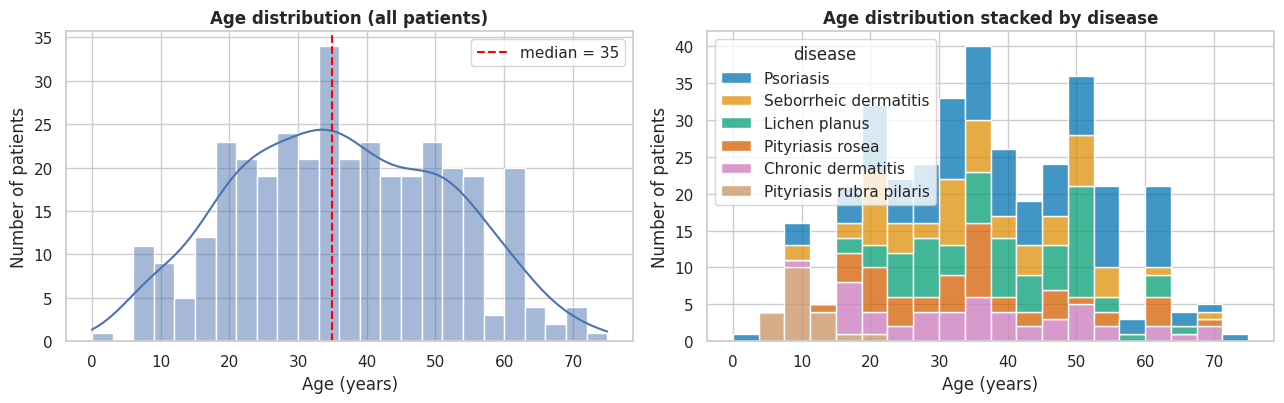

,count,mean,median
disease,,,
Psoriasis,111,39.4,39.0
Seborrheic dermatitis,60,35.5,34.0
Lichen planus,71,40.0,40.0
Pityriasis rosea,48,35.3,35.0
Chronic dermatitis,48,36.7,35.5
Pityriasis rubra pilaris,20,10.2,9.5


**Interpretation.** Age (n=358) has mean 36.3, median 35, SD 15.3 and skewness 0.07. The youngest median age is in **Pityriasis rubra pilaris** (10) and the oldest in **Lichen planus** (40), so Age carries some class information but overlaps heavily.

In [98]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
sns.histplot(eda["Age"].dropna(), bins=25, kde=True, ax=ax[0], color="#4C72B0")
ax[0].axvline(eda["Age"].median(), color="red", ls="--", label=f"median = {eda['Age'].median():.0f}")
ax[0].set(title="Age distribution (all patients)", xlabel="Age (years)", ylabel="Number of patients"); ax[0].legend()
sns.histplot(data=eda.dropna(subset=["Age"]), x="Age", hue="disease", hue_order=order, palette=pal, multiple="stack", bins=20, ax=ax[1])
ax[1].set(title="Age distribution stacked by disease", xlabel="Age (years)", ylabel="Number of patients")
plt.tight_layout(); savefig("01_age_distribution"); plt.show()
g = eda.groupby("disease")["Age"].agg(["count","mean","median"]).round(1).loc[order]
display(g)
yng, old = g["median"].idxmin(), g["median"].idxmax()
obs(f"Age (n={int(eda['Age'].notna().sum())}) has mean {eda['Age'].mean():.1f}, median {eda['Age'].median():.0f}, SD {eda['Age'].std():.1f} and skewness {eda['Age'].skew():.2f}. "
    f"The youngest median age is in **{yng}** ({g.loc[yng,'median']:.0f}) and the oldest in **{old}** ({g.loc[old,'median']:.0f}), so Age carries some class information but overlaps heavily.")

### 8.2 Target distribution

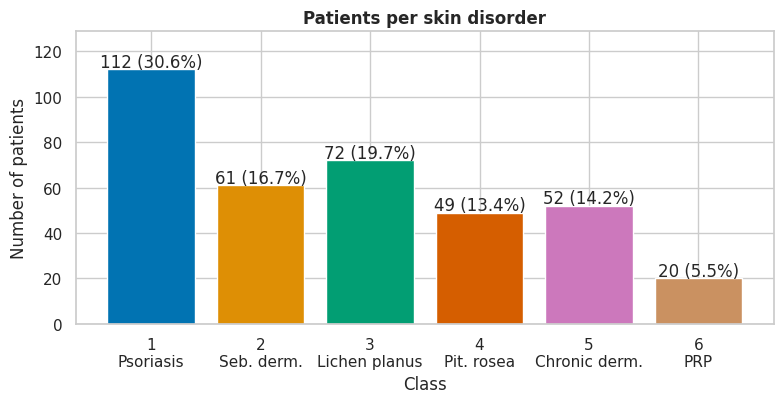

**Interpretation.** Class 1 (Psoriasis) is largest with 112 patients; class 6 (Pityriasis rubra pilaris) is smallest with 20. The imbalance ratio is 5.6:1, so **accuracy alone would hide poor minority-class performance**; macro-F1 and class-wise recall are the primary metrics.

In [99]:
vc = eda["class"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.bar([f"{i}\n{SHORT[i]}" for i in vc.index], vc.values, color=[CLASS_COLORS[i] for i in vc.index])
for b, v in zip(bars, vc.values): ax.text(b.get_x()+b.get_width()/2, v+1, f"{v} ({100*v/len(eda):.1f}%)", ha="center")
ax.set(title="Patients per skin disorder", xlabel="Class", ylabel="Number of patients"); ax.set_ylim(0, vc.max()*1.15)
plt.tight_layout(); savefig("02_target_distribution"); plt.show()
obs(f"Class {vc.idxmax()} ({CLASS_NAMES[vc.idxmax()]}) is largest with {vc.max()} patients; class {vc.idxmin()} ({CLASS_NAMES[vc.idxmin()]}) is smallest with {vc.min()}. "
    f"The imbalance ratio is {vc.max()/vc.min():.1f}:1, so **accuracy alone would hide poor minority-class performance**; macro-F1 and class-wise recall are the primary metrics.")

### 8.3 Correlation heatmap (Spearman, suited to ordinal 0–3 grades)

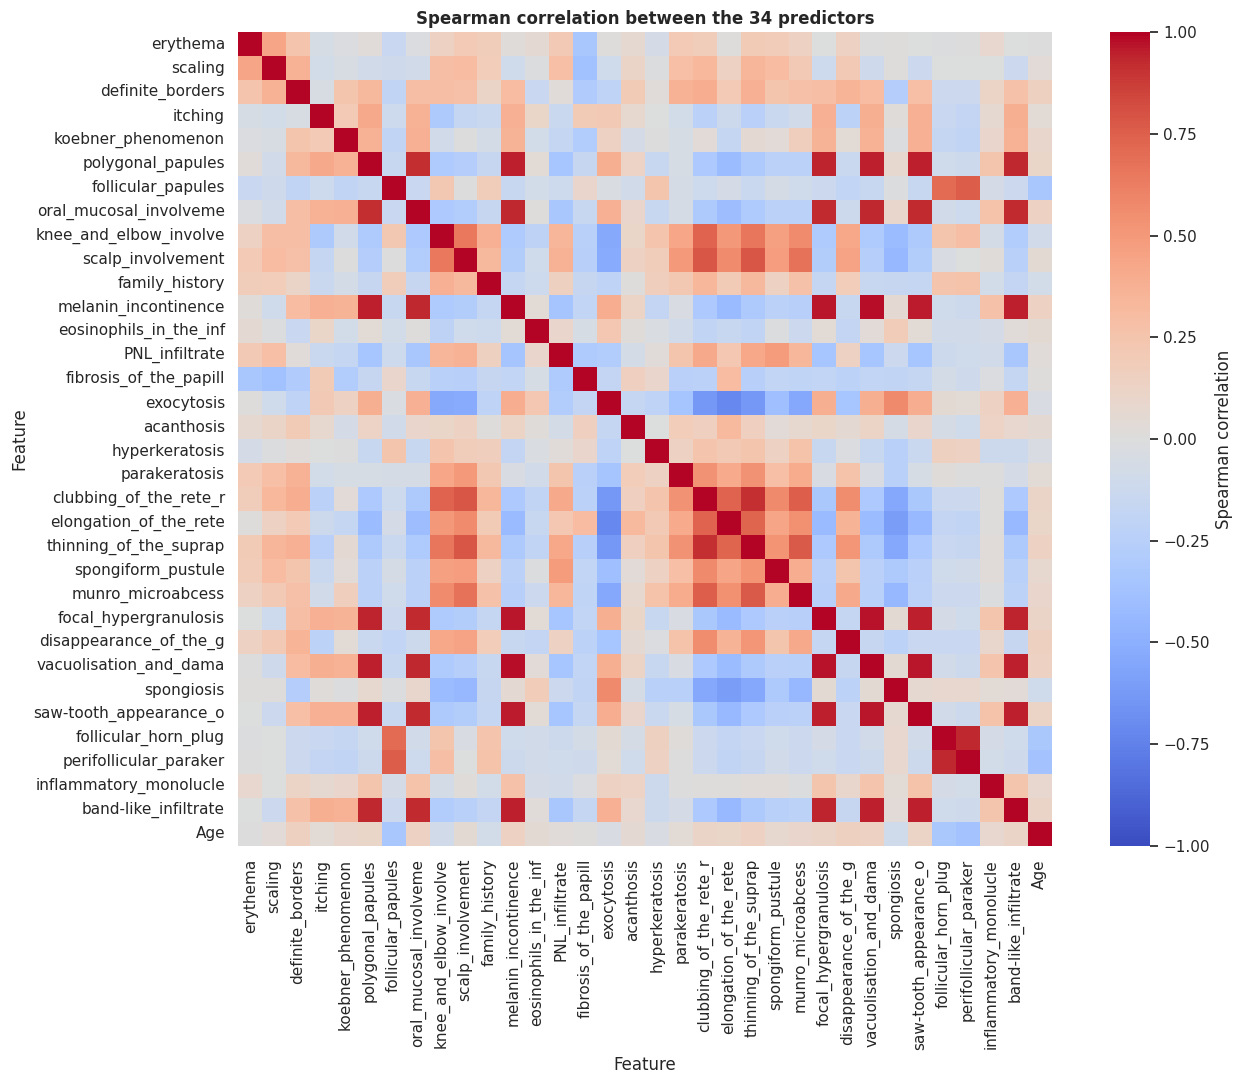

,feature A,feature B,rho
322,melanin_incontinence,vacuolisation_and_damage_of_basal_layer,0.981
517,focal_hypergranulosis,vacuolisation_and_damage_of_basal_layer,0.970
320,melanin_incontinence,focal_hypergranulosis,0.967
534,vacuolisation_and_damage_of_basal_layer,saw-tooth_appearance_of_retes,0.966
324,melanin_incontinence,saw-tooth_appearance_of_retes,0.957
160,polygonal_papules,melanin_incontinence,0.953
519,focal_hypergranulosis,saw-tooth_appearance_of_retes,0.952
538,vacuolisation_and_damage_of_basal_layer,band-like_infiltrate,0.951


**Interpretation.** 33 feature pairs have |ρ| > 0.7. The strongest is **melanin_incontinence ↔ vacuolisation_and_damage_of_basal_layer** (ρ = 0.98). Strongly correlated groups mean the features are partly redundant, which favours regularised or tree-based models and motivates the feature-selection experiments (Section 12).

In [100]:
corr = df[FEATURES].corr(method="spearman")
plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, cbar_kws={"label": "Spearman correlation"},
            xticklabels=[c[:22] for c in corr.columns], yticklabels=[c[:22] for c in corr.columns])
plt.title("Spearman correlation between the 34 predictors"); plt.xlabel("Feature"); plt.ylabel("Feature")
plt.tight_layout(); savefig("03_correlation_heatmap"); plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().rename("rho").reset_index()
pairs["abs"] = pairs["rho"].abs(); top = pairs.sort_values("abs", ascending=False).head(8)
display(top[["level_0","level_1","rho"]].round(3).rename(columns={"level_0":"feature A","level_1":"feature B"}))
n_hi = int((pairs["abs"] > 0.7).sum())
obs(f"{n_hi} feature pairs have |ρ| > 0.7. The strongest is **{top.iloc[0]['level_0']} ↔ {top.iloc[0]['level_1']}** (ρ = {top.iloc[0]['rho']:.2f}). "
    f"Strongly correlated groups mean the features are partly redundant, which favours regularised or tree-based models and motivates the feature-selection experiments (Section 12).")

### 8.4 Box plots

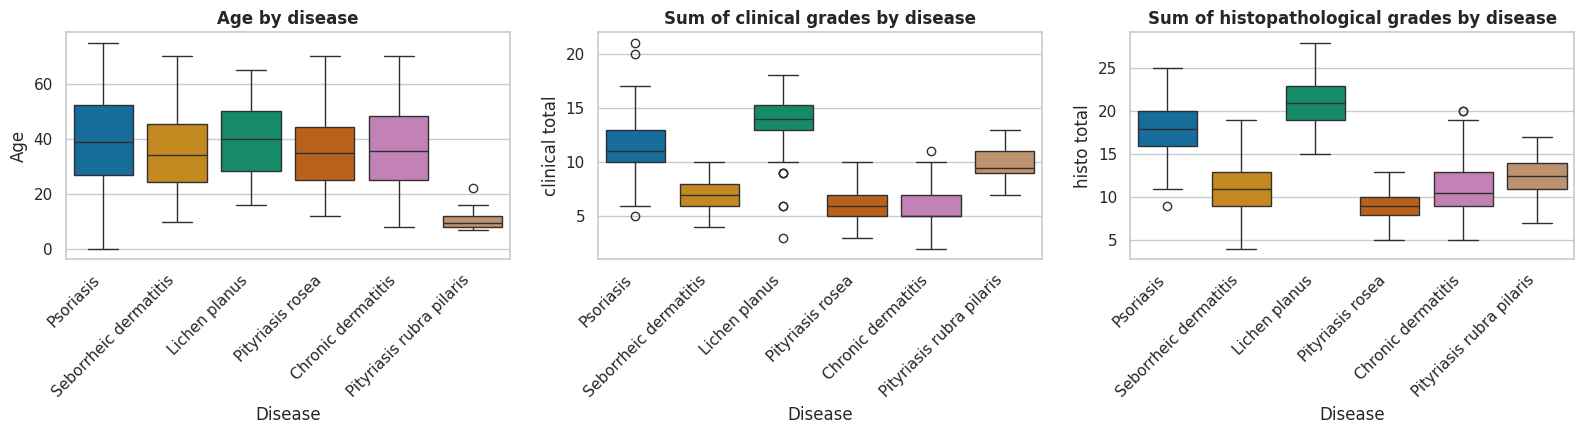

,clinical_total,histo_total
disease,,
Psoriasis,11.0,18.0
Seborrheic dermatitis,7.0,11.0
Lichen planus,14.0,21.0
Pityriasis rosea,6.0,9.0
Chronic dermatitis,5.0,10.5
Pityriasis rubra pilaris,9.5,12.5


**Interpretation.** Median clinical-grade total ranges from 5 (Chronic dermatitis) to 14 (Lichen planus); median histopathological total from 9 (Pityriasis rosea) to 21 (Lichen planus). (Row sums are exploratory summaries, not validated indices.)

In [101]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, col, t in zip(ax, ["Age","clinical_total","histo_total"],
                     ["Age by disease","Sum of clinical grades by disease","Sum of histopathological grades by disease"]):
    sns.boxplot(data=eda, x="disease", y=col, order=order, palette=pal, ax=a)
    a.set(title=t, xlabel="Disease", ylabel=col.replace("_"," ")); a.tick_params(axis="x", rotation=45)
    for lbl in a.get_xticklabels(): lbl.set_ha("right")
plt.tight_layout(); savefig("04_box_plots"); plt.show()
med = eda.groupby("disease")[["clinical_total","histo_total"]].median().loc[order]; display(med)
obs(f"Median clinical-grade total ranges from {med['clinical_total'].min():.0f} ({med['clinical_total'].idxmin()}) to {med['clinical_total'].max():.0f} ({med['clinical_total'].idxmax()}); "
    f"median histopathological total from {med['histo_total'].min():.0f} ({med['histo_total'].idxmin()}) to {med['histo_total'].max():.0f} ({med['histo_total'].idxmax()}). "
    f"(Row sums are exploratory summaries, not validated indices.)")

### 8.5 Violin plots (the four most class-discriminating features by Kruskal–Wallis H; the full test is in Section 9)

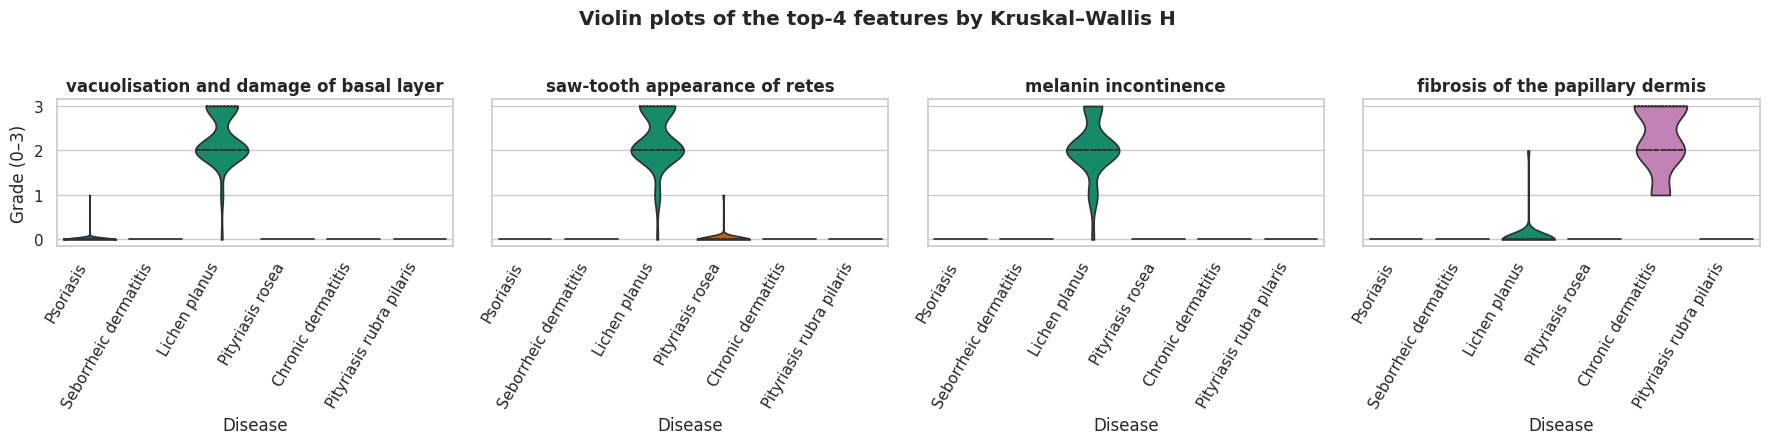

**Interpretation.** Top-4 features: **vacuolisation_and_damage_of_basal_layer** (H=351; highest mean grade in Lichen planus), **saw-tooth_appearance_of_retes** (H=350; highest mean grade in Lichen planus), **melanin_incontinence** (H=349; highest mean grade in Lichen planus), **fibrosis_of_the_papillary_dermis** (H=348; highest mean grade in Chronic dermatitis). Each shows clearly different grade distributions across diseases, but no single feature separates all six classes.

In [102]:
kw_quick = {c: stats.kruskal(*[g[c].values for _, g in df.groupby("class")]).statistic for c in FEATURES if c != "Age"}
top4 = sorted(kw_quick, key=kw_quick.get, reverse=True)[:4]
fig, ax = plt.subplots(1, 4, figsize=(18, 4.3), sharey=True)
for a, c in zip(ax, top4):
    sns.violinplot(data=eda, x="disease", y=c, order=order, palette=pal, ax=a, cut=0, inner="quartile", density_norm="width")
    a.set(title=c.replace("_"," "), xlabel="Disease", ylabel="Grade (0–3)"); a.tick_params(axis="x", rotation=60)
    for lbl in a.get_xticklabels(): lbl.set_ha("right")
plt.suptitle("Violin plots of the top-4 features by Kruskal–Wallis H", y=1.03, fontweight="bold")
plt.tight_layout(); savefig("05_violin_plots"); plt.show()
best_by_class = {c: eda.groupby("disease")[c].mean().idxmax() for c in top4}
obs("Top-4 features: " + ", ".join(f"**{c}** (H={kw_quick[c]:.0f}; highest mean grade in {best_by_class[c]})" for c in top4) +
    ". Each shows clearly different grade distributions across diseases, but no single feature separates all six classes.")

### 8.6 Pair plot

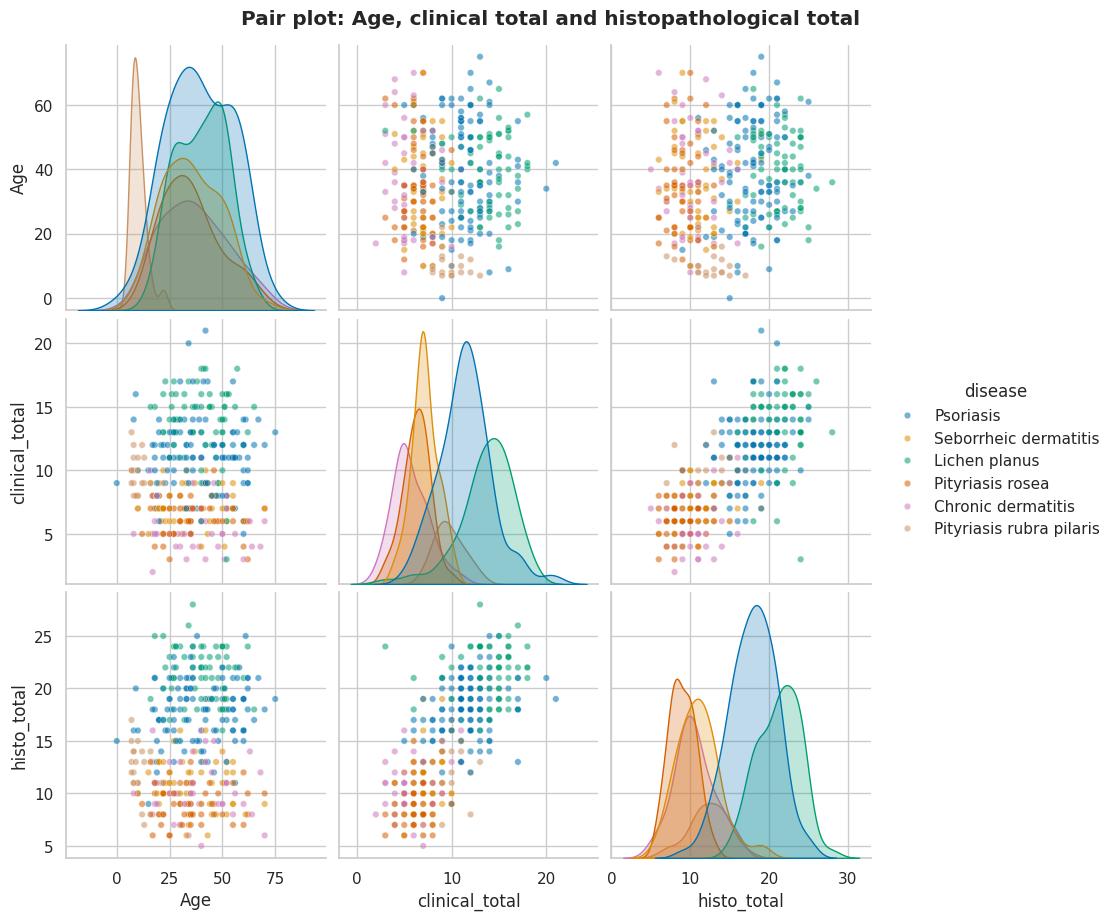

**Interpretation.** The clinical and histopathological totals are correlated (Spearman ρ = 0.73), and the classes form partly separated clusters in the clinical-vs-histopathological plane while overlapping substantially in Age.

In [103]:
pp = sns.pairplot(eda.dropna(subset=["Age"]), vars=["Age","clinical_total","histo_total"], hue="disease", hue_order=order,
                  palette=pal, diag_kind="kde", plot_kws=dict(alpha=.55, s=22), height=3)
pp.fig.suptitle("Pair plot: Age, clinical total and histopathological total", y=1.02, fontweight="bold")
savefig("06_pair_plot"); plt.show()
c_ch = eda[["clinical_total","histo_total"]].corr(method="spearman").iloc[0,1]
obs(f"The clinical and histopathological totals are correlated (Spearman ρ = {c_ch:.2f}), and the classes form partly separated clusters in the "
    f"clinical-vs-histopathological plane while overlapping substantially in Age.")

### 8.7 Stacked class distributions

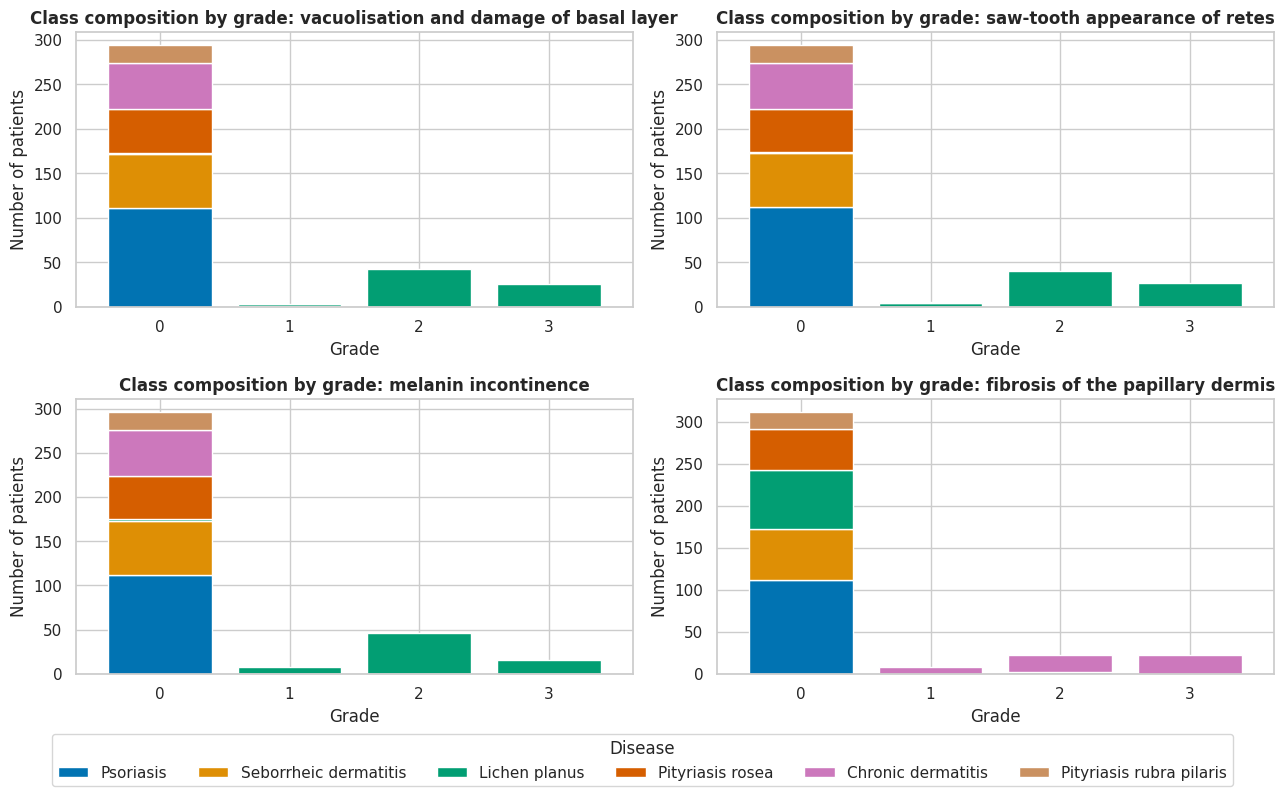

**Interpretation.** For **vacuolisation_and_damage_of_basal_layer**, grade 0 patients: Chronic dermatitis 52, Lichen planus 1, Pityriasis rosea 49, Pityriasis rubra pilaris 20, Psoriasis 111, Seborrheic dermatitis 61; higher grades are dominated by different diseases. Stacked bars show how the disease mix changes with severity grade.

In [104]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for a, c in zip(axes.ravel(), top4):
    ct = pd.crosstab(df[c], df["class"].map(CLASS_NAMES))[order]
    ct.plot(kind="bar", stacked=True, ax=a, color=[pal[o] for o in order], width=.8, legend=False)
    a.set(title=f"Class composition by grade: {c.replace('_',' ')}", xlabel="Grade", ylabel="Number of patients"); a.tick_params(axis="x", rotation=0)
h, l = axes[0,0].get_legend_handles_labels(); fig.legend(h, l, loc="lower center", ncol=6, title="Disease")
plt.tight_layout(rect=[0,.06,1,1]); savefig("07_stacked_class_distributions"); plt.show()
c0 = top4[0]; ct0 = pd.crosstab(df[c0], df["class"].map(CLASS_NAMES))
obs(f"For **{c0}**, grade 0 patients: " + ", ".join(f"{k} {v}" for k, v in ct0.loc[0].items() if v) + "; higher grades are dominated by different diseases. "
    "Stacked bars show how the disease mix changes with severity grade.")

### 8.8 Feature distributions

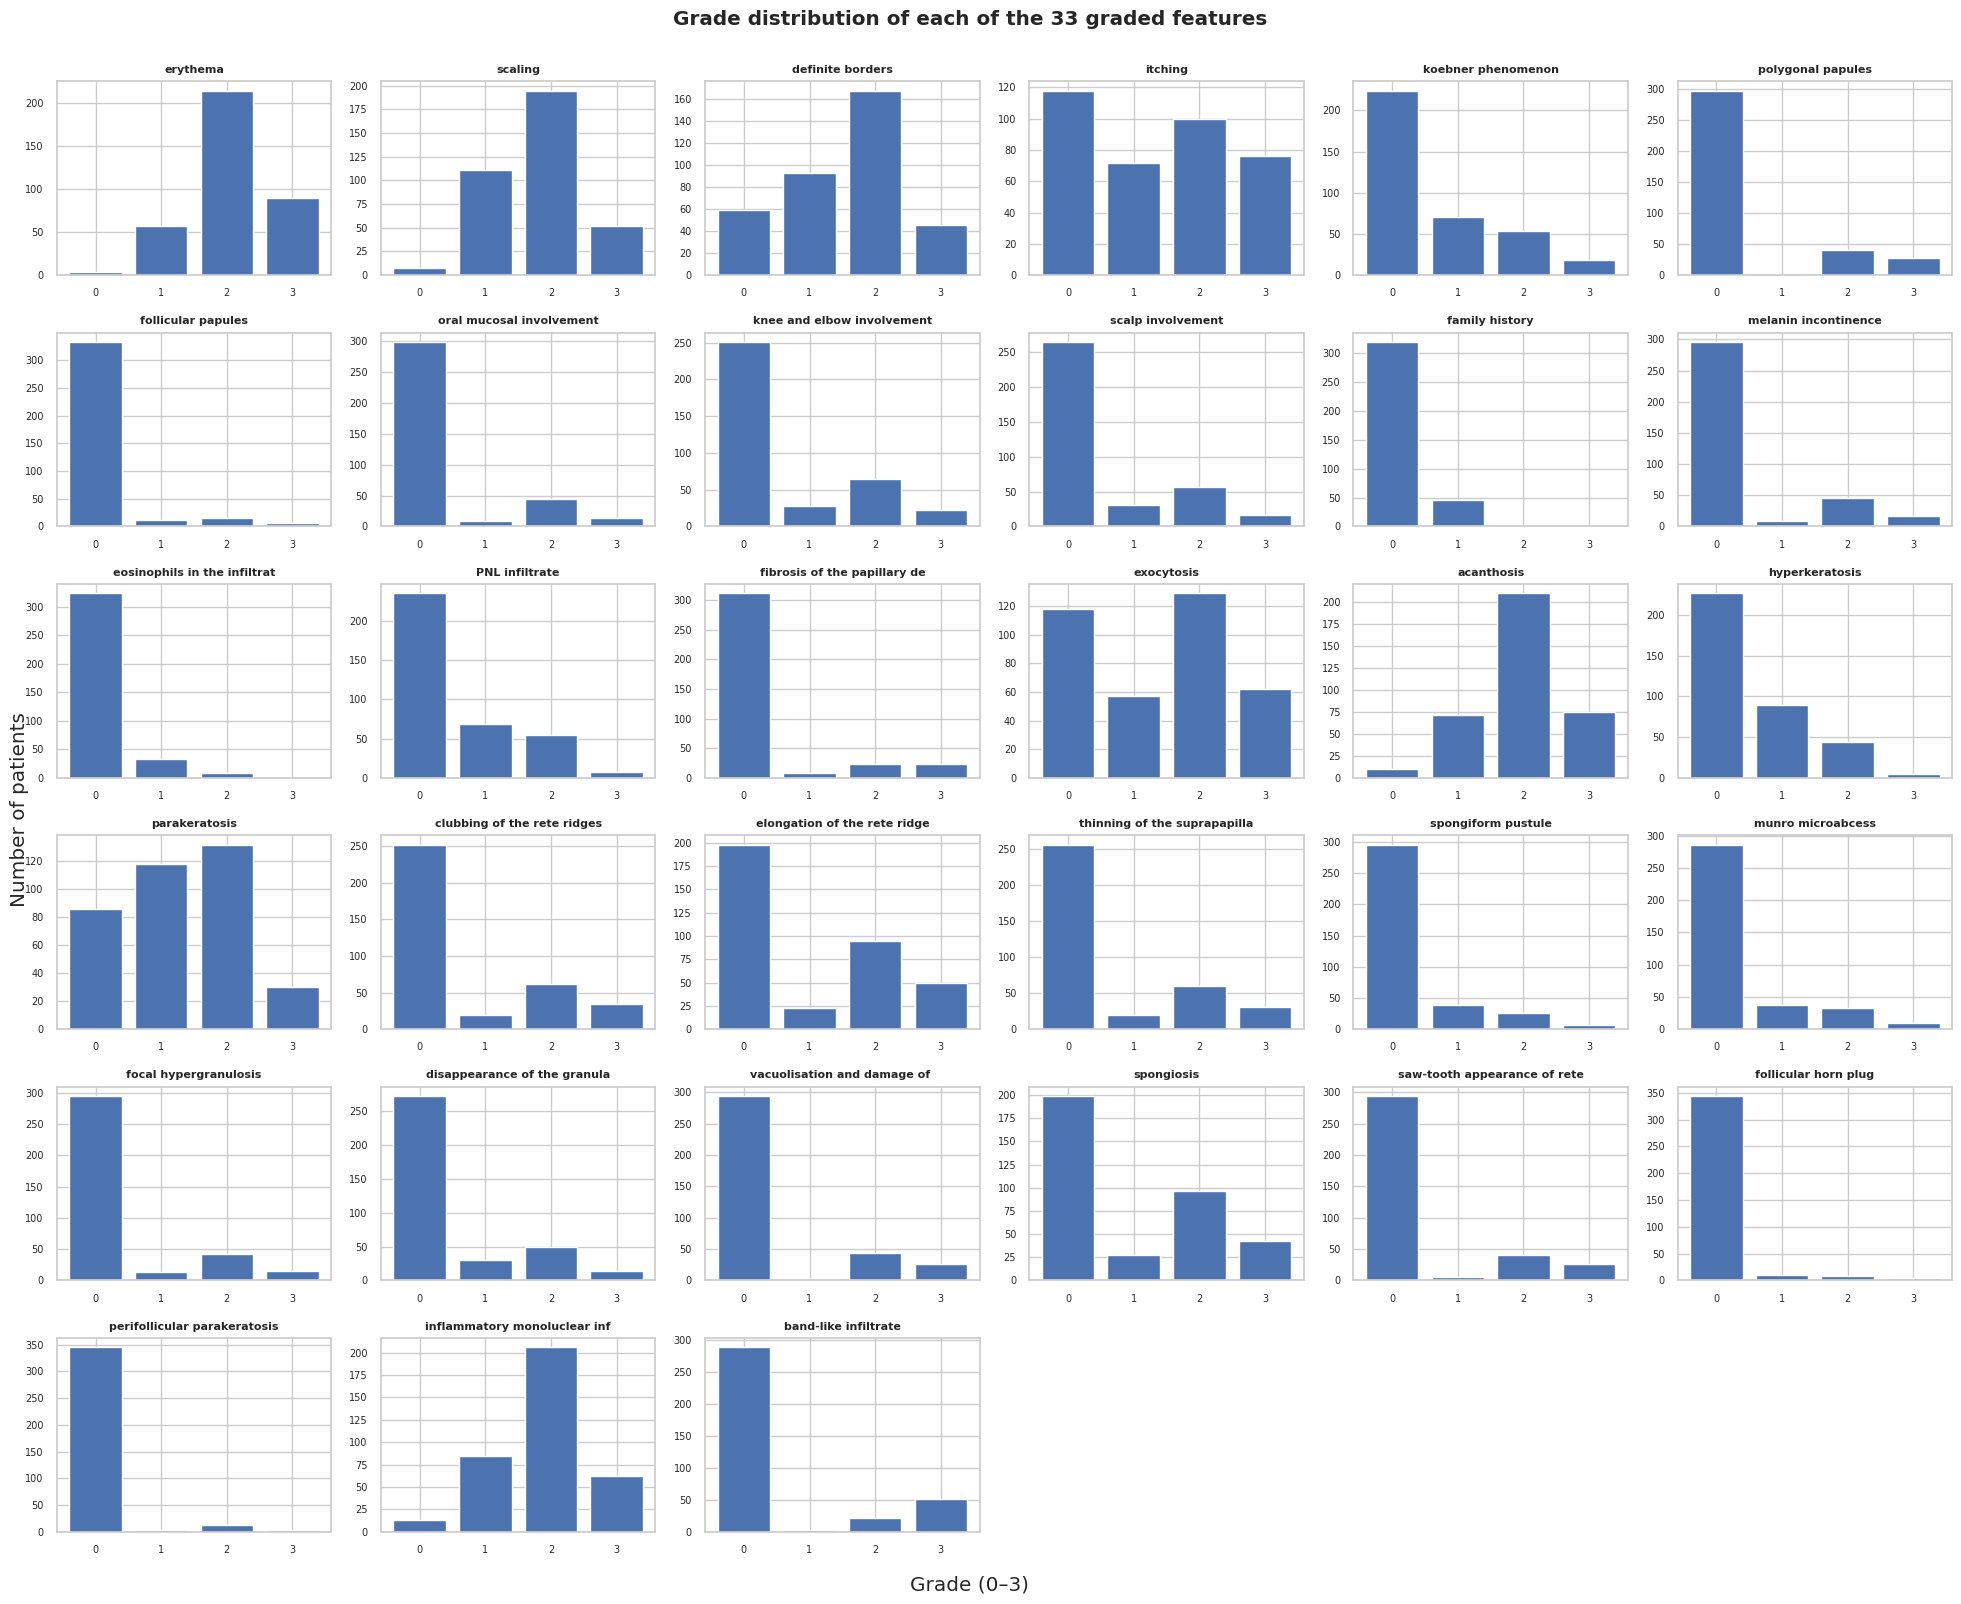

**Interpretation.** Most graded features are zero-inflated: 25 of 33 features are 0 in more than half of patients (most extreme: perifollicular_parakeratosis at 94% zeros). These are ordinal, not continuous, variables.

In [105]:
fig, axes = plt.subplots(6, 6, figsize=(20, 16))
for a, c in zip(axes.ravel(), [f for f in FEATURES if f != "Age"]):
    vcn = df[c].value_counts().reindex(range(4), fill_value=0)
    a.bar(vcn.index, vcn.values, color="#4C72B0"); a.set_title(c.replace("_"," ")[:28], fontsize=8)
    a.set_xticks(range(4)); a.tick_params(labelsize=7)
for a in axes.ravel()[33:]: a.axis("off")
fig.supxlabel("Grade (0–3)"); fig.supylabel("Number of patients")
plt.suptitle("Grade distribution of each of the 33 graded features", y=1.0, fontweight="bold")
plt.tight_layout(); savefig("08_feature_distributions"); plt.show()
zero_share = (df[[f for f in FEATURES if f!="Age"]] == 0).mean().sort_values(ascending=False)
obs(f"Most graded features are zero-inflated: {int((zero_share>0.5).sum())} of 33 features are 0 in more than half of patients "
    f"(most extreme: {zero_share.index[0]} at {100*zero_share.iloc[0]:.0f}% zeros). These are ordinal, not continuous, variables.")

### 8.9 Missing-value analysis

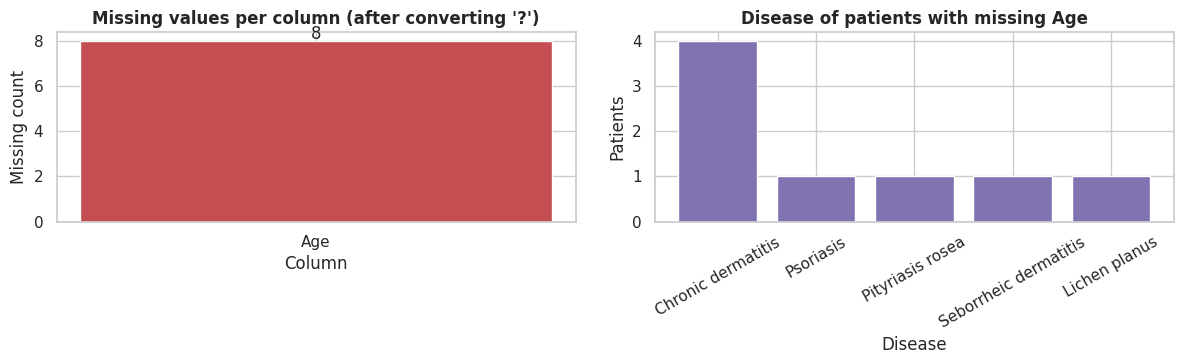

**Interpretation.** Only **Age** is missing (8 of 366 patients = 2.2%). The affected patients belong to: {'Chronic dermatitis': 4, 'Psoriasis': 1, 'Pityriasis rosea': 1, 'Seborrheic dermatitis': 1, 'Lichen planus': 1}. With so few missing values spread over classes, median imputation (inside the pipeline) is appropriate.

In [106]:
miss = df.isnull().sum(); miss = miss[miss > 0]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].bar(miss.index, miss.values, color="#C44E52"); ax[0].set(title="Missing values per column (after converting '?')", xlabel="Column", ylabel="Missing count")
for i, v in enumerate(miss.values): ax[0].text(i, v+.1, str(v), ha="center")
mc = df.loc[df["Age"].isnull(), "class"].map(CLASS_NAMES).value_counts()
ax[1].bar(mc.index, mc.values, color="#8172B2"); ax[1].set(title="Disease of patients with missing Age", xlabel="Disease", ylabel="Patients"); ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); savefig("09_missing_values"); plt.show()
obs(f"Only **Age** is missing ({int(miss['Age'])} of {len(df)} patients = {100*miss['Age']/len(df):.1f}%). "
    f"The affected patients belong to: {mc.to_dict()}. With so few missing values spread over classes, median imputation (inside the pipeline) is appropriate.")

### 8.10 Feature frequency

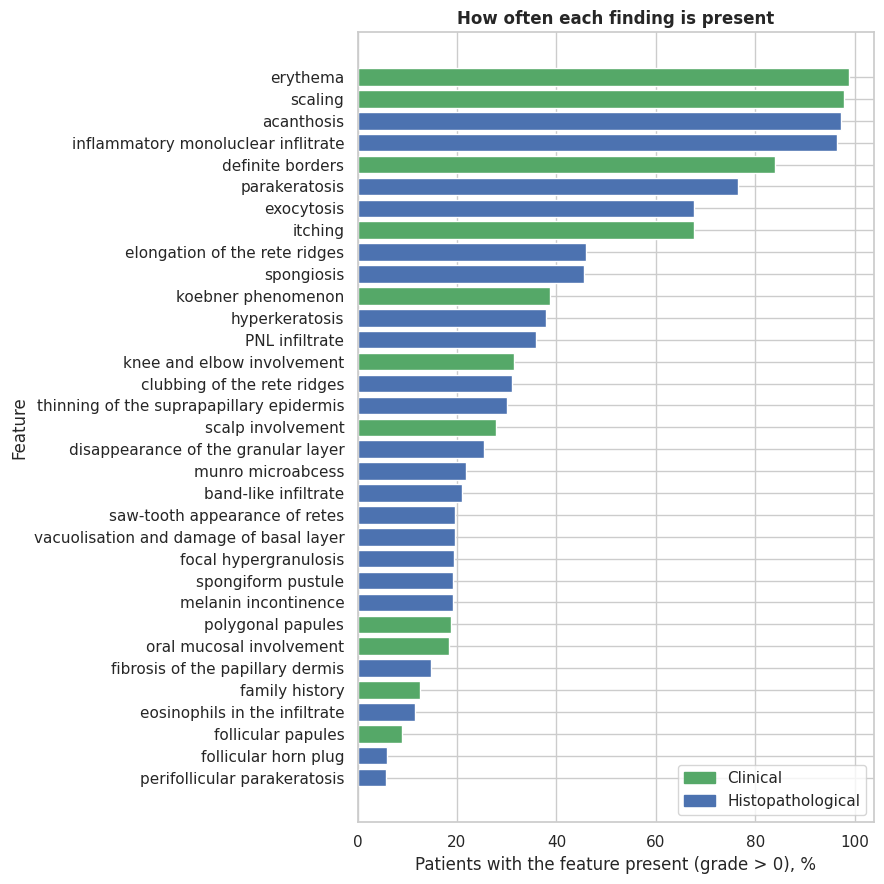

**Interpretation.** Most frequent finding: **erythema** (99% of patients); rarest: **perifollicular_parakeratosis** (6%). Rare findings are highly specific when present, but give a model few examples to learn from.

In [107]:
present = (df[[f for f in FEATURES if f!="Age"]] > 0).mean().sort_values()*100
plt.figure(figsize=(9, 9)); colors = ["#55A868" if i in CLINICAL else "#4C72B0" for i in present.index]
plt.barh([i.replace("_"," ") for i in present.index], present.values, color=colors)
plt.xlabel("Patients with the feature present (grade > 0), %"); plt.ylabel("Feature")
plt.title("How often each finding is present");
from matplotlib.patches import Patch
plt.legend(handles=[Patch(color="#55A868", label="Clinical"), Patch(color="#4C72B0", label="Histopathological")], loc="lower right")
plt.tight_layout(); savefig("10_feature_frequency"); plt.show()
obs(f"Most frequent finding: **{present.index[-1]}** ({present.iloc[-1]:.0f}% of patients); rarest: **{present.index[0]}** ({present.iloc[0]:.0f}%). "
    f"Rare findings are highly specific when present, but give a model few examples to learn from.")

### 8.11 Multivariate analysis (PCA projection)

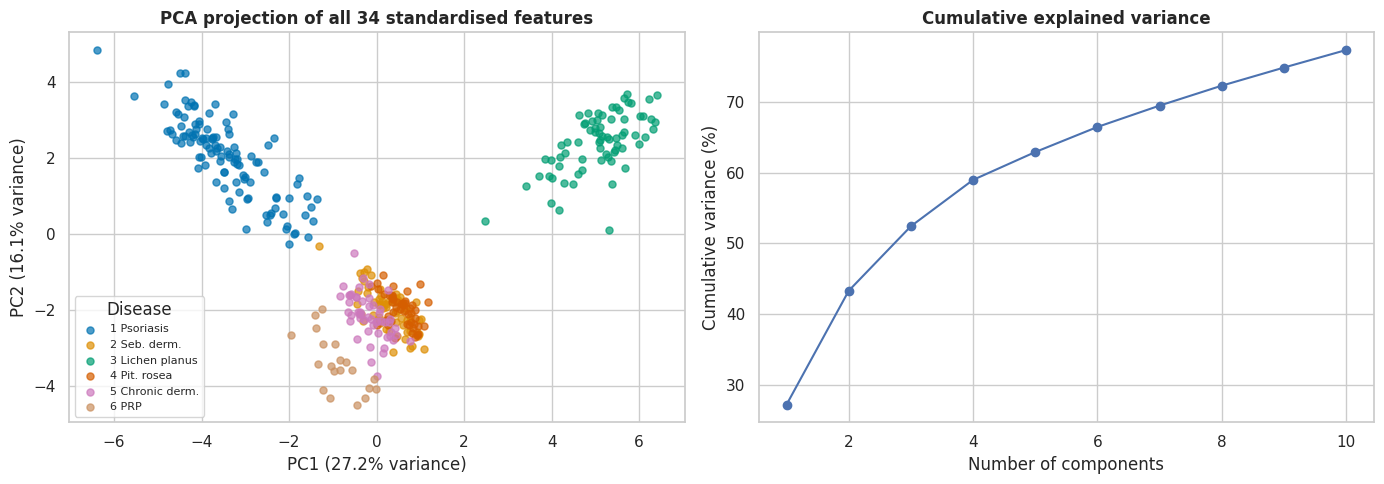

**Interpretation.** The first two components explain 43.3% of the variance and the first 10 explain 77.4%. Classes form visible groups, with some overlap between neighbouring diseases.

In [108]:
from sklearn.decomposition import PCA
Xs = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(df[FEATURES]))
pca = PCA(n_components=10, random_state=SEED).fit(Xs); Z = pca.transform(Xs)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for c in range(1, 7):
    m = (df["class"] == c).values; ax[0].scatter(Z[m,0], Z[m,1], s=26, alpha=.7, color=CLASS_COLORS[c], label=f"{c} {SHORT[c]}")
ax[0].set(title="PCA projection of all 34 standardised features", xlabel=f"PC1 ({100*pca.explained_variance_ratio_[0]:.1f}% variance)", ylabel=f"PC2 ({100*pca.explained_variance_ratio_[1]:.1f}% variance)"); ax[0].legend(title="Disease", fontsize=8)
ax[1].plot(range(1, 11), np.cumsum(pca.explained_variance_ratio_)*100, "o-"); ax[1].set(title="Cumulative explained variance", xlabel="Number of components", ylabel="Cumulative variance (%)")
plt.tight_layout(); savefig("11_multivariate_pca"); plt.show()
obs(f"The first two components explain {100*pca.explained_variance_ratio_[:2].sum():.1f}% of the variance and the first 10 explain {100*pca.explained_variance_ratio_.sum():.1f}%. "
    f"Classes form visible groups, with some overlap between neighbouring diseases.")

### 8.12 Class-wise feature profile

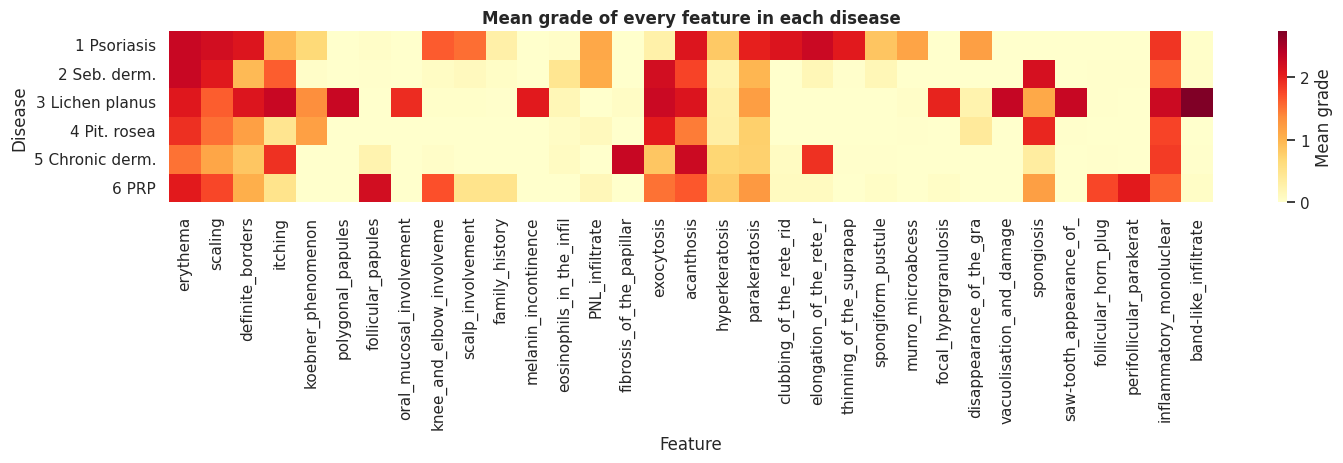

**Interpretation.** Highest mean grades per disease: <br>**Psoriasis** – erythema (2.3), elongation_of_the_rete_ridges (2.3), scaling (2.2)<br>**Seborrheic dermatitis** – erythema (2.3), exocytosis (2.2), spongiosis (2.2)<br>**Lichen planus** – band-like_infiltrate (2.7), vacuolisation_and_damage_of_basal_layer (2.3), saw-tooth_appearance_of_retes (2.3)<br>**Pityriasis rosea** – exocytosis (2.0), spongiosis (2.0), erythema (1.9)<br>**Chronic dermatitis** – fibrosis_of_the_papillary_dermis (2.3), acanthosis (2.2), itching (1.9)<br>**Pityriasis rubra pilaris** – follicular_papules (2.2), erythema (2.0), perifollicular_parakeratosis (2.0)

In [109]:
prof = df.groupby("class")[[f for f in FEATURES if f!="Age"]].mean(); prof.index = [f"{i} {SHORT[i]}" for i in prof.index]
plt.figure(figsize=(15, 4.8))
sns.heatmap(prof, cmap="YlOrRd", annot=False, cbar_kws={"label": "Mean grade"}, xticklabels=[c[:24] for c in prof.columns])
plt.title("Mean grade of every feature in each disease"); plt.xlabel("Feature"); plt.ylabel("Disease")
plt.tight_layout(); savefig("12_class_profiles"); plt.show()
lines = []
for i in range(1, 7):
    t = df.groupby("class")[[f for f in FEATURES if f!="Age"]].mean().loc[i].sort_values(ascending=False).head(3)
    lines.append(f"**{CLASS_NAMES[i]}** – " + ", ".join(f"{k} ({v:.1f})" for k, v in t.items()))
obs("Highest mean grades per disease: <br>" + "<br>".join(lines))

## 9. Statistical analysis and hypothesis testing
**Research question:** do clinical and histopathological feature distributions differ between the six classes?

* Kruskal–Wallis H test per feature (ordinal / non-normal data) with effect size ε² = H / (n − 1).
* Chi-square test of independence per graded feature vs class with Cramér's V. Many contingency tables have small expected counts, so chi-square p-values are approximate; Cramér's V and Kruskal–Wallis are read as the primary evidence.
* Holm correction across the tests (α = 0.05). Association ≠ causation.

In [110]:
from statsmodels.stats.multitest import multipletests
d9 = df.copy(); res = []
for c in FEATURES:
    sub = d9[[c, "class"]].dropna()
    groups = [g[c].values for _, g in sub.groupby("class")]
    H, p = stats.kruskal(*groups); eps2 = H/(len(sub)-1)
    row = dict(feature=c, group=("Clinical" if c in CLINICAL else "Histopathological" if c in HISTO else "Demographic"),
               median_overall=sub[c].median(), mean=sub[c].mean(), std=sub[c].std(), H=H, p_kw=p, epsilon2=eps2)
    if c != "Age":
        ct = pd.crosstab(sub[c], sub["class"]); chi2, pc, dof, _ = stats.chi2_contingency(ct)
        row.update(chi2=chi2, p_chi2=pc, cramers_v=np.sqrt(chi2/(len(sub)*(min(ct.shape)-1))))
    res.append(row)
tests = pd.DataFrame(res)
tests["p_kw_holm"] = multipletests(tests["p_kw"], method="holm")[1]
m = tests["p_chi2"].notna(); tests.loc[m, "p_chi2_holm"] = multipletests(tests.loc[m, "p_chi2"], method="holm")[1]
tests = tests.sort_values("epsilon2", ascending=False).reset_index(drop=True)
tests.to_csv(f"{EVAL_DIR}/statistical_tests.csv", index=False)
display(tests.round(4).head(15))
n_sig = int((tests["p_kw_holm"] < 0.05).sum()); n_chi = int((tests["p_chi2_holm"] < 0.05).sum())
print(f"Kruskal-Wallis significant after Holm: {n_sig}/{len(tests)}; chi-square significant: {n_chi}/{m.sum()}")
print("Not significant (KW, Holm):", tests.loc[tests["p_kw_holm"] >= 0.05, "feature"].tolist())

,feature,group,median_overall,mean,std,H,p_kw,epsilon2,chi2,p_chi2,cramers_v,p_kw_holm,p_chi2_holm
0,vacuolisation_and_damage_of_basal_layer,Histopathological,0.0,0.4563,0.9549,350.6861,0.0,0.9608,356.1557,0.0,0.5695,0.0,0.0
1,saw-tooth_appearance_of_retes,Histopathological,0.0,0.4536,0.9547,350.4687,0.0,0.9602,355.8968,0.0,0.5693,0.0,0.0
2,melanin_incontinence,Histopathological,0.0,0.4044,0.8698,348.7680,0.0,0.9555,353.4291,0.0,0.5673,0.0,0.0
3,fibrosis_of_the_papillary_dermis,Histopathological,0.0,0.3361,0.8531,348.3505,0.0,0.9544,351.7502,0.0,0.5660,0.0,0.0
4,perifollicular_parakeratosis,Histopathological,0.0,0.1148,0.4887,348.2472,0.0,0.9541,352.7315,0.0,0.5668,0.0,0.0
5,focal_hypergranulosis,Histopathological,0.0,0.3934,0.8494,344.3284,0.0,0.9434,348.9576,0.0,0.5637,0.0,0.0
6,polygonal_papules,Clinical,0.0,0.4481,0.9573,342.6056,0.0,0.9386,347.2071,0.0,0.5623,0.0,0.0
7,band-like_infiltrate,Histopathological,0.0,0.5546,1.1059,341.7622,0.0,0.9363,360.5358,0.0,0.5730,0.0,0.0
8,oral_mucosal_involvement,Clinical,0.0,0.3770,0.8341,330.8636,0.0,0.9065,334.8880,0.0,0.5523,0.0,0.0
9,thinning_of_the_suprapapillary_epidermis,Histopathological,0.0,0.6339,1.0349,330.3482,0.0,0.9051,339.4441,0.0,0.5560,0.0,0.0


Kruskal-Wallis significant after Holm: 34/34; chi-square significant: 33/33
Not significant (KW, Holm): []


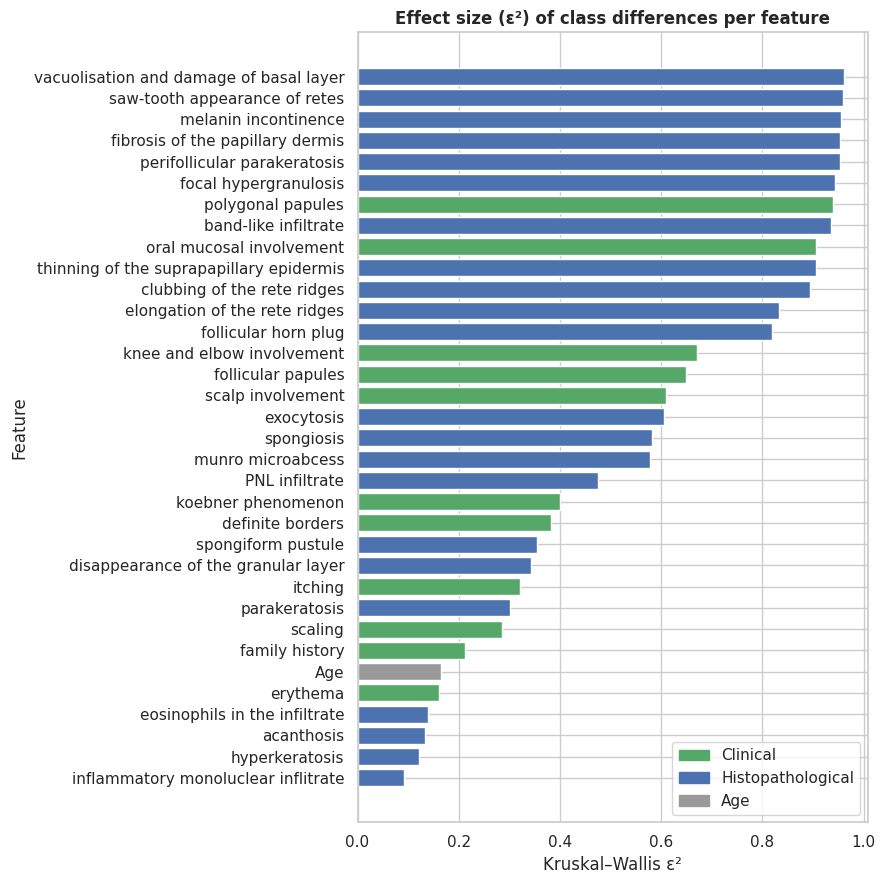

**Interpretation.** **34 of 34** features differ significantly across the six classes after Holm correction. Mean ε² is 0.50 for clinical vs 0.63 for histopathological features. Largest effects: vacuolisation_and_damage_of_basal_layer (ε²=0.96), saw-tooth_appearance_of_retes (ε²=0.96), melanin_incontinence (ε²=0.96), fibrosis_of_the_papillary_dermis (ε²=0.95), perifollicular_parakeratosis (ε²=0.95). These are associations, not causal statements, and with n=366 the tests are descriptive rather than diagnostic criteria.

In [111]:
fig, ax = plt.subplots(figsize=(9, 9)); t = tests.sort_values("epsilon2")
ax.barh([f.replace("_"," ") for f in t["feature"]], t["epsilon2"], color=["#55A868" if g=="Clinical" else "#4C72B0" if g=="Histopathological" else "#999" for g in t["group"]])
ax.set(title="Effect size (ε²) of class differences per feature", xlabel="Kruskal–Wallis ε²", ylabel="Feature")
ax.legend(handles=[Patch(color="#55A868", label="Clinical"), Patch(color="#4C72B0", label="Histopathological"), Patch(color="#999", label="Age")], loc="lower right")
plt.tight_layout(); savefig("13_effect_sizes"); plt.show()
eff_cl = tests[tests.group=="Clinical"]; eff_hi = tests[tests.group=="Histopathological"]
obs(f"**{n_sig} of {len(tests)}** features differ significantly across the six classes after Holm correction. Mean ε² is {eff_cl['epsilon2'].mean():.2f} for clinical vs {eff_hi['epsilon2'].mean():.2f} for histopathological features. "
    f"Largest effects: " + ", ".join(f"{r.feature} (ε²={r.epsilon2:.2f})" for r in tests.head(5).itertuples()) + ". "
    "These are associations, not causal statements, and with n=366 the tests are descriptive rather than diagnostic criteria.")

## 10. Clinical vs histopathological feature analysis
Three experiments, all on the **training split only**, using the same 5×3 repeated stratified CV and two representative models (Logistic Regression with scaling, Random Forest):

* **A** – 11 clinical features · **B** – 22 histopathological features · **C** – all 34 predictors.

Cross-validation objects are defined once here and reused in all later sections.

In [112]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

cv5  = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rcv  = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
rcv2 = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED+1)   # independent splits, used to re-check tuned models

def lr_pipe(**kw):
    return Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()),
                     ("clf", LogisticRegression(max_iter=3000, random_state=SEED, **kw))])
def rf_pipe(**kw):
    return Pipeline([("imp", SimpleImputer(strategy="median")),
                     ("clf", RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=2, **kw))])

sets = {"A: Clinical (11)": CLINICAL, "B: Histopathological (22)": HISTO, "C: Combined (34)": FEATURES}
rows, recalls = [], {}
for name, cols in sets.items():
    for mname, mk in [("LogReg", lr_pipe), ("RandomForest", rf_pipe)]:
        r = cross_validate(mk(), X_train[cols], y_train_enc, cv=rcv, scoring=["f1_macro","accuracy","balanced_accuracy"])
        rows.append(dict(feature_set=name, model=mname, macro_f1=r["test_f1_macro"].mean(), macro_f1_sd=r["test_f1_macro"].std(),
                         accuracy=r["test_accuracy"].mean(), balanced_acc=r["test_balanced_accuracy"].mean()))
    pred = cross_val_predict(rf_pipe(), X_train[cols], y_train_enc, cv=cv5)
    recalls[name] = recall_score(y_train_enc, pred, average=None)
exp = pd.DataFrame(rows); display(exp.round(4))
rec = pd.DataFrame(recalls, index=[f"{i} {SHORT[i]}" for i in range(1, 7)]).T; display(rec.round(3))
exp.to_csv(f"{EVAL_DIR}/experiment_ABC.csv", index=False)

,feature_set,model,macro_f1,macro_f1_sd,accuracy,balanced_acc
0,A: Clinical (11),LogReg,0.8738,0.0321,0.8823,0.8764
1,A: Clinical (11),RandomForest,0.8471,0.0585,0.8732,0.8347
2,B: Histopathological (22),LogReg,0.9436,0.0240,0.9498,0.9452
3,B: Histopathological (22),RandomForest,0.9467,0.0272,0.9555,0.9443
4,C: Combined (34),LogReg,0.9703,0.0200,0.9738,0.9698
5,C: Combined (34),RandomForest,0.9669,0.0258,0.9737,0.9631


,1 Psoriasis,2 Seb. derm.,3 Lichen planus,4 Pit. rosea,5 Chronic derm.,6 PRP
A: Clinical (11),0.955,0.816,0.965,0.821,0.69,0.750
B: Histopathological (22),1.000,0.837,1.000,0.923,1.00,0.938
C: Combined (34),1.000,0.939,1.000,0.897,1.00,0.938


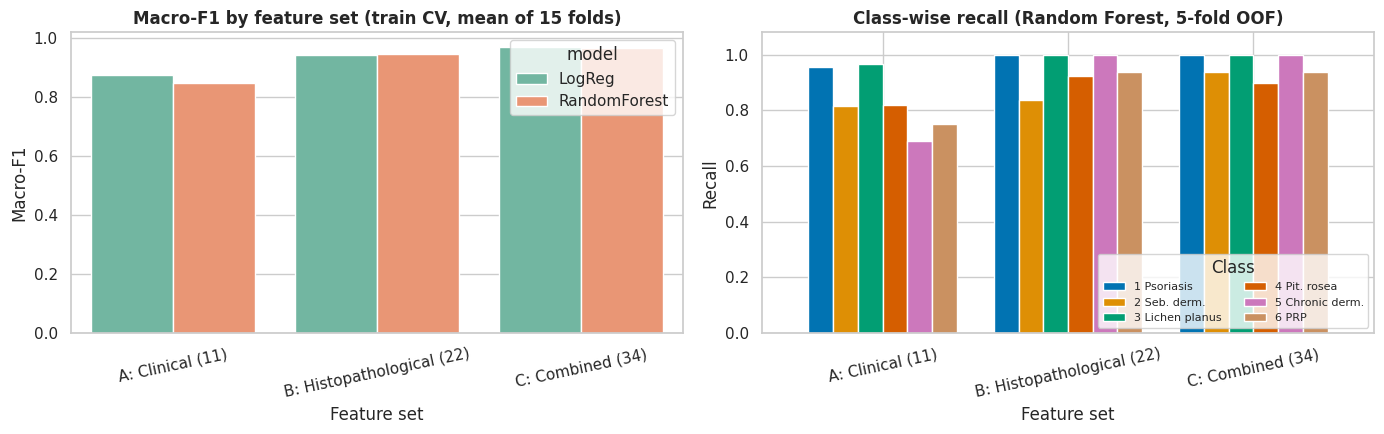

**Interpretation.** Mean macro-F1: clinical only **0.860**, histopathological only **0.945**, combined **0.969**. With clinical features alone the weakest class is *5 Chronic derm.* (recall 0.69). This quantifies how much the biopsy findings add on top of the clinical examination in this dataset.

In [113]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(data=exp, x="feature_set", y="macro_f1", hue="model", ax=ax[0], palette="Set2")
ax[0].set(title="Macro-F1 by feature set (train CV, mean of 15 folds)", xlabel="Feature set", ylabel="Macro-F1", ylim=(0, 1.02)); ax[0].tick_params(axis="x", rotation=12)
rec.plot(kind="bar", ax=ax[1], color=[CLASS_COLORS[i] for i in range(1, 7)], width=.8); ax[1].set(title="Class-wise recall (Random Forest, 5-fold OOF)", xlabel="Feature set", ylabel="Recall", ylim=(0, 1.08))
ax[1].legend(title="Class", fontsize=8, ncol=2, loc="lower right"); ax[1].tick_params(axis="x", rotation=12)
plt.tight_layout(); savefig("14_clinical_vs_histo"); plt.show()
g = exp.groupby("feature_set")["macro_f1"].mean()
worst_cls = rec.loc["A: Clinical (11)"].idxmin()
obs(f"Mean macro-F1: clinical only **{g.iloc[0]:.3f}**, histopathological only **{g.iloc[1]:.3f}**, combined **{g.iloc[2]:.3f}**. "
    f"With clinical features alone the weakest class is *{worst_cls}* (recall {rec.loc['A: Clinical (11)'].min():.2f}). "
    f"This quantifies how much the biopsy findings add on top of the clinical examination in this dataset.")

## 11. Feature engineering
Deterministic, row-wise transformations only (no fitting ⇒ no leakage):

1. `clinical_total`, `histo_total` – sums of graded findings (exploratory summaries, **not validated medical scores**).
2. Grouping by histological pattern: epidermal (acanthosis, hyperkeratosis, parakeratosis, rete-ridge changes, granular layer, spongiosis…) vs dermal/infiltrate groups.
3. `age_group` – fixed cut-points (<18, 18–34, 35–49, ≥50).
4. Interaction investigation: products of the top-ranked features.
5. Standardisation – applied inside pipelines for scale-sensitive models.

We keep engineered features only if cross-validation shows a real gain.

In [114]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import FunctionTransformer

EPIDERMAL = ["acanthosis","hyperkeratosis","parakeratosis","clubbing_of_the_rete_ridges","elongation_of_the_rete_ridges",
             "thinning_of_the_suprapapillary_epidermis","focal_hypergranulosis","disappearance_of_the_granular_layer","spongiosis",
             "saw-tooth_appearance_of_retes","spongiform_pustule","munro_microabcess"]
DERMAL = ["melanin_incontinence","eosinophils_in_the_infiltrate","PNL_infiltrate","fibrosis_of_the_papillary_dermis","exocytosis",
          "inflammatory_monoluclear_inflitrate","band-like_infiltrate","vacuolisation_and_damage_of_basal_layer"]
FOLLICULAR = ["follicular_horn_plug","perifollicular_parakeratosis","follicular_papules"]

def add_features(Xin):
    Z = Xin.copy()
    Z["clinical_total"] = Z[[c for c in CLINICAL if c != "family_history"]].sum(axis=1)
    Z["histo_total"] = Z[HISTO].sum(axis=1)
    Z["epidermal_total"] = Z[EPIDERMAL].sum(axis=1)
    Z["dermal_total"] = Z[DERMAL].sum(axis=1)
    Z["follicular_total"] = Z[FOLLICULAR].sum(axis=1)
    Z["age_group"] = pd.cut(Z["Age"], [-1, 17, 34, 49, 200], labels=False).astype(float)   # NaN stays NaN
    return Z

# interaction candidates: top-6 features by mutual information on TRAIN only
imp_tmp = SimpleImputer(strategy="median").fit(X_train)
Xtr_imp = pd.DataFrame(imp_tmp.transform(X_train), columns=FEATURES, index=X_train.index)
DISC = [f != "Age" for f in FEATURES]   # graded 0-3 features are discrete; Age is treated as continuous
mi_tr = pd.Series(mutual_info_classif(Xtr_imp, y_train_enc, discrete_features=DISC, random_state=SEED), index=FEATURES).sort_values(ascending=False)
top6 = mi_tr.index[:6].tolist(); print("Top-6 by mutual information (train):", top6)
import itertools
def add_interactions(Xin):
    Z = add_features(Xin)
    for a, b in itertools.combinations(top6, 2): Z[f"{a[:10]}*{b[:10]}"] = Z[a]*Z[b]
    return Z

variants = {"Original 34": lambda Z: Z, "+ totals & groups & age_group": add_features, "+ pairwise interactions of top-6": add_interactions}
rows = []
for vn, fn in variants.items():
    Xv = fn(X_train)
    for mname, mk in [("LogReg", lr_pipe), ("RandomForest", rf_pipe)]:
        r = cross_validate(mk(), Xv, y_train_enc, cv=rcv, scoring="f1_macro")
        rows.append(dict(variant=vn, n_features=Xv.shape[1], model=mname, macro_f1=r["test_score"].mean(), sd=r["test_score"].std()))
fe = pd.DataFrame(rows); display(fe.round(4)); fe.to_csv(f"{EVAL_DIR}/feature_engineering.csv", index=False)

Top-6 by mutual information (train): ['elongation_of_the_rete_ridges', 'clubbing_of_the_rete_ridges', 'thinning_of_the_suprapapillary_epidermis', 'vacuolisation_and_damage_of_basal_layer', 'band-like_infiltrate', 'melanin_incontinence']


,variant,n_features,model,macro_f1,sd
0,Original 34,34,LogReg,0.9703,0.0200
1,Original 34,34,RandomForest,0.9669,0.0258
2,+ totals & groups & age_group,40,LogReg,0.9690,0.0210
3,+ totals & groups & age_group,40,RandomForest,0.9631,0.0300
4,+ pairwise interactions of top-6,55,LogReg,0.9690,0.0210
5,+ pairwise interactions of top-6,55,RandomForest,0.9657,0.0229


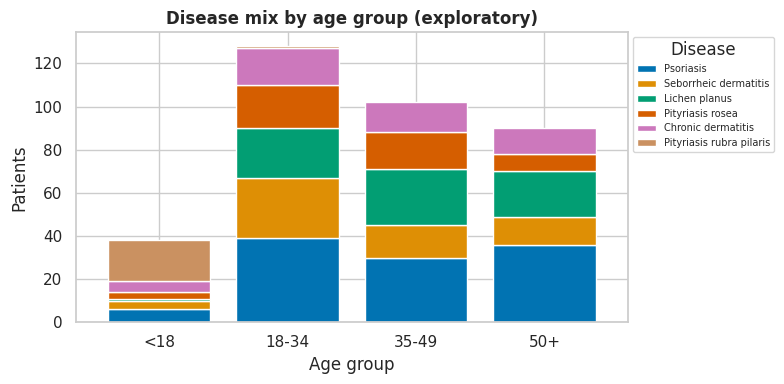

**Interpretation.** Change in cross-validated macro-F1 relative to the original 34 features – **+ totals & groups & age_group**: LogReg -0.0012, RandomForest -0.0039 macro-F1 vs original; **+ pairwise interactions of top-6**: LogReg -0.0012, RandomForest -0.0012 macro-F1 vs original. Differences of this size are small relative to fold-to-fold variation (see the `sd` column), so **the original 34 features are kept** for modelling unless a variant shows a clear, consistent gain.

In [115]:
ag = df.dropna(subset=["Age"]).copy(); ag["age_group"] = pd.cut(ag["Age"], [-1,17,34,49,200], labels=["<18","18-34","35-49","50+"])
ct_age = pd.crosstab(ag["age_group"], ag["class"].map(CLASS_NAMES))[order]
ax = ct_age.plot(kind="bar", stacked=True, color=[pal[o] for o in order], figsize=(8,4), width=.8)
ax.set(title="Disease mix by age group (exploratory)", xlabel="Age group", ylabel="Patients"); ax.legend(title="Disease", fontsize=7, bbox_to_anchor=(1,1)); plt.xticks(rotation=0)
plt.tight_layout(); savefig("15_age_groups"); plt.show()
base = fe[fe.variant=="Original 34"].set_index("model")["macro_f1"]
lines = []
for vn in list(variants)[1:]:
    cur = fe[fe.variant==vn].set_index("model")["macro_f1"]
    lines.append(f"**{vn}**: LogReg {cur['LogReg']-base['LogReg']:+.4f}, RandomForest {cur['RandomForest']-base['RandomForest']:+.4f} macro-F1 vs original")
obs("Change in cross-validated macro-F1 relative to the original 34 features – " + "; ".join(lines) + ". "
    "Differences of this size are small relative to fold-to-fold variation (see the `sd` column), so **the original 34 features are kept** for modelling unless a variant shows a clear, consistent gain.")

## 12. Feature selection and dimensionality analysis
All rankings use the **training split only**. Rankings are for insight; the *performance comparison* uses selectors **inside the CV pipeline**, so selection is re-done on each training fold.

| Technique | Benefit | Limitation |
|---|---|---|
| Mutual information | captures non-linear dependence | noisy on small samples |
| ANOVA F-score | fast, simple | assumes linear, Gaussian-like effects (used only exploratorily on ordinal data) |
| Random-forest importance | handles interactions | biased towards high-cardinality / correlated features |
| Permutation importance | model-agnostic, measured on held-out folds | slow, splits credit among correlated features |
| RFE | considers features jointly | expensive; depends on the base model |
| PCA | removes redundancy | components are hard to interpret clinically |

In [116]:
from sklearn.feature_selection import f_classif, RFE, SelectKBest
from sklearn.inspection import permutation_importance

mi = pd.Series(mutual_info_classif(Xtr_imp, y_train_enc, discrete_features=DISC, random_state=SEED), index=FEATURES)
fF = pd.Series(f_classif(Xtr_imp, y_train_enc)[0], index=FEATURES)
rf_imp = pd.Series(RandomForestClassifier(n_estimators=500, random_state=SEED, n_jobs=2).fit(Xtr_imp, y_train_enc).feature_importances_, index=FEATURES)

# permutation importance measured on held-out CV folds (fit on train folds only)
perm = np.zeros(len(FEATURES))
for tr, va in cv5.split(X_train, y_train_enc):
    m = rf_pipe().fit(X_train.iloc[tr], y_train_enc.iloc[tr])
    pi = permutation_importance(m, X_train.iloc[va], y_train_enc.iloc[va], n_repeats=10, scoring="f1_macro", random_state=SEED, n_jobs=1)
    perm += pi.importances_mean/5
perm = pd.Series(perm, index=FEATURES)

sc = StandardScaler().fit(Xtr_imp)
rfe = RFE(LogisticRegression(max_iter=3000, random_state=SEED), n_features_to_select=15).fit(sc.transform(Xtr_imp), y_train_enc)
rfe_rank = pd.Series(rfe.ranking_, index=FEATURES)

rank_tab = pd.DataFrame({"MI": mi, "ANOVA_F": fF, "RF_importance": rf_imp, "Permutation_dF1": perm, "RFE_rank": rfe_rank})
ranks = pd.DataFrame({"MI": mi.rank(ascending=False), "ANOVA_F": fF.rank(ascending=False), "RF_importance": rf_imp.rank(ascending=False),
                      "Permutation_dF1": perm.rank(ascending=False), "RFE_rank": rfe_rank.rank(method="min")})
rank_tab["mean_rank"] = ranks.mean(axis=1); rank_tab["group"] = ["Clinical" if f in CLINICAL else "Histopathological" if f in HISTO else "Age" for f in rank_tab.index]
rank_tab = rank_tab.sort_values("mean_rank"); rank_tab.to_csv(f"{EVAL_DIR}/feature_rankings.csv")
display(rank_tab.head(15).round(4))

,MI,ANOVA_F,RF_importance,Permutation_dF1,RFE_rank,mean_rank,group
thinning_of_the_suprapapillary_epidermis,0.5319,250.5350,0.0772,0.0032,1,4.6,Histopathological
fibrosis_of_the_papillary_dermis,0.4039,440.3584,0.0802,0.0385,1,5.0,Histopathological
vacuolisation_and_damage_of_basal_layer,0.4905,824.2604,0.0404,0.0000,1,5.2,Histopathological
band-like_infiltrate,0.4806,893.9656,0.0376,-0.0004,1,6.8,Histopathological
focal_hypergranulosis,0.4701,435.3201,0.0386,0.0000,1,7.0,Histopathological
clubbing_of_the_rete_ridges,0.5798,327.3199,0.0970,-0.0021,1,8.0,Histopathological
koebner_phenomenon,0.2965,31.4639,0.0664,0.0715,1,9.2,Clinical
exocytosis,0.4272,88.0277,0.0296,0.0011,1,9.4,Histopathological
spongiosis,0.4692,90.5699,0.0559,-0.0015,1,10.8,Histopathological
elongation_of_the_rete_ridges,0.5861,214.6641,0.0595,-0.0048,1,10.8,Histopathological


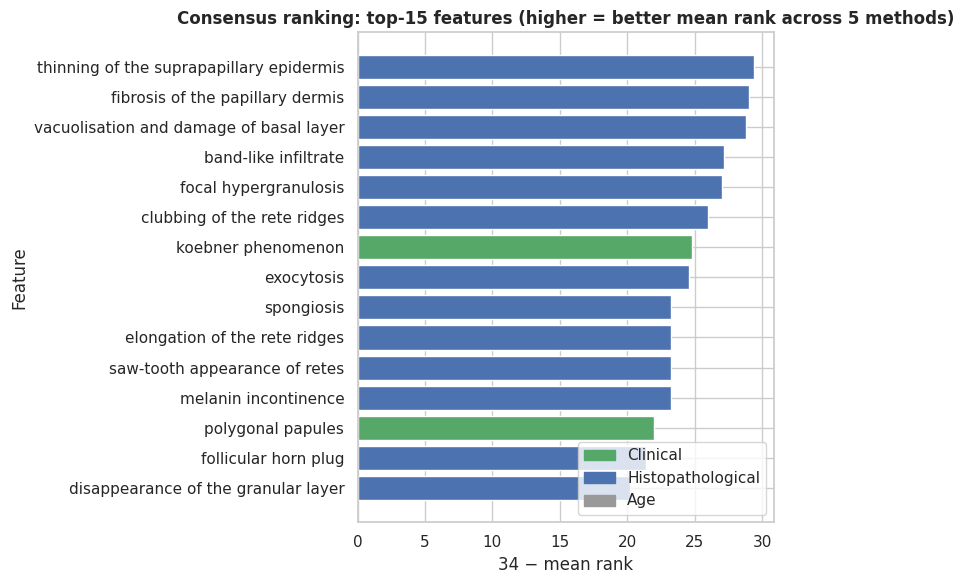

**Interpretation.** Top-15 consensus features contain **13 histopathological**, 2 clinical and 0 Age. Top 5: thinning_of_the_suprapapillary_epidermis, fibrosis_of_the_papillary_dermis, vacuolisation_and_damage_of_basal_layer, band-like_infiltrate, focal_hypergranulosis. Agreement between the four univariate/model rankings is moderate to high (mean pairwise Spearman ρ = 0.58).

In [117]:
top = rank_tab.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh([i.replace("_"," ") for i in top.index], 34-top["mean_rank"], color=["#55A868" if g=="Clinical" else "#4C72B0" if g=="Histopathological" else "#999" for g in top["group"]])
ax.set(title="Consensus ranking: top-15 features (higher = better mean rank across 5 methods)", xlabel="34 − mean rank", ylabel="Feature")
ax.legend(handles=[Patch(color="#55A868", label="Clinical"), Patch(color="#4C72B0", label="Histopathological"), Patch(color="#999", label="Age")], loc="lower right")
plt.tight_layout(); savefig("16_consensus_feature_ranking"); plt.show()
t15 = rank_tab.head(15); tau = ranks[["MI","ANOVA_F","RF_importance","Permutation_dF1"]].corr(method="spearman")
obs(f"Top-15 consensus features contain **{(t15.group=='Histopathological').sum()} histopathological**, {(t15.group=='Clinical').sum()} clinical and {(t15.group=='Age').sum()} Age. Top 5: {', '.join(rank_tab.index[:5])}. "
    f"Agreement between the four univariate/model rankings is moderate to high (mean pairwise Spearman ρ = {tau.values[np.triu_indices(4,1)].mean():.2f}).")

In [118]:
from sklearn.decomposition import PCA as _PCA
def sel_pipe(model, selector=None, scale=False, pca=None):
    steps = [("imp", SimpleImputer(strategy="median"))]
    if scale or pca: steps.append(("sc", StandardScaler()))
    if selector is not None: steps.append(("sel", selector))
    if pca: steps.append(("pca", _PCA(n_components=pca, random_state=SEED)))
    return Pipeline(steps + [("clf", model)])
def mk_lr(): return LogisticRegression(max_iter=3000, random_state=SEED)
def mk_rf(): return RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=2)

def mi_fn(X_, y_):
    mask = [True]*X_.shape[1]
    if X_.shape[1] == len(FEATURES): mask[-1] = False      # Age is the last column of the 34-feature set
    return mutual_info_classif(X_, y_, discrete_features=mask, random_state=SEED)
configs = {
 "All 34 predictors": (FEATURES, lambda s: None),
 "Combined, MI top-20": (FEATURES, lambda s: SelectKBest(mi_fn, k=20)),
 "Combined, MI top-15": (FEATURES, lambda s: SelectKBest(mi_fn, k=15)),
 "Combined, MI top-10": (FEATURES, lambda s: SelectKBest(mi_fn, k=10)),
 "Combined, ANOVA top-15": (FEATURES, lambda s: SelectKBest(f_classif, k=15)),
 "Combined, RFE(LogReg) 15": (FEATURES, lambda s: RFE(LogisticRegression(max_iter=3000, random_state=SEED), n_features_to_select=15)),
 "Clinical only, MI top-6": (CLINICAL, lambda s: SelectKBest(mi_fn, k=6)),
 "Histopathological only, MI top-12": (HISTO, lambda s: SelectKBest(mi_fn, k=12)),
 "Combined, PCA 10 comps": (FEATURES, "pca"),
}
rows = []
for name, (cols, selfn) in configs.items():
    for mname, mk, scale in [("LogReg", mk_lr, True), ("RandomForest", mk_rf, False)]:
        pipe = sel_pipe(mk(), None, scale=True, pca=10) if selfn == "pca" else sel_pipe(mk(), selfn(None), scale=scale or name.startswith("Combined, RFE"))
        r = cross_validate(pipe, X_train[cols], y_train_enc, cv=rcv, scoring=["f1_macro","accuracy"])
        rows.append(dict(setup=name, model=mname, macro_f1=r["test_f1_macro"].mean(), sd=r["test_f1_macro"].std(), accuracy=r["test_accuracy"].mean()))
fs = pd.DataFrame(rows); fs.to_csv(f"{EVAL_DIR}/feature_selection_comparison.csv", index=False)
display(fs.pivot(index="setup", columns="model", values="macro_f1").round(4).loc[list(configs)])

model,LogReg,RandomForest
setup,,
All 34 predictors,0.9703,0.9669
"Combined, MI top-20",0.9560,0.9489
"Combined, MI top-15",0.8488,0.8217
"Combined, MI top-10",0.6675,0.6402
"Combined, ANOVA top-15",0.8003,0.8007
"Combined, RFE(LogReg) 15",0.9795,0.9735
"Clinical only, MI top-6",0.6789,0.6748
"Histopathological only, MI top-12",0.7459,0.6992
"Combined, PCA 10 comps",0.9606,0.9471


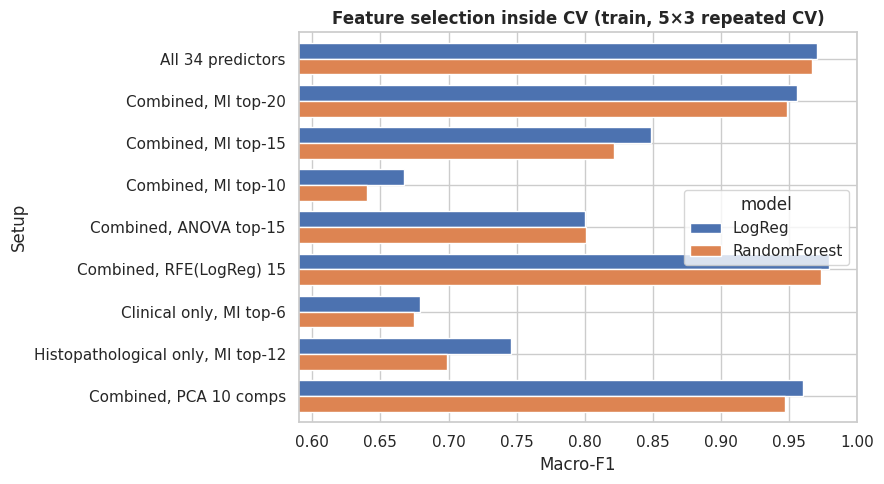

**Interpretation.** All 34 predictors: LogReg 0.970, RandomForest 0.967. Best reduced setup: **Combined, RFE(LogReg) 15** (best model score 0.979, +0.009 vs the best full-feature score; fold-to-fold SD is about 0.026). Clinical-only top-6 reaches 0.679 and histopathological-only top-12 0.746. Gaps of this size are within one fold-SD, so selection mainly buys simplicity rather than a proven accuracy gain; the modelling sections keep all 34 features and treat reduced sets as an option.

In [119]:
pv = fs.pivot(index="setup", columns="model", values="macro_f1").loc[list(configs)]
ax = pv.plot(kind="barh", figsize=(9, 5), width=.75, color=["#4C72B0", "#DD8452"]); ax.invert_yaxis()
ax.set(title="Feature selection inside CV (train, 5×3 repeated CV)", xlabel="Macro-F1", ylabel="Setup", xlim=(max(0, pv.values.min()-.05), 1.0)); plt.tight_layout(); savefig("17_feature_selection_comparison"); plt.show()
full = pv.loc["All 34 predictors"]; bestsel = pv.drop("All 34 predictors").max(axis=1).sort_values(ascending=False)
sd_full = fs[fs.setup=="All 34 predictors"]["sd"].max()
gap = bestsel.iloc[0] - full.max()
obs(f"All 34 predictors: LogReg {full['LogReg']:.3f}, RandomForest {full['RandomForest']:.3f}. Best reduced setup: **{bestsel.index[0]}** (best model score {bestsel.iloc[0]:.3f}, {gap:+.3f} vs the best full-feature score; fold-to-fold SD is about {sd_full:.3f}). "
    f"Clinical-only top-6 reaches {pv.loc['Clinical only, MI top-6'].max():.3f} and histopathological-only top-12 {pv.loc['Histopathological only, MI top-12'].max():.3f}. "
    f"Gaps of this size are {'within' if abs(gap) <= sd_full else 'larger than'} one fold-SD, so selection mainly buys simplicity rather than a proven accuracy gain; the modelling sections keep all 34 features and treat reduced sets as an option.")

## 13. Train–validation–test strategy
* **80 % training / 20 % final test**, stratified, `random_state=42` (the split was created in Section 7, before any modelling).
* **Validation:** 5-fold stratified CV inside the training set (model selection) and **5×3 repeated stratified CV** (stability).
* **Test-set policy (corrected).** The test set was **never used for model selection, hyper-parameter tuning, feature selection, the choice of calibration method or the review threshold** - all of those used training data only (5-fold CV, the independent repeated folds `rcv2`, and out-of-fold training probabilities). It **is**, however, read more than once *after* the model was frozen, always on the same fixed predictions: (i) Section 18 headline metrics, curves, confusion matrix, bootstrap interval, timing and error table; (ii) a check of the review threshold on test patients (the threshold itself was set from out-of-fold training data); (iii) Section 19 SHAP values and **test-set permutation importance** (post-evaluation and **descriptive only**); (iv) the individual-patient example and the `predict_with_support` demo (a test error was chosen on purpose for illustration); (v) the reload check in Section 21; (vi) the descriptive OOF-versus-test calibration comparison in Section 18.1. None of these reads changed the model. Sections 8-9 and 20(a) describe the full 366-patient dataset descriptively and were likewise not used to choose the model.
* **Rule:** any result computed on the test set is **descriptive**. If a test result were used to change a feature set, hyper-parameter, calibrator or threshold, the test set would no longer give an unbiased performance estimate.
* A second repeated CV with a different seed (`rcv2`) re-checks tuned models, to reduce optimism from tuning on one set of folds.

,train,test,total,test_%
1 Psoriasis,89,23,112,20.5
2 Seborrheic dermatitis,49,12,61,19.7
3 Lichen planus,57,15,72,20.8
4 Pityriasis rosea,39,10,49,20.4
5 Chronic dermatitis,42,10,52,19.2
6 Pityriasis rubra pilaris,16,4,20,20.0


Train/test overlap: 0 rows
Train missing Age: 5 | Test missing Age: 3


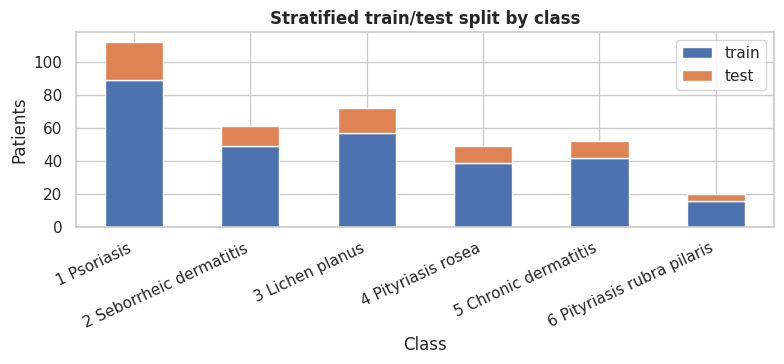

**Interpretation.** Class 6 has only **4 test patients** (of 20), so its test recall can only take values in steps of 25% and is highly uncertain. That is why model selection relies on repeated cross-validation, and why test-set results are reported with bootstrap intervals in Section 18.

In [120]:
split_tab = pd.DataFrame({"train": y_train.value_counts().sort_index(), "test": y_test.value_counts().sort_index(),
                          "total": y.value_counts().sort_index()}); split_tab.index = [f"{i} {CLASS_NAMES[i]}" for i in split_tab.index]
split_tab["test_%"] = (100*split_tab["test"]/split_tab["total"]).round(1); display(split_tab)
print("Train/test overlap:", len(set(X_train.index) & set(X_test.index)), "rows")
print("Train missing Age:", int(X_train.Age.isnull().sum()), "| Test missing Age:", int(X_test.Age.isnull().sum()))
fig, ax = plt.subplots(figsize=(8, 3.8)); split_tab[["train","test"]].plot(kind="bar", stacked=True, ax=ax, color=["#4C72B0","#DD8452"])
ax.set(title="Stratified train/test split by class", xlabel="Class", ylabel="Patients"); plt.xticks(rotation=25, ha="right"); plt.tight_layout(); savefig("18_train_test_split"); plt.show()
obs(f"Class 6 has only **{int(split_tab.iloc[5]['test'])} test patients** (of {int(split_tab.iloc[5]['total'])}), so its test recall can only take values in steps of {100/int(split_tab.iloc[5]['test']):.0f}% and is highly uncertain. "
    f"That is why model selection relies on repeated cross-validation, and why test-set results are reported with bootstrap intervals in Section 18.")

## 14. Baseline model development
Baselines: **Dummy classifier** (the benchmark every real model must beat), **Logistic Regression**, **Decision Tree**, **Gaussian Naive Bayes**.
All use default settings (no class weighting, no resampling) and the same pipelines pattern: median imputer fitted on the training folds → (scaler for scale-sensitive models) → classifier. Every model is scored on the **same** 5×3 repeated stratified folds (`rcv`) on the training split.

In [121]:
import sys
import subprocess

# Automatically install catboost if it's not present
try:
    import catboost
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "catboost"])

from sklearn.dummy import DummyClassifier
from sklearn.base import clone
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              GradientBoostingClassifier, HistGradientBoostingClassifier)
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

def _imp(): return ("imp", SimpleImputer(strategy="median"))
def _sc():  return ("sc", StandardScaler())

def make_models():
    """Fresh, unfitted pipelines (imputation / scaling are fitted inside each CV training fold)."""
    return {
     "Dummy (most frequent)": Pipeline([_imp(), ("clf", DummyClassifier(strategy="most_frequent"))]),
     "Logistic Regression":   Pipeline([_imp(), _sc(), ("clf", LogisticRegression(max_iter=3000, random_state=SEED))]),
     "Decision Tree":         Pipeline([_imp(), ("clf", DecisionTreeClassifier(random_state=SEED))]),
     "Gaussian NB":           Pipeline([_imp(), ("clf", GaussianNB())]),
     "KNN":                   Pipeline([_imp(), _sc(), ("clf", KNeighborsClassifier(n_neighbors=7))]),
     "SVM":                   Pipeline([_imp(), _sc(), ("clf", SVC(kernel="rbf", probability=True, random_state=SEED))]),
     "Random Forest":         Pipeline([_imp(), ("clf", RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=2))]),
     "Extra Trees":           Pipeline([_imp(), ("clf", ExtraTreesClassifier(n_estimators=300, random_state=SEED, n_jobs=2))]),
     "Gradient Boosting":     Pipeline([_imp(), ("clf", GradientBoostingClassifier(random_state=SEED))]),
     "HistGradientBoosting":  Pipeline([_imp(), ("clf", HistGradientBoostingClassifier(random_state=SEED))]),
     "XGBoost":               Pipeline([_imp(), ("clf", XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=4, subsample=0.9,
                                        colsample_bytree=0.9, eval_metric="mlogloss", random_state=SEED, n_jobs=2, verbosity=0))]),
     "CatBoost":              Pipeline([_imp(), ("clf", CatBoostClassifier(iterations=300, depth=6, learning_rate=0.1, loss_function="MultiClass",
                                        random_seed=SEED, verbose=0, thread_count=2, allow_writing_files=False))]),
    }

SCORING = {"accuracy": "accuracy", "precision_macro": "precision_macro", "recall_macro": "recall_macro", "f1_macro": "f1_macro",
           "f1_weighted": "f1_weighted", "balanced_accuracy": "balanced_accuracy", "mcc": make_scorer(matthews_corrcoef)}

def cv_eval(name, pipe, X=X_train, y=y_train_enc, cv=rcv):
    r = cross_validate(pipe, X, y, cv=cv, scoring=SCORING, n_jobs=1)
    out = {"model": name}
    for k in SCORING:
        out[k] = r[f"test_{k}"].mean(); out[f"{k}_sd"] = r[f"test_{k}"].std()
    out["fit_time_s"] = r["fit_time"].mean(); out["predict_time_s"] = r["score_time"].mean()
    out["fold_f1"] = r["test_f1_macro"]
    return out

MODELS = make_models(); RESULTS = {}; OOF = {}
def run(name):
    t0 = time.time(); RESULTS[name] = cv_eval(name, MODELS[name])
    OOF[name] = cross_val_predict(MODELS[name], X_train, y_train_enc, cv=cv5)           # 5-fold out-of-fold predictions
    print(f"{name:24s} macro-F1 = {RESULTS[name]['f1_macro']:.4f} ± {RESULTS[name]['f1_macro_sd']:.4f}   ({time.time()-t0:.0f}s)")

for n in ["Dummy (most frequent)", "Logistic Regression", "Decision Tree", "Gaussian NB"]: run(n)
base = pd.DataFrame({k: {m: v for m, v in r.items() if m not in ("fold_f1", "model")} for k, r in RESULTS.items()}).T.astype(float)
display(base[["accuracy","f1_macro","f1_macro_sd","balanced_accuracy","mcc"]].round(4))
d = RESULTS["Dummy (most frequent)"]
obs(f"The Dummy classifier reaches accuracy {d['accuracy']:.3f} but macro-F1 only **{d['f1_macro']:.3f}** (it always predicts the majority class), which shows why macro-F1 is the primary metric. "
    f"Even the simplest real baselines clearly beat it: Logistic Regression macro-F1 = {RESULTS['Logistic Regression']['f1_macro']:.3f}, Decision Tree = {RESULTS['Decision Tree']['f1_macro']:.3f}, Gaussian NB = {RESULTS['Gaussian NB']['f1_macro']:.3f}.")

Dummy (most frequent)    macro-F1 = 0.0779 ± 0.0012   (0s)
Logistic Regression      macro-F1 = 0.9703 ± 0.0200   (1s)
Decision Tree            macro-F1 = 0.9383 ± 0.0232   (0s)
Gaussian NB              macro-F1 = 0.8804 ± 0.0204   (0s)


,accuracy,f1_macro,f1_macro_sd,balanced_accuracy,mcc
Dummy (most frequent),0.3048,0.0779,0.0012,0.1667,0.0000
Logistic Regression,0.9738,0.9703,0.0200,0.9698,0.9677
Decision Tree,0.9509,0.9383,0.0232,0.9317,0.9398
Gaussian NB,0.8984,0.8804,0.0204,0.8990,0.8846


**Interpretation.** The Dummy classifier reaches accuracy 0.305 but macro-F1 only **0.078** (it always predicts the majority class), which shows why macro-F1 is the primary metric. Even the simplest real baselines clearly beat it: Logistic Regression macro-F1 = 0.970, Decision Tree = 0.938, Gaussian NB = 0.880.

## 15. Advanced model development
Remaining candidates: **KNN, SVM (RBF), Random Forest, Extra Trees, Gradient Boosting, HistGradientBoosting, XGBoost, CatBoost** — 12 models in total with the baselines. Scale-sensitive models (Logistic Regression, KNN, SVM) include `StandardScaler`; tree-based models do not need scaling. These are starting configurations, not claimed optimal.

In [122]:
for n in ["KNN", "SVM", "Random Forest", "Extra Trees", "Gradient Boosting", "HistGradientBoosting", "XGBoost", "CatBoost"]: run(n)

KNN                      macro-F1 = 0.9654 ± 0.0238   (0s)
SVM                      macro-F1 = 0.9731 ± 0.0155   (1s)
Random Forest            macro-F1 = 0.9669 ± 0.0258   (14s)
Extra Trees              macro-F1 = 0.9807 ± 0.0123   (12s)
Gradient Boosting        macro-F1 = 0.9507 ± 0.0288   (17s)
HistGradientBoosting     macro-F1 = 0.9591 ± 0.0382   (8s)
XGBoost                  macro-F1 = 0.9612 ± 0.0458   (4s)
CatBoost                 macro-F1 = 0.9670 ± 0.0285   (10s)


## 16. Cross-validation and model comparison
Metrics (mean ± SD over 15 folds of 5×3 repeated stratified CV): accuracy, macro precision, macro recall, **macro-F1 (primary)**, weighted F1, balanced accuracy, Matthews correlation coefficient. The plain 5-fold (`cv5`) out-of-fold predictions give class-wise recall and confusion matrices.

In [123]:
comp = pd.DataFrame({k: {m: v for m, v in r.items() if m != "fold_f1"} for k, r in RESULTS.items()}).T.drop(columns="model")
comp = comp.astype(float)
comp["oof_5fold_macro_f1"] = [f1_score(y_train_enc, OOF[n], average="macro") for n in comp.index]
comp = comp.sort_values("f1_macro", ascending=False)
show = pd.DataFrame({"Accuracy": comp.accuracy.round(3).astype(str)+" ± "+comp.accuracy_sd.round(3).astype(str),
                     "Macro precision": comp.precision_macro.round(3), "Macro recall": comp.recall_macro.round(3),
                     "Macro F1": comp.f1_macro.round(3).astype(str)+" ± "+comp.f1_macro_sd.round(3).astype(str),
                     "Weighted F1": comp.f1_weighted.round(3), "Balanced acc.": comp.balanced_accuracy.round(3), "MCC": comp.mcc.round(3),
                     "5-fold OOF macro F1": comp.oof_5fold_macro_f1.round(3),
                     "Train time (s)": comp.fit_time_s.round(3), "Predict time, fold (s)": comp.predict_time_s.round(4)})
display(show); comp.to_csv(f"{EVAL_DIR}/model_comparison_default_params.csv")

,Accuracy,Macro precision,Macro recall,Macro F1,Weighted F1,Balanced acc.,MCC,5-fold OOF macro F1,Train time (s),"Predict time, fold (s)"
Extra Trees,0.983 ± 0.011,0.983,0.981,0.981 ± 0.012,0.983,0.981,0.979,0.977,0.495,0.0900
SVM,0.976 ± 0.014,0.975,0.973,0.973 ± 0.015,0.976,0.973,0.970,0.973,0.025,0.0150
Logistic Regression,0.974 ± 0.017,0.974,0.970,0.97 ± 0.02,0.973,0.970,0.968,0.973,0.016,0.0191
CatBoost,0.974 ± 0.021,0.978,0.963,0.967 ± 0.028,0.973,0.963,0.968,0.970,0.474,0.0179
Random Forest,0.974 ± 0.019,0.976,0.963,0.967 ± 0.026,0.973,0.963,0.968,0.968,0.639,0.0896
KNN,0.968 ± 0.021,0.967,0.967,0.965 ± 0.024,0.968,0.967,0.961,0.967,0.005,0.0148
XGBoost,0.968 ± 0.038,0.972,0.957,0.961 ± 0.046,0.967,0.957,0.961,0.974,0.182,0.0187
HistGradientBoosting,0.965 ± 0.034,0.967,0.957,0.959 ± 0.038,0.965,0.957,0.957,0.956,0.399,0.0255
Gradient Boosting,0.959 ± 0.022,0.963,0.946,0.951 ± 0.029,0.958,0.946,0.950,0.960,0.833,0.0169
Decision Tree,0.951 ± 0.019,0.956,0.932,0.938 ± 0.023,0.950,0.932,0.940,0.941,0.007,0.0158


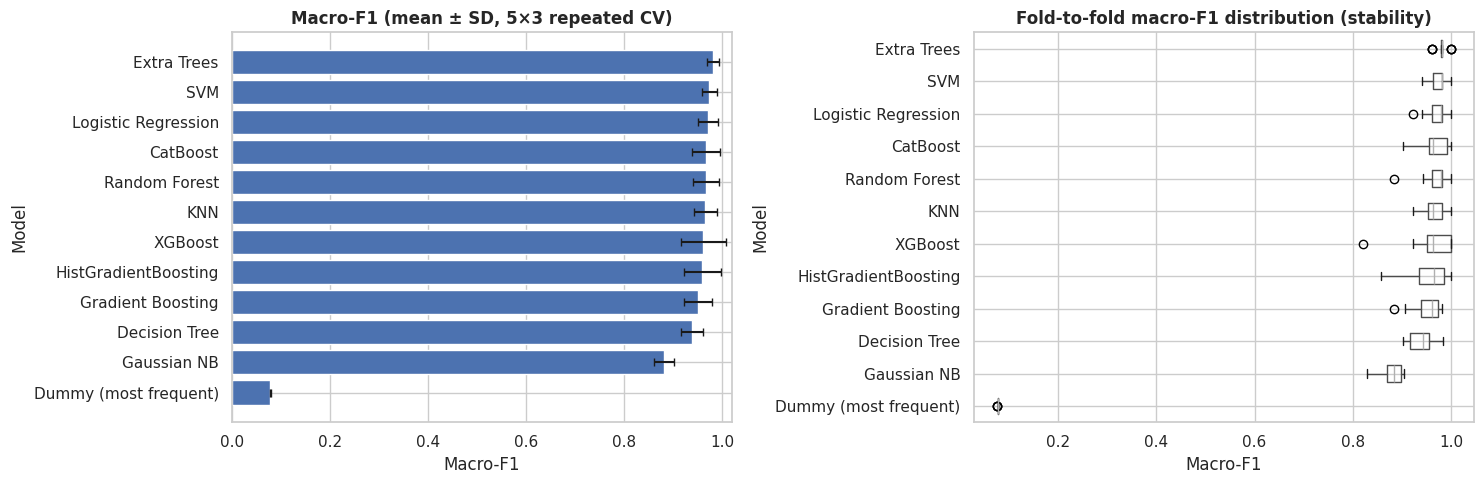

**Interpretation.** Best default-parameter models by macro-F1: **Extra Trees** (0.981), **SVM** (0.973), **Logistic Regression** (0.970). The gap between the best and the 5th-best real model is 0.014, comparable to the fold-to-fold SD (≈ 0.020), so many models are statistically close. More complex models are not automatically better: weakest real model is Gaussian NB (0.880).

In [124]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
c = comp.sort_values("f1_macro")
ax[0].barh(c.index, c.f1_macro, xerr=c.f1_macro_sd, color="#4C72B0", capsize=3); ax[0].set(title="Macro-F1 (mean ± SD, 5×3 repeated CV)", xlabel="Macro-F1", ylabel="Model", xlim=(0, 1.02))
box = pd.DataFrame({n: RESULTS[n]["fold_f1"] for n in comp.index})
box.boxplot(ax=ax[1], vert=False); ax[1].set(title="Fold-to-fold macro-F1 distribution (stability)", xlabel="Macro-F1", ylabel="Model"); ax[1].invert_yaxis()
plt.tight_layout(); savefig("19_model_comparison"); plt.show()
top3 = comp.index[:3].tolist(); real = comp.drop("Dummy (most frequent)")
obs(f"Best default-parameter models by macro-F1: **{top3[0]}** ({comp.loc[top3[0],'f1_macro']:.3f}), **{top3[1]}** ({comp.loc[top3[1],'f1_macro']:.3f}), **{top3[2]}** ({comp.loc[top3[2],'f1_macro']:.3f}). "
    f"The gap between the best and the 5th-best real model is {real.f1_macro.iloc[0]-real.f1_macro.iloc[4]:.3f}, "
    f"comparable to the fold-to-fold SD (≈ {real.f1_macro_sd.iloc[:5].mean():.3f}), so many models are statistically close. More complex models are not automatically better: weakest real model is {real.index[-1]} ({real.f1_macro.iloc[-1]:.3f}).")

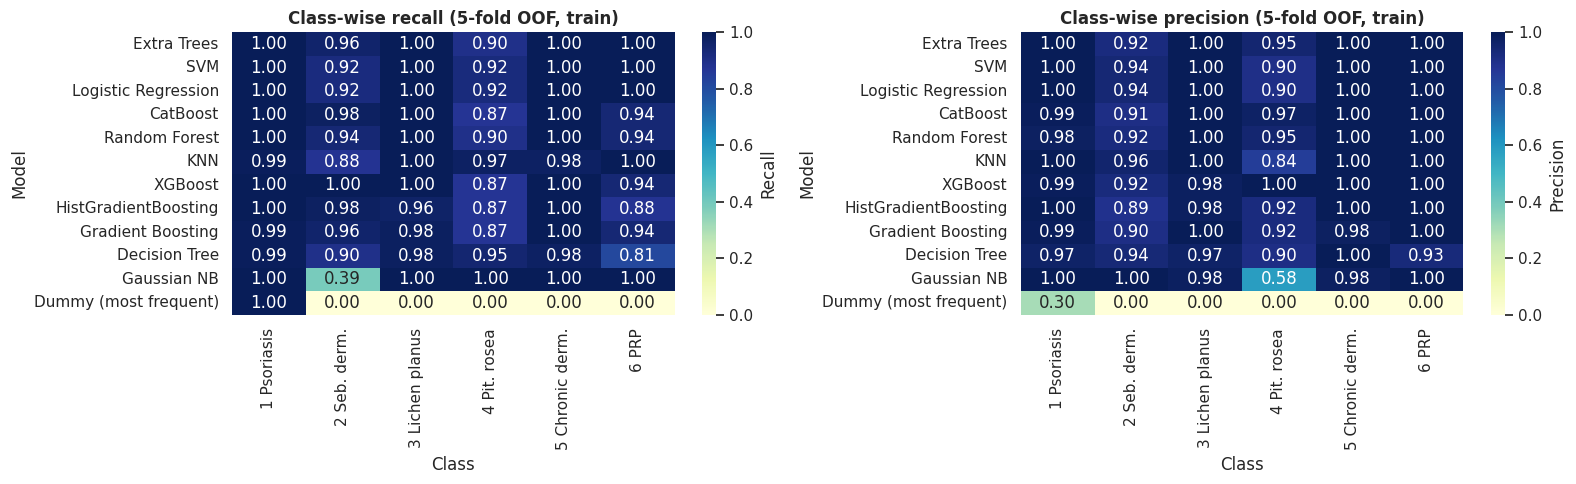

**Interpretation.** Across real models the hardest class is **2 Seb. derm.** (mean recall 0.89); easiest: **1 Psoriasis** (1.00). Class 6 (Pityriasis rubra pilaris, smallest class) recall ranges from 0.81 to 1.00 across models.

In [125]:
labels = [f"{i} {SHORT[i]}" for i in range(1, 7)]
rec_tab = pd.DataFrame({n: recall_score(y_train_enc, OOF[n], average=None) for n in comp.index}, index=labels).T
prec_tab = pd.DataFrame({n: precision_score(y_train_enc, OOF[n], average=None, zero_division=0) for n in comp.index}, index=labels).T
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
sns.heatmap(rec_tab, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1, ax=ax[0], cbar_kws={"label": "Recall"}); ax[0].set(title="Class-wise recall (5-fold OOF, train)", xlabel="Class", ylabel="Model")
sns.heatmap(prec_tab, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1, ax=ax[1], cbar_kws={"label": "Precision"}); ax[1].set(title="Class-wise precision (5-fold OOF, train)", xlabel="Class", ylabel="Model")
plt.tight_layout(); savefig("20_classwise_recall_precision"); plt.show()
rr = rec_tab.drop("Dummy (most frequent)"); weakest = rr.mean().idxmin()
obs(f"Across real models the hardest class is **{weakest}** (mean recall {rr.mean().min():.2f}); easiest: **{rr.mean().idxmax()}** ({rr.mean().max():.2f}). "
    f"Class 6 (Pityriasis rubra pilaris, smallest class) recall ranges from {rr.iloc[:,5].min():.2f} to {rr.iloc[:,5].max():.2f} across models.")

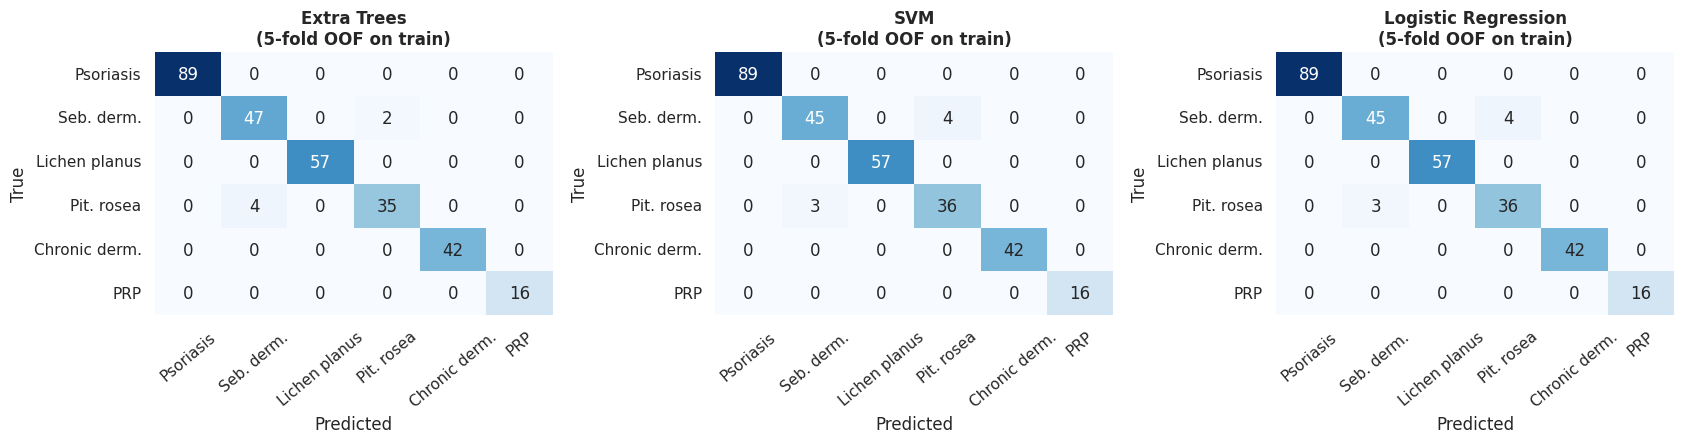

**Interpretation.** For Extra Trees, the most frequent confusion (out-of-fold) is true **Pityriasis rosea → predicted Seborrheic dermatitis** (4 patients); total OOF errors = 6 of 292.

In [126]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for a, n in zip(axes, top3):
    cm = confusion_matrix(y_train_enc, OOF[n]); sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=a, xticklabels=[SHORT[i] for i in range(1,7)], yticklabels=[SHORT[i] for i in range(1,7)])
    a.set(title=f"{n}\n(5-fold OOF on train)", xlabel="Predicted", ylabel="True"); a.tick_params(axis="x", rotation=40)
plt.tight_layout(); savefig("21_confusion_top3_oof"); plt.show()
off = confusion_matrix(y_train_enc, OOF[top3[0]]); np.fill_diagonal(off, 0); i, j = np.unravel_index(off.argmax(), off.shape)
obs(f"For {top3[0]}, the most frequent confusion (out-of-fold) is true **{CLASS_NAMES[i+1]} → predicted {CLASS_NAMES[j+1]}** ({off[i,j]} patients); total OOF errors = {int(off.sum())} of {len(y_train_enc)}.")

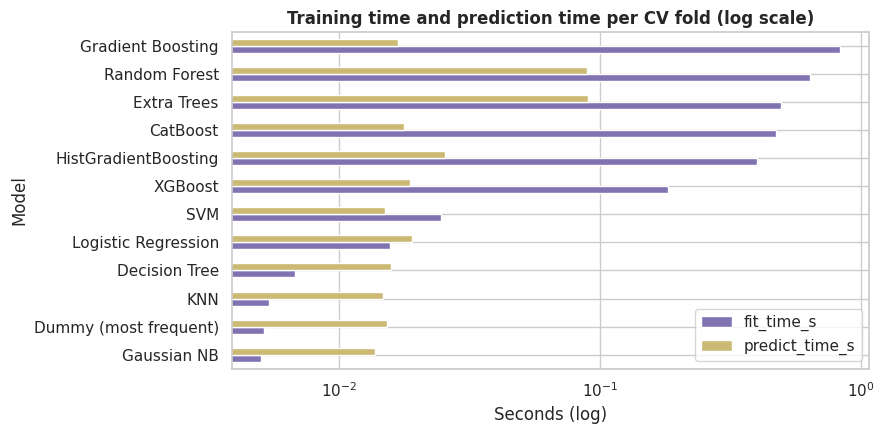

In [127]:
tt = comp[["fit_time_s", "predict_time_s"]].sort_values("fit_time_s")
ax = tt.plot(kind="barh", figsize=(9, 4.5), logx=True, color=["#8172B2", "#CCB974"]); ax.set(title="Training time and prediction time per CV fold (log scale)", xlabel="Seconds (log)", ylabel="Model")
plt.tight_layout(); savefig("22_timing"); plt.show()

### 16.1 Class-imbalance experiments
First the **no-resampling baseline**, then **class weights**, **random oversampling** and **SMOTE**. Resampling is done only *inside* the training folds with `imblearn.pipeline.Pipeline`, so synthetic/duplicated rows never reach validation data. Because the features are ordinal (0–3), SMOTE's interpolated fractional values are checked first.

In [128]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE

# Are SMOTE's synthetic values meaningful for ordinal features?
Xi = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(X_train), columns=FEATURES)
Xs_, ys_ = SMOTE(k_neighbors=3, random_state=SEED).fit_resample(Xi, y_train_enc)
syn = Xs_.iloc[len(Xi):]; graded = [f for f in FEATURES if f not in ("Age",)]
frac = (syn[graded] % 1 != 0).mean().mean()
print(f"SMOTE created {len(syn)} synthetic rows; {100*frac:.1f}% of their graded-feature cells are non-integer (e.g. grade 1.37) - values that do not exist on the 0-3 clinical scale.")

def imb_pipe(kind, clf_name):
    base = MODELS[clf_name]; clf = clone(base.named_steps["clf"]); scale = "sc" in base.named_steps
    steps = [_imp()] + ([_sc()] if scale else [])
    if kind == "class_weight": clf = clf.set_params(class_weight="balanced")
    if kind == "ROS": steps.append(("samp", RandomOverSampler(random_state=SEED)))
    if kind == "SMOTE": steps.append(("samp", SMOTE(k_neighbors=3, random_state=SEED)))
    return ImbPipeline(steps + [("clf", clf)])

rows = []
for mn in ["Logistic Regression", "SVM", "Random Forest"]:
    for kind in ["none", "class_weight", "ROS", "SMOTE"]:
        p = imb_pipe(kind, mn); r = cross_validate(p, X_train, y_train_enc, cv=rcv, scoring=["f1_macro", "balanced_accuracy"])
        oof = cross_val_predict(p, X_train, y_train_enc, cv=cv5); rc = recall_score(y_train_enc, oof, average=None)
        rows.append(dict(model=mn, strategy=kind, macro_f1=r["test_f1_macro"].mean(), sd=r["test_f1_macro"].std(), bal_acc=r["test_balanced_accuracy"].mean(),
                         recall_class6=rc[5], min_class_recall=rc.min()))
imb = pd.DataFrame(rows); imb.to_csv(f"{EVAL_DIR}/imbalance_experiments.csv", index=False); display(imb.round(4))

SMOTE created 242 synthetic rows; 24.1% of their graded-feature cells are non-integer (e.g. grade 1.37) - values that do not exist on the 0-3 clinical scale.


,model,strategy,macro_f1,sd,bal_acc,recall_class6,min_class_recall
0,Logistic Regression,none,0.9703,0.0200,0.9698,1.0000,0.9184
1,Logistic Regression,class_weight,0.9717,0.0223,0.9719,1.0000,0.9184
2,Logistic Regression,ROS,0.9678,0.0243,0.9679,1.0000,0.9184
3,Logistic Regression,SMOTE,0.9664,0.0195,0.9663,1.0000,0.9184
4,SVM,none,0.9731,0.0155,0.9735,1.0000,0.9184
5,SVM,class_weight,0.9770,0.0161,0.9776,1.0000,0.9184
6,SVM,ROS,0.9756,0.0179,0.9763,1.0000,0.9184
7,SVM,SMOTE,0.9704,0.0139,0.9705,1.0000,0.9184
8,Random Forest,none,0.9669,0.0258,0.9631,0.9375,0.8974
9,Random Forest,class_weight,0.9705,0.0229,0.9667,0.9375,0.8974


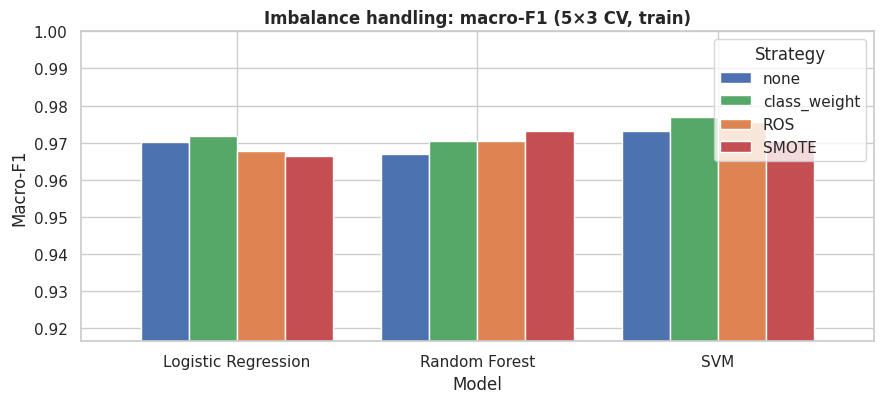

**Interpretation.** Change in macro-F1 vs no resampling (mean fold SD ≈ 0.019): **Logistic Regression**: class weights +0.001, random oversampling -0.003, SMOTE -0.004; **Random Forest**: class weights +0.004, random oversampling +0.004, SMOTE +0.006; **SVM**: class weights +0.004, random oversampling +0.003, SMOTE -0.003. Most changes are within fold-to-fold noise, so resampling is **not assumed to help**. Class weighting is cheap and leak-free, so it is offered as a hyper-parameter in the tuning search (Section 17); SMOTE is not used further because 24% of its synthetic graded values are fractional.

In [129]:
piv = imb.pivot(index="model", columns="strategy", values="macro_f1")[["none","class_weight","ROS","SMOTE"]]
ax = piv.plot(kind="bar", figsize=(9, 4.2), width=.8, color=["#4C72B0","#55A868","#DD8452","#C44E52"]); ax.set(title="Imbalance handling: macro-F1 (5×3 CV, train)", xlabel="Model", ylabel="Macro-F1", ylim=(max(0, piv.values.min()-.05), 1.0))
plt.xticks(rotation=0); plt.legend(title="Strategy"); plt.tight_layout(); savefig("23_imbalance_strategies"); plt.show()
dl = (piv.sub(piv["none"], axis=0)).drop(columns="none"); sd_ = imb.sd.mean()
obs(f"Change in macro-F1 vs no resampling (mean fold SD ≈ {sd_:.3f}): " + "; ".join(f"**{m}**: class weights {dl.loc[m,'class_weight']:+.3f}, random oversampling {dl.loc[m,'ROS']:+.3f}, SMOTE {dl.loc[m,'SMOTE']:+.3f}" for m in dl.index) + ". "
    f"Most changes are within fold-to-fold noise, so resampling is **not assumed to help**. Class weighting is cheap and leak-free, so it is offered as a hyper-parameter in the tuning search (Section 17); SMOTE is not used further because {100*frac:.0f}% of its synthetic graded values are fractional.")

## 17. Hyperparameter optimisation
* **Method A – RandomizedSearchCV** on the strongest tunable models (top-4 by Section 16 macro-F1).
* **Method B – Optuna (TPE)** on the top-3, with an objective that evaluates **only training folds** (5-fold stratified CV, macro-F1).
* The final test set is never used for tuning or selection. Because tuning picks the best of many configurations on the `cv5` folds, scores are then **re-estimated on independent repeated folds (`rcv2`, different seed)** to limit optimism. Tuned models are only credited if the re-estimate shows an improvement.

In [130]:
import sys
import subprocess

# Automatically install optuna if it's not present
try:
    import optuna
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "optuna"])

from scipy.stats import randint, uniform, loguniform
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

SPACES = {
 "Logistic Regression": {"clf__C": loguniform(1e-2, 1e2), "clf__class_weight": [None, "balanced"]},
 "KNN": {"clf__n_neighbors": randint(3, 16), "clf__weights": ["uniform", "distance"], "clf__p": [1, 2]},
 "SVM": {"clf__C": loguniform(1e-1, 1e2), "clf__kernel": ["rbf", "linear", "poly"], "clf__gamma": ["scale", 0.003, 0.01, 0.03, 0.1], "clf__class_weight": [None, "balanced"]},
 "Random Forest": {"clf__n_estimators": randint(100, 601), "clf__max_depth": [None, 4, 6, 8, 12], "clf__min_samples_leaf": randint(1, 5),
                   "clf__max_features": ["sqrt", "log2", 0.5], "clf__class_weight": [None, "balanced"]},
 "Extra Trees": {"clf__n_estimators": randint(100, 601), "clf__max_features": ["sqrt", "log2", 0.5], "clf__min_samples_split": randint(2, 9), "clf__class_weight": [None, "balanced"]},
 "Gradient Boosting": {"clf__n_estimators": randint(50, 301), "clf__learning_rate": loguniform(0.02, 0.3), "clf__max_depth": randint(2, 5), "clf__subsample": uniform(0.6, 0.4)},
 "HistGradientBoosting": {"clf__learning_rate": loguniform(0.02, 0.3), "clf__max_depth": [None, 3, 5, 8], "clf__max_leaf_nodes": randint(8, 41), "clf__l2_regularization": loguniform(1e-3, 10), "clf__max_iter": randint(100, 301)},
 "XGBoost": {"clf__learning_rate": loguniform(0.02, 0.3), "clf__max_depth": randint(2, 7), "clf__n_estimators": randint(100, 501), "clf__subsample": uniform(0.6, 0.4), "clf__colsample_bytree": uniform(0.5, 0.5), "clf__reg_lambda": loguniform(0.1, 10)},
 "CatBoost": {"clf__iterations": randint(100, 301), "clf__depth": randint(3, 9), "clf__learning_rate": loguniform(0.03, 0.3), "clf__l2_leaf_reg": loguniform(1, 10)},
}
N_ITER = {"CatBoost": 8, "Gradient Boosting": 12, "XGBoost": 15, "HistGradientBoosting": 15}
N_TRIALS = {"CatBoost": 10, "Gradient Boosting": 12, "XGBoost": 15, "HistGradientBoosting": 15}

def suggest(trial, name):
    s = trial.suggest_float; i = trial.suggest_int; c = trial.suggest_categorical
    if name == "Logistic Regression": return {"clf__C": s("C", 1e-2, 1e2, log=True), "clf__class_weight": c("class_weight", [None, "balanced"])}
    if name == "KNN": return {"clf__n_neighbors": i("n_neighbors", 3, 15), "clf__weights": c("weights", ["uniform", "distance"]), "clf__p": c("p", [1, 2])}
    if name == "SVM": return {"clf__C": s("C", 1e-1, 1e2, log=True), "clf__kernel": c("kernel", ["rbf", "linear", "poly"]), "clf__gamma": c("gamma", ["scale", 0.003, 0.01, 0.03, 0.1]), "clf__class_weight": c("class_weight", [None, "balanced"])}
    if name == "Random Forest": return {"clf__n_estimators": i("n_estimators", 100, 600), "clf__max_depth": c("max_depth", [None, 4, 6, 8, 12]), "clf__min_samples_leaf": i("min_samples_leaf", 1, 4), "clf__max_features": c("max_features", ["sqrt", "log2", 0.5]), "clf__class_weight": c("class_weight", [None, "balanced"])}
    if name == "Extra Trees": return {"clf__n_estimators": i("n_estimators", 100, 600), "clf__max_features": c("max_features", ["sqrt", "log2", 0.5]), "clf__min_samples_split": i("min_samples_split", 2, 8), "clf__class_weight": c("class_weight", [None, "balanced"])}
    if name == "Gradient Boosting": return {"clf__n_estimators": i("n_estimators", 50, 300), "clf__learning_rate": s("learning_rate", 0.02, 0.3, log=True), "clf__max_depth": i("max_depth", 2, 4), "clf__subsample": s("subsample", 0.6, 1.0)}
    if name == "HistGradientBoosting": return {"clf__learning_rate": s("learning_rate", 0.02, 0.3, log=True), "clf__max_depth": c("max_depth", [None, 3, 5, 8]), "clf__max_leaf_nodes": i("max_leaf_nodes", 8, 40), "clf__l2_regularization": s("l2", 1e-3, 10, log=True), "clf__max_iter": i("max_iter", 100, 300)}
    if name == "XGBoost": return {"clf__learning_rate": s("learning_rate", 0.02, 0.3, log=True), "clf__max_depth": i("max_depth", 2, 6), "clf__n_estimators": i("n_estimators", 100, 500), "clf__subsample": s("subsample", 0.6, 1.0), "clf__colsample_bytree": s("colsample_bytree", 0.5, 1.0), "clf__reg_lambda": s("reg_lambda", 0.1, 10, log=True)}
    if name == "CatBoost": return {"clf__iterations": i("iterations", 100, 300), "clf__depth": i("depth", 3, 8), "clf__learning_rate": s("learning_rate", 0.03, 0.3, log=True), "clf__l2_leaf_reg": s("l2_leaf_reg", 1, 10, log=True)}

tunable = [m for m in comp.index if m in SPACES]
RS_FAMILIES, OPT_FAMILIES = tunable[:4], tunable[:3]
print("RandomizedSearchCV on:", RS_FAMILIES, "\nOptuna on:", OPT_FAMILIES)

RandomizedSearchCV on: ['Extra Trees', 'SVM', 'Logistic Regression', 'CatBoost'] 
Optuna on: ['Extra Trees', 'SVM', 'Logistic Regression']


In [131]:
RS_RES, rs_rows = {}, []
for fam in RS_FAMILIES:
    t0 = time.time()
    rs = RandomizedSearchCV(make_models()[fam], SPACES[fam], n_iter=N_ITER.get(fam, 25), scoring="f1_macro", cv=cv5, random_state=SEED, n_jobs=1, refit=True)
    rs.fit(X_train, y_train_enc); RS_RES[fam] = rs
    rs_rows.append(dict(model=fam, best_cv5_macro_f1=rs.best_score_, n_iter=rs.n_iter, seconds=time.time()-t0, best_params={k.replace("clf__",""): v for k, v in rs.best_params_.items()}))
    print(f"{fam:22s} best cv5 macro-F1 = {rs.best_score_:.4f}  ({time.time()-t0:.0f}s)")
rs_tab = pd.DataFrame(rs_rows); display(rs_tab.round(4))

Extra Trees            best cv5 macro-F1 = 0.9846  (93s)
SVM                    best cv5 macro-F1 = 0.9771  (3s)
Logistic Regression    best cv5 macro-F1 = 0.9771  (3s)
CatBoost               best cv5 macro-F1 = 0.9691  (12s)


,model,best_cv5_macro_f1,n_iter,seconds,best_params
0,Extra Trees,0.9846,25,93.1859,"{'class_weight': None, 'max_features': 'sqrt',..."
1,SVM,0.9771,25,3.2803,"{'C': 1.4899847475658243, 'class_weight': 'bal..."
2,Logistic Regression,0.9771,25,2.9691,"{'C': 6.79657809075816, 'class_weight': 'balan..."
3,CatBoost,0.9691,8,11.8122,"{'depth': 7, 'iterations': 202, 'l2_leaf_reg':..."


Extra Trees            best cv5 macro-F1 = 0.9845  (30 trials, 98s)
SVM                    best cv5 macro-F1 = 0.9771  (30 trials, 4s)
Logistic Regression    best cv5 macro-F1 = 0.9771  (30 trials, 4s)


,model,best_cv5_macro_f1,n_trials,seconds,best_params
0,Extra Trees,0.9845,30,98.2889,"{'n_estimators': 191, 'max_features': 0.5, 'mi..."
1,SVM,0.9771,30,3.6556,"{'C': 1.3268129545459753, 'kernel': 'linear', ..."
2,Logistic Regression,0.9771,30,3.7103,"{'C': 6.79657809075816, 'class_weight': 'balan..."


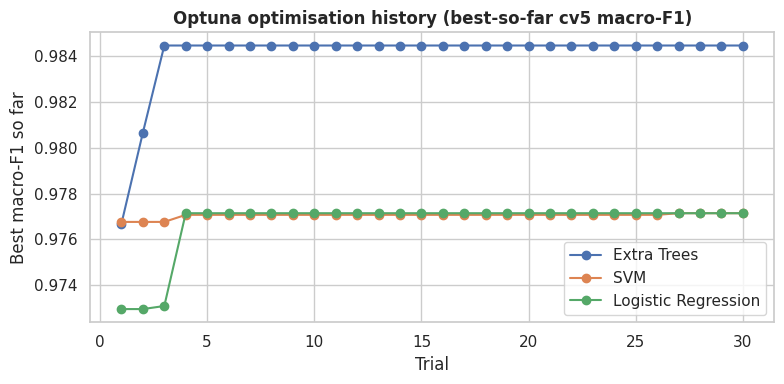

In [132]:
OPT_RES, opt_rows = {}, []
for fam in OPT_FAMILIES:
    t0 = time.time()
    def objective(trial, fam=fam):
        pipe = make_models()[fam].set_params(**suggest(trial, fam))
        return cross_val_score(pipe, X_train, y_train_enc, cv=cv5, scoring="f1_macro", n_jobs=1).mean()      # training folds only
    st = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
    st.optimize(objective, n_trials=N_TRIALS.get(fam, 30)); OPT_RES[fam] = st
    opt_rows.append(dict(model=fam, best_cv5_macro_f1=st.best_value, n_trials=len(st.trials), seconds=time.time()-t0, best_params=st.best_params))
    print(f"{fam:22s} best cv5 macro-F1 = {st.best_value:.4f}  ({len(st.trials)} trials, {time.time()-t0:.0f}s)")
opt_tab = pd.DataFrame(opt_rows); display(opt_tab.round(4))
fig, ax = plt.subplots(figsize=(8, 4))
for fam, st in OPT_RES.items():
    v = [t.value for t in st.trials]; ax.plot(range(1, len(v)+1), np.maximum.accumulate(v), "o-", label=fam)
ax.set(title="Optuna optimisation history (best-so-far cv5 macro-F1)", xlabel="Trial", ylabel="Best macro-F1 so far"); ax.legend(); plt.tight_layout(); savefig("24_optuna_history"); plt.show()

In [133]:
# Re-estimate default vs RandomizedSearch vs Optuna on INDEPENDENT repeated folds (rcv2), same folds for all
CAND = {}
for fam in sorted(set(RS_FAMILIES) | set(OPT_FAMILIES), key=tunable.index):
    CAND[f"{fam} | default"] = make_models()[fam]
    if fam in RS_RES:  CAND[f"{fam} | RandomizedSearch"] = make_models()[fam].set_params(**RS_RES[fam].best_params_)
    if fam in OPT_RES: CAND[f"{fam} | Optuna"] = make_models()[fam].set_params(**{k: v for k, v in suggest(optuna.trial.FixedTrial(OPT_RES[fam].best_params), fam).items()})
CAND_RES = {}
for n, p in CAND.items():
    t0 = time.time(); CAND_RES[n] = cv_eval(n, p, cv=rcv2); print(f"{n:38s} macro-F1 = {CAND_RES[n]['f1_macro']:.4f} ± {CAND_RES[n]['f1_macro_sd']:.4f}  ({time.time()-t0:.0f}s)")
cand_tab = pd.DataFrame({k: {m: v for m, v in r.items() if m not in ("fold_f1", "model")} for k, r in CAND_RES.items()}).T.astype(float).sort_values("f1_macro", ascending=False)
cand_tab.to_csv(f"{EVAL_DIR}/model_comparison_tuned_rcv2.csv"); display(cand_tab[["accuracy","f1_macro","f1_macro_sd","balanced_accuracy","mcc","fit_time_s"]].round(4))

Extra Trees | default                  macro-F1 = 0.9833 ± 0.0170  (9s)
Extra Trees | RandomizedSearch         macro-F1 = 0.9844 ± 0.0177  (6s)
Extra Trees | Optuna                   macro-F1 = 0.9819 ± 0.0166  (7s)
SVM | default                          macro-F1 = 0.9783 ± 0.0119  (1s)
SVM | RandomizedSearch                 macro-F1 = 0.9779 ± 0.0162  (0s)
SVM | Optuna                           macro-F1 = 0.9779 ± 0.0177  (0s)
Logistic Regression | default          macro-F1 = 0.9767 ± 0.0177  (1s)
Logistic Regression | RandomizedSearch macro-F1 = 0.9792 ± 0.0169  (1s)
Logistic Regression | Optuna           macro-F1 = 0.9792 ± 0.0169  (1s)
CatBoost | default                     macro-F1 = 0.9701 ± 0.0163  (8s)
CatBoost | RandomizedSearch            macro-F1 = 0.9700 ± 0.0159  (7s)


,accuracy,f1_macro,f1_macro_sd,balanced_accuracy,mcc,fit_time_s
Extra Trees | RandomizedSearch,0.9863,0.9844,0.0177,0.9841,0.9831,0.3173
Extra Trees | default,0.9852,0.9833,0.0170,0.9833,0.9817,0.4930
Extra Trees | Optuna,0.9840,0.9819,0.0166,0.9815,0.9803,0.3705
Logistic Regression | Optuna,0.9818,0.9792,0.0169,0.9798,0.9778,0.0174
Logistic Regression | RandomizedSearch,0.9818,0.9792,0.0169,0.9798,0.9778,0.0231
SVM | default,0.9806,0.9783,0.0119,0.9790,0.9763,0.0261
SVM | RandomizedSearch,0.9806,0.9779,0.0162,0.9791,0.9763,0.0139
SVM | Optuna,0.9806,0.9779,0.0177,0.9794,0.9764,0.0147
Logistic Regression | default,0.9795,0.9767,0.0177,0.9771,0.9748,0.0152
CatBoost | default,0.9761,0.9701,0.0163,0.9656,0.9705,0.4887


,default,randomized,optuna
model,,,
Extra Trees,0.9833,0.9844,0.9819
SVM,0.9783,0.9779,0.9779
Logistic Regression,0.9767,0.9792,0.9792
CatBoost,0.9701,0.9700,NaN


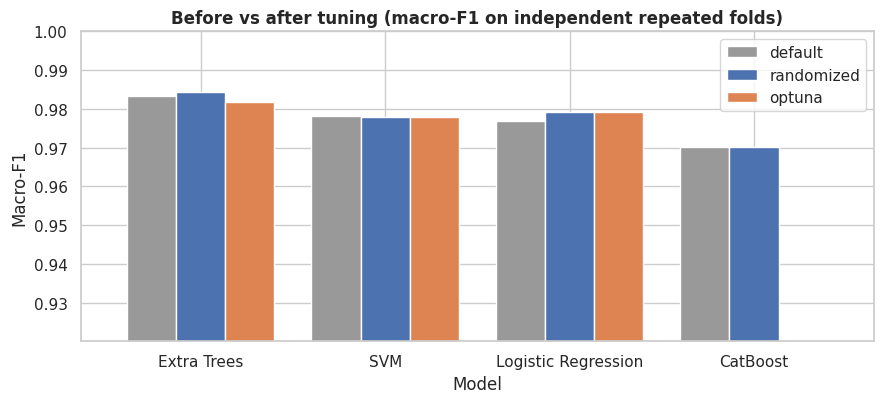

**Interpretation.** Change vs default parameters: **Extra Trees** RandomizedSearch +0.0011, Optuna -0.0014; **SVM** RandomizedSearch -0.0004, Optuna -0.0004; **Logistic Regression** RandomizedSearch +0.0024, Optuna +0.0024; **CatBoost** RandomizedSearch -0.0001, Optuna not run (fold SD ≈ 0.016). Tuning improved the macro-F1 of 0 of 4 models by more than one fold-SD; other changes are within noise and **should not be claimed as improvements**.

In [134]:
rows = []
for fam in sorted(set(RS_FAMILIES) | set(OPT_FAMILIES), key=tunable.index):
    d0 = CAND_RES[f"{fam} | default"]["f1_macro"]
    rows.append(dict(model=fam, default=d0, randomized=CAND_RES.get(f"{fam} | RandomizedSearch", {}).get("f1_macro", np.nan), optuna=CAND_RES.get(f"{fam} | Optuna", {}).get("f1_macro", np.nan)))
ba = pd.DataFrame(rows).set_index("model"); display(ba.round(4))
ax = ba.plot(kind="bar", figsize=(9, 4.2), width=.8, color=["#999999", "#4C72B0", "#DD8452"]); ax.set(title="Before vs after tuning (macro-F1 on independent repeated folds)", xlabel="Model", ylabel="Macro-F1", ylim=(max(0, np.nanmin(ba.values)-.05), 1.0))
plt.xticks(rotation=0); plt.tight_layout(); savefig("25_before_after_tuning"); plt.show()
gain = (ba[["randomized", "optuna"]].sub(ba["default"], axis=0)); sd_c = cand_tab.f1_macro_sd.mean()
fmt = lambda v: "not run" if pd.isna(v) else f"{v:+.4f}"
obs("Change vs default parameters: " + "; ".join(f"**{m}** RandomizedSearch {fmt(gain.loc[m,'randomized'])}, Optuna {fmt(gain.loc[m,'optuna'])}" for m in gain.index) + f" (fold SD ≈ {sd_c:.3f}). "
    f"Tuning improved the macro-F1 of {int((gain.max(axis=1) > sd_c).sum())} of {len(gain)} models by more than one fold-SD; other changes are within noise and **should not be claimed as improvements**.")
with open(f"{EVAL_DIR}/best_hyperparameters.json", "w") as f:
    json.dump({"randomized_search": {k: {"cv5_macro_f1": float(v.best_score_), "params": {a.replace('clf__',''): (b if not isinstance(b, (np.integer, np.floating)) else b.item()) for a, b in v.best_params_.items()}} for k, v in RS_RES.items()},
               "optuna": {k: {"cv5_macro_f1": float(v.best_value), "params": v.best_params} for k, v in OPT_RES.items()}}, f, indent=2, default=str)

In [135]:
# ---- Final model selection rule (stated before looking at the test set):
# highest mean macro-F1 on the independent repeated folds; if several candidates are within 0.003, prefer the fastest/simplest one.
best_f1 = cand_tab.f1_macro.max(); short = cand_tab[cand_tab.f1_macro >= best_f1 - 0.003].sort_values("fit_time_s")
FINAL_NAME = short.index[0]; final_base = CAND[FINAL_NAME]
if "clf__n_jobs" in final_base.get_params(): final_base.set_params(clf__n_jobs=1)      # single-threaded: realistic latency for one patient
print("Shortlist within 0.003 of best:\n", short[["f1_macro", "f1_macro_sd", "fit_time_s"]].round(4))
print("\nSelected model:", FINAL_NAME)
print("Parameters:", {k: v for k, v in final_base.get_params().items() if k.startswith("clf__") and not callable(v)})

Shortlist within 0.003 of best:
                                 f1_macro  f1_macro_sd  fit_time_s
Extra Trees | RandomizedSearch    0.9844       0.0177      0.3173
Extra Trees | Optuna              0.9819       0.0166      0.3705
Extra Trees | default             0.9833       0.0170      0.4930

Selected model: Extra Trees | RandomizedSearch
Parameters: {'clf__bootstrap': False, 'clf__ccp_alpha': 0.0, 'clf__class_weight': None, 'clf__criterion': 'gini', 'clf__max_depth': None, 'clf__max_features': 'sqrt', 'clf__max_leaf_nodes': None, 'clf__max_samples': None, 'clf__min_impurity_decrease': 0.0, 'clf__min_samples_leaf': 1, 'clf__min_samples_split': 8, 'clf__min_weight_fraction_leaf': 0.0, 'clf__monotonic_cst': None, 'clf__n_estimators': 206, 'clf__n_jobs': 1, 'clf__oob_score': False, 'clf__random_state': 42, 'clf__verbose': 0, 'clf__warm_start': False}


## 18. Final model evaluation
The selected configuration is fitted on the **training set** and evaluated on the held-out test set (74 patients) for the headline metrics. The test set was not used for any selection or tuning decision; the same fixed predictions are then read for descriptive analyses (see Section 13). Test results with 4 class-6 patients are noisy, so they are reported with bootstrap intervals and read together with cross-validation stability.

**Probability calibration.** Calibration (`CalibratedClassifierCV`, sigmoid or isotonic) is compared with the uncalibrated model using **out-of-fold training predictions** (not the test set); the calibrated version is used only if it lowers cross-validated log-loss.

*Additional calibration diagnostics (Section 18.1) and a privacy-preserving misclassification analysis (Section 18.2) follow the original reliability analysis below. Calibrated probabilities are model scores, not clinical risks.*


In [136]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.base import clone

def brier_multi(y_true, proba): return float(np.mean(np.sum((proba - np.eye(proba.shape[1])[y_true])**2, axis=1)))
def ece_top(y_true, proba, bins=8):
    conf, pred = proba.max(1), proba.argmax(1); acc = (pred == y_true).astype(float); e = 0
    edges = np.linspace(0.0, 1.0, bins+1)
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): e += m.mean()*abs(acc[m].mean() - conf[m].mean())
    return float(e)

cal_rows, OOFP = [], {}
variants = {"uncalibrated": clone(final_base),
            "sigmoid": CalibratedClassifierCV(clone(final_base), method="sigmoid", cv=5),
            "isotonic": CalibratedClassifierCV(clone(final_base), method="isotonic", cv=5)}
for k, m in variants.items():
    P = cross_val_predict(m, X_train, y_train_enc, cv=cv5, method="predict_proba"); OOFP[k] = P
    cal_rows.append(dict(variant=k, log_loss=log_loss(y_train_enc, P), brier=brier_multi(y_train_enc.values, P), ECE=ece_top(y_train_enc.values, P),
                         macro_f1=f1_score(y_train_enc, P.argmax(1), average="macro")))
cal_tab = pd.DataFrame(cal_rows).set_index("variant"); display(cal_tab.round(4))
CAL_CHOICE = cal_tab.log_loss.idxmin(); print("Chosen variant (lowest OOF log-loss on training data):", CAL_CHOICE)

,log_loss,brier,ECE,macro_f1
variant,,,,
uncalibrated,0.1487,0.0549,0.1069,0.9846
sigmoid,0.1799,0.0480,0.1363,0.9743
isotonic,0.0375,0.0218,0.0116,0.9846


Chosen variant (lowest OOF log-loss on training data): isotonic


In [137]:
final_model = clone(variants[CAL_CHOICE]).fit(X_train, y_train_enc)     # model that makes predictions
base_model = clone(final_base).fit(X_train, y_train_enc)                # uncalibrated pipeline (used for SHAP / permutation importance)

proba = final_model.predict_proba(X_test); pred = proba.argmax(1)
yt = y_test_enc.values
print(classification_report(yt, pred, target_names=[f"{i} {CLASS_NAMES[i]}" for i in range(1, 7)], digits=3))
macro = dict(precision=precision_score(yt, pred, average="macro"), recall=recall_score(yt, pred, average="macro"), f1=f1_score(yt, pred, average="macro"))
wtd = dict(precision=precision_score(yt, pred, average="weighted"), recall=recall_score(yt, pred, average="weighted"), f1=f1_score(yt, pred, average="weighted"))
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve
TEST = dict(accuracy=accuracy_score(yt, pred), balanced_accuracy=balanced_accuracy_score(yt, pred), mcc=matthews_corrcoef(yt, pred),
            macro_precision=macro["precision"], macro_recall=macro["recall"], macro_f1=macro["f1"], weighted_f1=wtd["f1"],
            roc_auc_ovr_macro=roc_auc_score(yt, proba, multi_class="ovr", average="macro"), log_loss=log_loss(yt, proba, labels=range(6)), brier=brier_multi(yt, proba))
display(pd.Series(TEST).round(4).to_frame("test set"))
print("Macro averages:", {k: round(v, 3) for k, v in macro.items()}, "\nWeighted averages:", {k: round(v, 3) for k, v in wtd.items()})

                            precision    recall  f1-score   support

               1 Psoriasis      1.000     1.000     1.000        23
   2 Seborrheic dermatitis      1.000     0.833     0.909        12
           3 Lichen planus      1.000     1.000     1.000        15
        4 Pityriasis rosea      0.833     1.000     0.909        10
      5 Chronic dermatitis      1.000     1.000     1.000        10
6 Pityriasis rubra pilaris      1.000     1.000     1.000         4

                  accuracy                          0.973        74
                 macro avg      0.972     0.972     0.970        74
              weighted avg      0.977     0.973     0.973        74



,test set
accuracy,0.9730
balanced_accuracy,0.9722
mcc,0.9670
macro_precision,0.9722
macro_recall,0.9722
macro_f1,0.9697
weighted_f1,0.9730
roc_auc_ovr_macro,0.9993
log_loss,0.0712
brier,0.0436


Macro averages: {'precision': 0.972, 'recall': 0.972, 'f1': 0.97} 
Weighted averages: {'precision': 0.977, 'recall': 0.973, 'f1': 0.973}


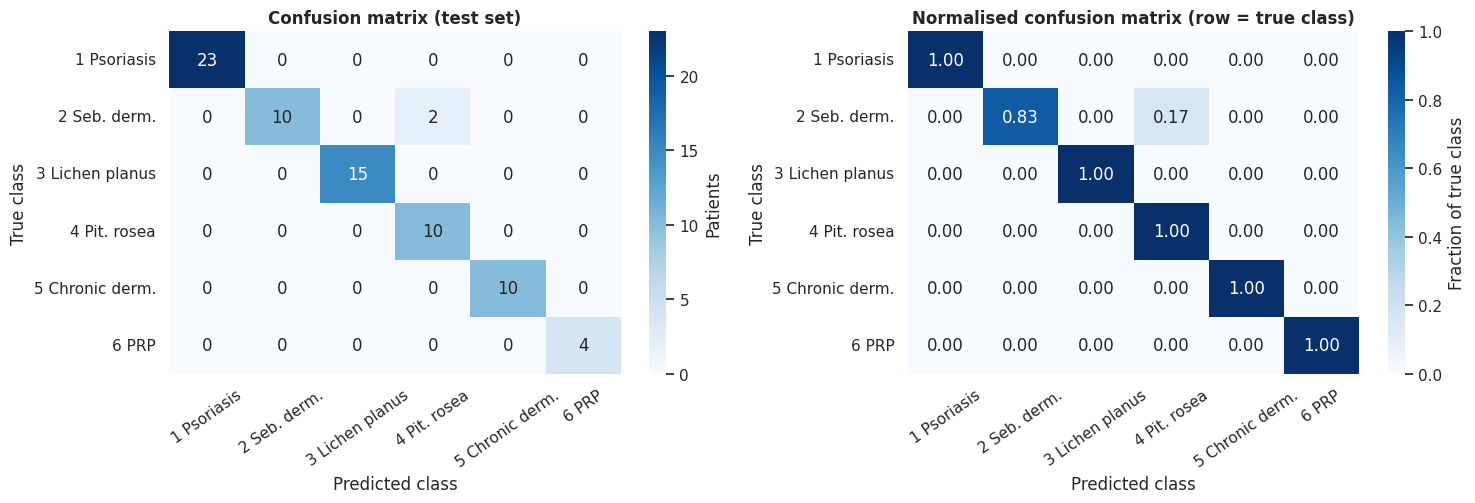

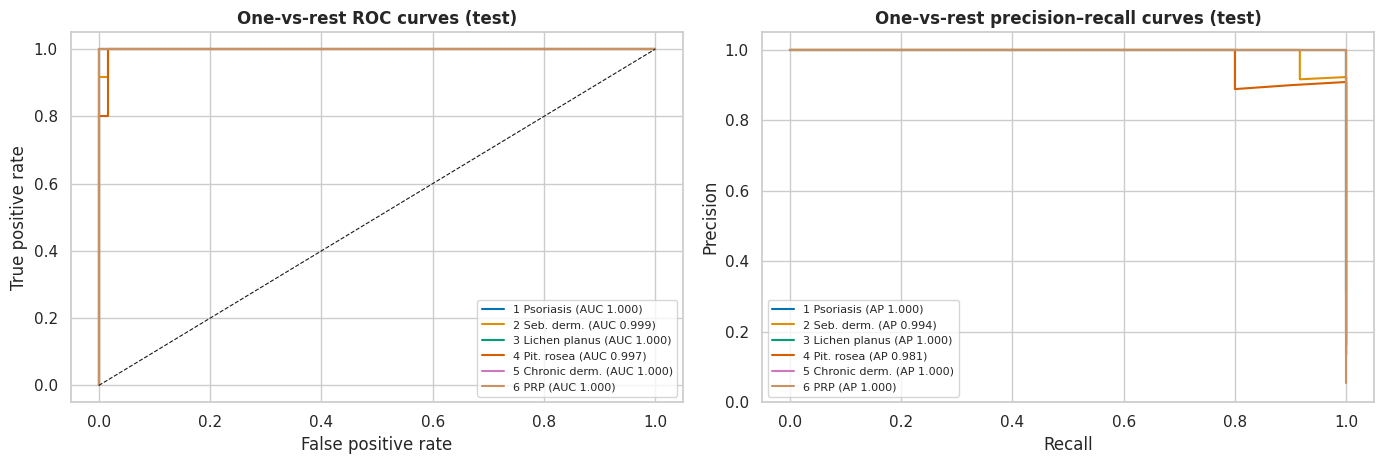

**Interpretation.** Test accuracy **0.973**, macro-F1 **0.970**, balanced accuracy 0.972, MCC 0.967, macro one-vs-rest ROC-AUC 0.999. Class-wise recall: Psoriasis 1.00 (n=23), Seb. derm. 0.83 (n=12), Lichen planus 1.00 (n=15), Pit. rosea 1.00 (n=10), Chronic derm. 1.00 (n=10), PRP 1.00 (n=4). 2 of 74 test patients are misclassified.

In [138]:
cm = confusion_matrix(yt, pred, labels=range(6)); cmn = cm / cm.sum(1, keepdims=True)
tl = [f"{i} {SHORT[i]}" for i in range(1, 7)]
fig, ax = plt.subplots(1, 2, figsize=(15, 5.2))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax[0], xticklabels=tl, yticklabels=tl, cbar_kws={"label": "Patients"}); ax[0].set(title="Confusion matrix (test set)", xlabel="Predicted class", ylabel="True class")
sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax[1], xticklabels=tl, yticklabels=tl, cbar_kws={"label": "Fraction of true class"}); ax[1].set(title="Normalised confusion matrix (row = true class)", xlabel="Predicted class", ylabel="True class")
for a in ax: a.tick_params(axis="x", rotation=35)
plt.tight_layout(); savefig("26_final_confusion_matrices"); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8)); Y1 = np.eye(6)[yt]; aps = {}
for k in range(6):
    fpr, tpr, _ = roc_curve(Y1[:, k], proba[:, k]); ax[0].plot(fpr, tpr, color=CLASS_COLORS[k+1], label=f"{k+1} {SHORT[k+1]} (AUC {roc_auc_score(Y1[:,k], proba[:,k]):.3f})")
    p_, r_, _ = precision_recall_curve(Y1[:, k], proba[:, k]); aps[k] = average_precision_score(Y1[:, k], proba[:, k]); ax[1].plot(r_, p_, color=CLASS_COLORS[k+1], label=f"{k+1} {SHORT[k+1]} (AP {aps[k]:.3f})")
ax[0].plot([0,1],[0,1],"k--", lw=.8); ax[0].set(title="One-vs-rest ROC curves (test)", xlabel="False positive rate", ylabel="True positive rate"); ax[0].legend(fontsize=8, loc="lower right")
ax[1].set(title="One-vs-rest precision–recall curves (test)", xlabel="Recall", ylabel="Precision", ylim=(0, 1.05)); ax[1].legend(fontsize=8, loc="lower left")
plt.tight_layout(); savefig("27_roc_pr_curves"); plt.show()
cls_rec = recall_score(yt, pred, average=None, labels=range(6))
obs(f"Test accuracy **{TEST['accuracy']:.3f}**, macro-F1 **{TEST['macro_f1']:.3f}**, balanced accuracy {TEST['balanced_accuracy']:.3f}, MCC {TEST['mcc']:.3f}, macro one-vs-rest ROC-AUC {TEST['roc_auc_ovr_macro']:.3f}. "
    f"Class-wise recall: " + ", ".join(f"{SHORT[k+1]} {cls_rec[k]:.2f} (n={int(cm[k].sum())})" for k in range(6)) + ". "
    f"{int((pred != yt).sum())} of {len(yt)} test patients are misclassified.")

Test accuracy 95% bootstrap CI: [0.932, 1.000]   Test macro-F1 95% bootstrap CI: [0.917, 1.000]
Inference time: 90.06 ms per single patient, 85.8 ms for the whole test batch (74 patients)
Cross-validation stability (Extra Trees | RandomizedSearch): macro-F1 mean 0.984, SD 0.018, min 0.941, max 1.000 over 15 folds


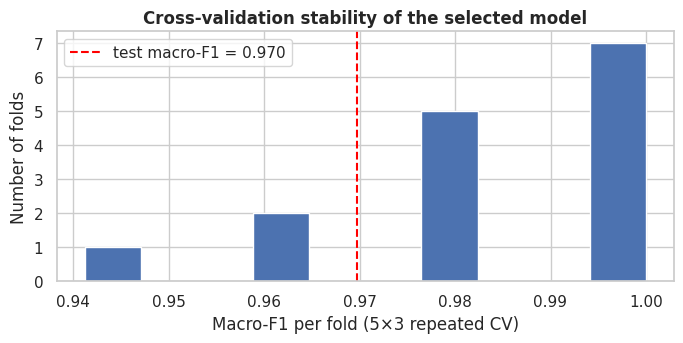

In [139]:
# bootstrap uncertainty on the small test set + inference time + CV stability
rng = np.random.default_rng(SEED); B = 2000; bs = {"accuracy": [], "macro_f1": []}
for _ in range(B):
    ix = rng.integers(0, len(yt), len(yt))
    bs["accuracy"].append(accuracy_score(yt[ix], pred[ix])); bs["macro_f1"].append(f1_score(yt[ix], pred[ix], average="macro"))
ci = {k: np.percentile(v, [2.5, 97.5]) for k, v in bs.items()}
print(f"Test accuracy 95% bootstrap CI: [{ci['accuracy'][0]:.3f}, {ci['accuracy'][1]:.3f}]   Test macro-F1 95% bootstrap CI: [{ci['macro_f1'][0]:.3f}, {ci['macro_f1'][1]:.3f}]")

t0 = time.perf_counter()
for _ in range(100): final_model.predict_proba(X_test.iloc[[0]])
single_ms = (time.perf_counter() - t0)/100*1000
t0 = time.perf_counter(); final_model.predict_proba(X_test); batch_ms = (time.perf_counter() - t0)*1000
print(f"Inference time: {single_ms:.2f} ms per single patient, {batch_ms:.1f} ms for the whole test batch ({len(X_test)} patients)")

sel_cv = CAND_RES[FINAL_NAME]; fold = sel_cv["fold_f1"]
print(f"Cross-validation stability ({FINAL_NAME}): macro-F1 mean {fold.mean():.3f}, SD {fold.std():.3f}, min {fold.min():.3f}, max {fold.max():.3f} over {len(fold)} folds")
fig, ax = plt.subplots(figsize=(7, 3.6)); ax.hist(fold, bins=10, color="#4C72B0"); ax.axvline(TEST["macro_f1"], color="red", ls="--", label=f"test macro-F1 = {TEST['macro_f1']:.3f}")
ax.set(title="Cross-validation stability of the selected model", xlabel="Macro-F1 per fold (5×3 repeated CV)", ylabel="Number of folds"); ax.legend(); plt.tight_layout(); savefig("28_cv_stability"); plt.show()

In [140]:
# prediction error analysis
conf = proba.max(1); second = np.argsort(-proba, 1)[:, 1]
err = pd.DataFrame({"true": [CLASS_NAMES[i+1] for i in yt], "predicted": [CLASS_NAMES[i+1] for i in pred], "confidence": conf.round(3),
                    "runner_up": [CLASS_NAMES[i+1] for i in second], "runner_up_prob": proba[np.arange(len(yt)), second].round(3)}, index=X_test.index)
wrong = err[pred != yt]
print(f"Misclassified test patients: {len(wrong)}"); display(wrong)
ok_c, bad_c = conf[pred == yt], conf[pred != yt]
obs(f"Mean confidence for correct predictions is {ok_c.mean():.2f}" + (f" versus {bad_c.mean():.2f} for the {len(bad_c)} errors, so errors tend to carry lower confidence." if len(bad_c) else "; there were no test errors.") +
    " Test results come from only 74 patients (4 in class 6), so the bootstrap intervals above are the honest range, not a single number.")

Misclassified test patients: 2


,true,predicted,confidence,runner_up,runner_up_prob
140,Seborrheic dermatitis,Pityriasis rosea,0.886,Seborrheic dermatitis,0.114
43,Seborrheic dermatitis,Pityriasis rosea,0.580,Seborrheic dermatitis,0.419


**Interpretation.** Mean confidence for correct predictions is 0.97 versus 0.73 for the 2 errors, so errors tend to carry lower confidence. Test results come from only 74 patients (4 in class 6), so the bootstrap intervals above are the honest range, not a single number.

,flagged_share,errors_caught,accuracy_if_not_flagged,n_flagged
threshold,,,,
0.5,0.000,0.0,0.986,0
0.6,0.021,0.5,0.993,6
0.7,0.031,0.5,0.993,9
0.8,0.058,1.0,1.000,17
0.9,0.068,1.0,1.000,20


Review threshold (largest cut-off flagging <= 20% of training patients): 0.9
Test: flagged 8/74; errors flagged 2/2; accuracy if not flagged = 1.000


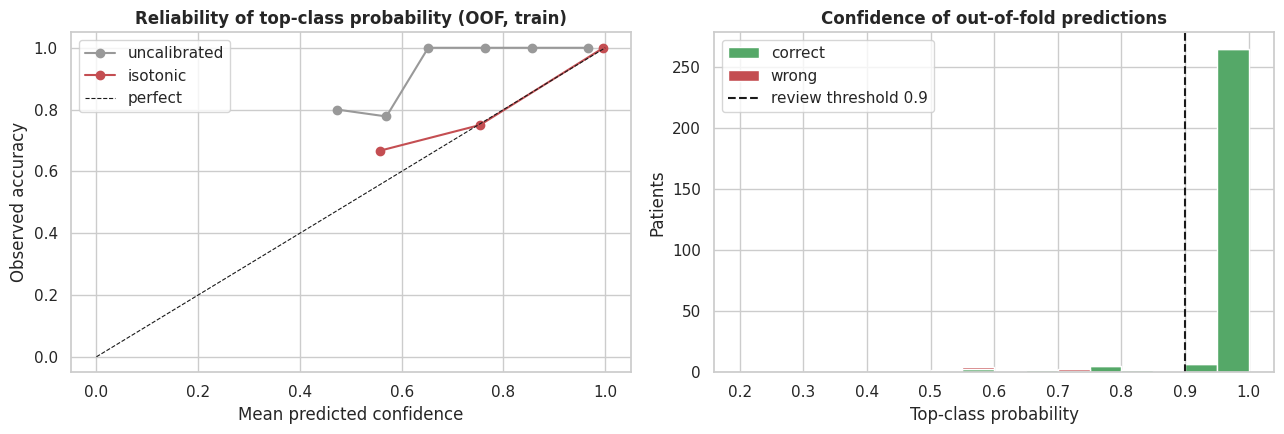

**Interpretation.** Calibration choice: **isotonic** (OOF log-loss 0.038 vs 0.149 uncalibrated). Review rule (fixed before looking at the test set): flag a prediction when its top probability is below the largest candidate cut-off that flags at most 20% of training patients. Flagging predictions with top probability below **0.9** sends 7% of training patients to review and catches 100% of out-of-fold errors; accuracy among non-flagged patients is 1.000.

In [141]:
# reliability and uncertainty analysis on OUT-OF-FOLD TRAINING probabilities (the test set is not used to choose the review threshold)
P_oof = OOFP[CAL_CHOICE]; c_oof, ok_oof = P_oof.max(1), (P_oof.argmax(1) == y_train_enc.values)
rows = []
for th in [0.5, 0.6, 0.7, 0.8, 0.9]:
    flag = c_oof < th; rows.append(dict(threshold=th, flagged_share=flag.mean(), errors_caught=(~ok_oof & flag).sum()/max(1, (~ok_oof).sum()),
                                        accuracy_if_not_flagged=ok_oof[~flag].mean(), n_flagged=int(flag.sum())))
unc = pd.DataFrame(rows).set_index("threshold"); display(unc.round(3))
cands_th = unc[unc.flagged_share <= 0.20]; REVIEW_TH = float(cands_th.index.max()) if len(cands_th) else 0.5
print("Review threshold (largest cut-off flagging <= 20% of training patients):", REVIEW_TH)
flag_te = conf < REVIEW_TH; print(f"Test: flagged {int(flag_te.sum())}/{len(conf)}; errors flagged {int((flag_te & (pred != yt)).sum())}/{int((pred != yt).sum())}; accuracy if not flagged = {(pred == yt)[~flag_te].mean():.3f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for k, c in [("uncalibrated", "#999"), (CAL_CHOICE, "#C44E52")]:
    P = OOFP[k]; cf = P.max(1); acc = (P.argmax(1) == y_train_enc.values)
    edges = np.linspace(0.2, 1.0, 9); xs, ys = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (cf > lo) & (cf <= hi)
        if m.sum() >= 5: xs.append(cf[m].mean()); ys.append(acc[m].mean())
    ax[0].plot(xs, ys, "o-", color=c, label=k)
ax[0].plot([0,1],[0,1],"k--", lw=.8, label="perfect"); ax[0].set(title="Reliability of top-class probability (OOF, train)", xlabel="Mean predicted confidence", ylabel="Observed accuracy"); ax[0].legend()
ax[1].hist([c_oof[ok_oof], c_oof[~ok_oof]], bins=np.linspace(0.2, 1, 17), stacked=True, color=["#55A868", "#C44E52"], label=["correct", "wrong"]); ax[1].axvline(REVIEW_TH, color="k", ls="--", label=f"review threshold {REVIEW_TH}")
ax[1].set(title="Confidence of out-of-fold predictions", xlabel="Top-class probability", ylabel="Patients"); ax[1].legend(); plt.tight_layout(); savefig("29_calibration_uncertainty"); plt.show()
obs(f"Calibration choice: **{CAL_CHOICE}** (OOF log-loss {cal_tab.loc[CAL_CHOICE,'log_loss']:.3f} vs {cal_tab.loc['uncalibrated','log_loss']:.3f} uncalibrated). "
    f"Review rule (fixed before looking at the test set): flag a prediction when its top probability is below the largest candidate cut-off that flags at most 20% of training patients. "
    f"Flagging predictions with top probability below **{REVIEW_TH}** sends {100*unc.loc[REVIEW_TH,'flagged_share']:.0f}% of training patients to review and catches {100*unc.loc[REVIEW_TH,'errors_caught']:.0f}% of out-of-fold errors; "
    f"accuracy among non-flagged patients is {unc.loc[REVIEW_TH,'accuracy_if_not_flagged']:.3f}.")

### 18.1 Calibration diagnostics (added)
The calibration experiment above already compares `uncalibrated`, `sigmoid` and `isotonic` using **out-of-fold (OOF) training predictions** and reports log-loss, **Brier score** (multiclass, summed over classes) and top-label ECE. The cells below add: per-class Brier scores, a check for degenerate (exactly 0 or 1) probabilities, reliability diagrams that show **how many patients** support each point (with 95 % Wilson intervals), and a check on whether the choice of calibrator is stable or over-fitted.

The cells in 18.1 use **training data only** except the clearly labelled "OOF versus test" table, which is descriptive and is **not** used to choose or change anything.

,brier_total,Brier Psoriasis,Brier Seb. derm.,Brier Lichen planus,Brier Pit. rosea,Brier Chronic derm.,Brier PRP,share_prob_exactly_0,share_prob_below_0.001,share_top_prob_at_least_0.999,n_distinct_top_probs
variant,,,,,,,,,,,
uncalibrated,0.0549,0.0043,0.0216,0.0008,0.0181,0.0057,0.0044,0.2163,0.2774,0.0925,260
sigmoid,0.0480,0.0060,0.0157,0.0030,0.0148,0.0043,0.0043,0.0000,0.0000,0.0000,288
isotonic,0.0218,0.0012,0.0105,0.0003,0.0089,0.0005,0.0004,0.7871,0.7939,0.8219,58


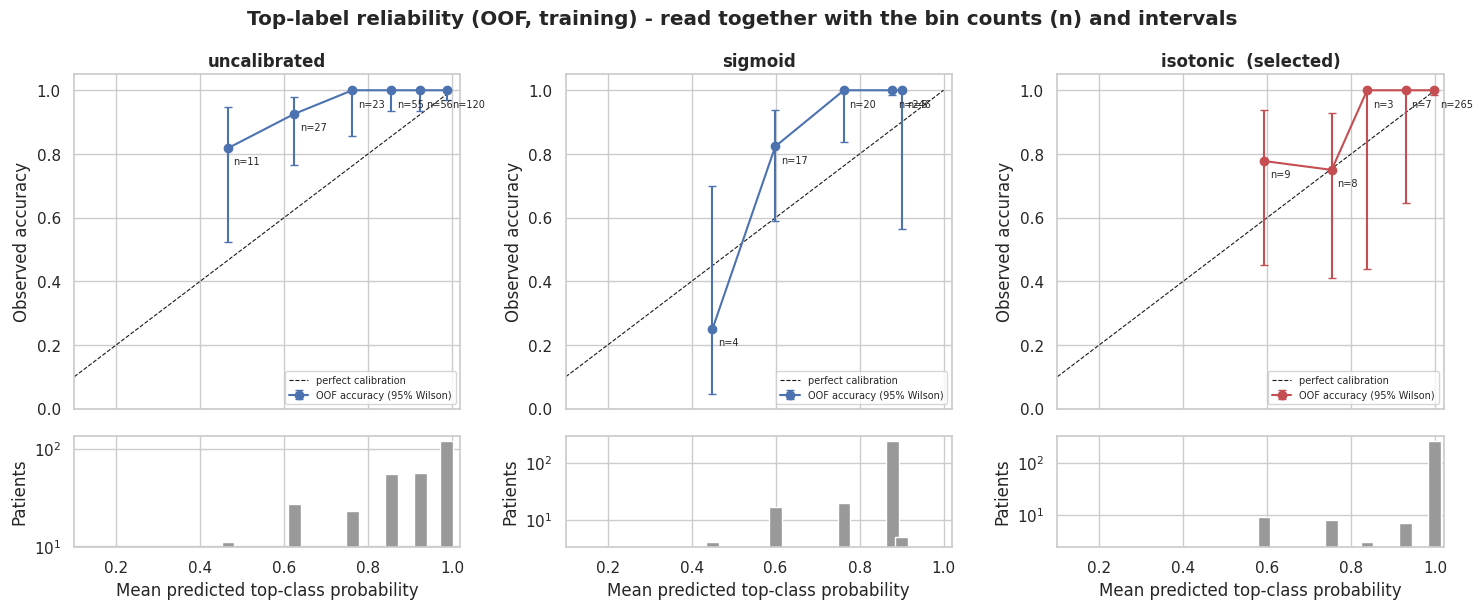

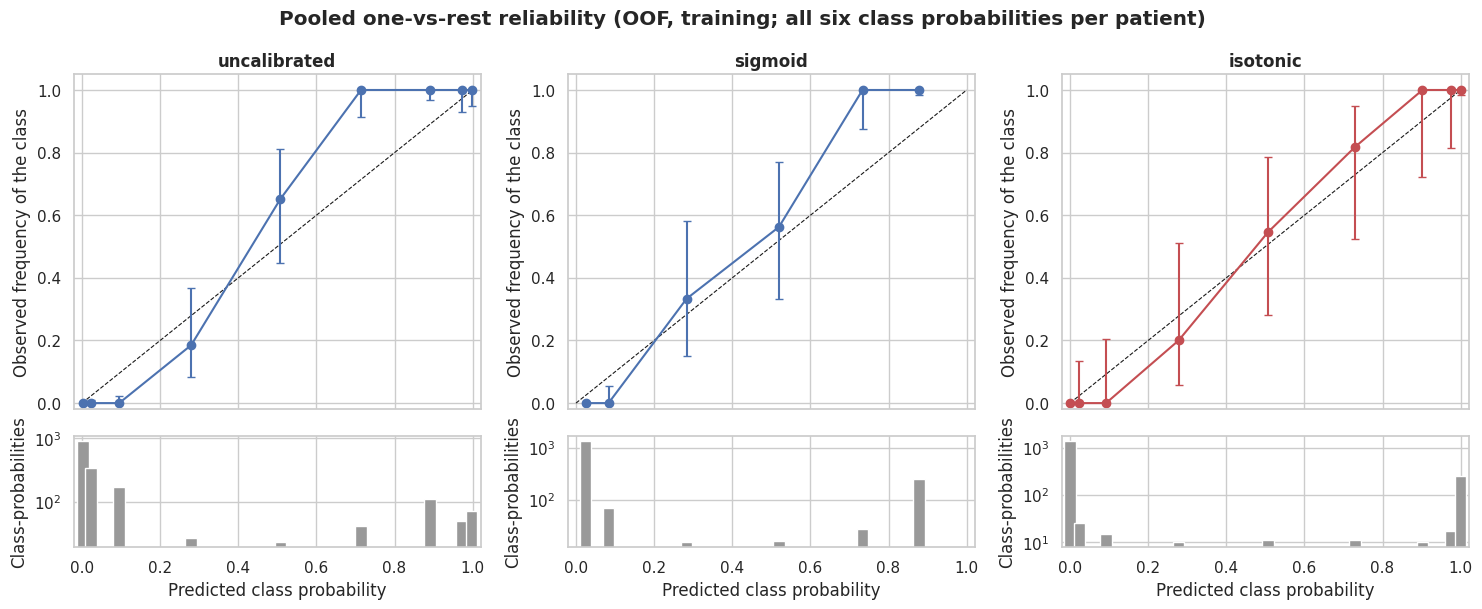

**Interpretation.** Out-of-fold, the selected variant (**isotonic**) makes **4 errors in 292 patients**. With so few errors, every reliability bin contains at most a handful of them and the intervals are wide: the diagram can reveal gross miscalibration but cannot prove good calibration. Exactly-zero class probabilities make up 78.7% of all class probabilities for isotonic (uncalibrated: 21.6%). Exact 0/1 values are a sign of a step-function calibrator and must not be read as certainty.

In [142]:
# 18.1a  Calibration diagnostics on OUT-OF-FOLD TRAINING probabilities (the test set is NOT used in this cell)
cal_variants = {k: variants[k] for k in ("uncalibrated", "sigmoid", "isotonic")}
y_oof = y_train_enc.values

def wilson(k, n, z=1.96):
    """95% Wilson score interval for a binomial proportion (better than the normal interval for small n / extreme p)."""
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z**2 / n; c = p + z**2 / (2*n); a = z * np.sqrt(p*(1-p)/n + z**2/(4*n**2))
    return (c - a) / d, (c + a) / d

def reliability_table(p, outcome, edges):
    p = np.asarray(p, float).ravel(); o = np.asarray(outcome, float).ravel(); rows = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = ((p >= lo) if lo == 0 else (p > lo)) & (p <= hi)
        n = int(m.sum())
        if n:
            k = int(o[m].sum()); l, u = wilson(k, n)
            rows.append(dict(bin=f"({lo:.2f}, {hi:.2f}]", mean_pred=p[m].mean(), observed=k/n, lo=l, hi=u, n=n, n_wrong_or_absent=n-k))
    return pd.DataFrame(rows)

def brier_by_class(y_true, P):
    return ((P - np.eye(P.shape[1])[y_true])**2).mean(axis=0)     # one-vs-rest Brier per class

# per-class Brier + degenerate-probability check
rows = []
for k, P in OOFP.items():
    bc = brier_by_class(y_oof, P)
    rows.append({"variant": k, "brier_total": brier_multi(y_oof, P), **{f"Brier {SHORT[c+1]}": bc[c] for c in range(6)},
                 "share_prob_exactly_0": float((P == 0).mean()), "share_prob_below_0.001": float((P < 1e-3).mean()),
                 "share_top_prob_at_least_0.999": float((P.max(1) >= 0.999).mean()), "n_distinct_top_probs": int(len(np.unique(P.max(1).round(6))))})
cal_diag = pd.DataFrame(rows).set_index("variant"); display(cal_diag.round(4))
cal_diag.to_csv(f"{EVAL_DIR}/calibration_diagnostics_oof.csv")

# Figure 1: top-label reliability with Wilson intervals and bin counts
edges_top = [0.0, 0.5, 0.7, 0.8, 0.9, 0.95, 1.0]
fig, axes = plt.subplots(2, 3, figsize=(15, 6.2), gridspec_kw={"height_ratios": [3, 1]}, sharex="col")
for j, (k, P) in enumerate(OOFP.items()):
    rt = reliability_table(P.max(1), (P.argmax(1) == y_oof), edges_top)
    a, b = axes[0, j], axes[1, j]
    a.plot([0, 1], [0, 1], "k--", lw=.8, label="perfect calibration")
    yerr_lower = np.maximum(0, rt.observed - rt.lo)
    yerr_upper = np.maximum(0, rt.hi - rt.observed)
    a.errorbar(rt.mean_pred, rt.observed, yerr=[yerr_lower, yerr_upper], fmt="o-", capsize=3, color="#C44E52" if k == CAL_CHOICE else "#4C72B0", label="OOF accuracy (95% Wilson)")
    for _, r in rt.iterrows(): a.annotate(f"n={r.n}", (r.mean_pred, r.observed), textcoords="offset points", xytext=(4, -12), fontsize=7)
    a.set(title=f"{k}" + ("  (selected)" if k == CAL_CHOICE else ""), ylabel="Observed accuracy", xlim=(0.1, 1.02), ylim=(0.0, 1.05)); a.legend(fontsize=7, loc="lower right")
    b.bar(rt.mean_pred, rt.n, width=0.03, color="#999"); b.set(xlabel="Mean predicted top-class probability", ylabel="Patients"); b.set_yscale("log")
fig.suptitle("Top-label reliability (OOF, training) - read together with the bin counts (n) and intervals", fontweight="bold")
plt.tight_layout(); savefig("35_calibration_reliability_top_label"); plt.show()

# Figure 2: pooled one-vs-rest reliability (every class probability of every patient)
edges_ovr = [0.0, 0.01, 0.05, 0.2, 0.4, 0.6, 0.8, 0.95, 0.99, 1.0]
fig, axes = plt.subplots(2, 3, figsize=(15, 6.2), gridspec_kw={"height_ratios": [3, 1]}, sharex="col")
for j, (k, P) in enumerate(OOFP.items()):
    rt = reliability_table(P, np.eye(6)[y_oof], edges_ovr)
    a, b = axes[0, j], axes[1, j]
    a.plot([0, 1], [0, 1], "k--", lw=.8)
    yerr_lower = np.maximum(0, rt.observed - rt.lo)
    yerr_upper = np.maximum(0, rt.hi - rt.observed)
    a.errorbar(rt.mean_pred, rt.observed, yerr=[yerr_lower, yerr_upper], fmt="o-", capsize=3, color="#C44E52" if k == CAL_CHOICE else "#4C72B0")
    a.set(title=k, ylabel="Observed frequency of the class", xlim=(-0.02, 1.02), ylim=(-0.02, 1.05))
    b.bar(rt.mean_pred, rt.n, width=0.03, color="#999"); b.set(xlabel="Predicted class probability", ylabel="Class-probabilities"); b.set_yscale("log")
fig.suptitle("Pooled one-vs-rest reliability (OOF, training; all six class probabilities per patient)", fontweight="bold")
plt.tight_layout(); savefig("36_calibration_reliability_ovr"); plt.show()

n_err_oof = int((OOFP[CAL_CHOICE].argmax(1) != y_oof).sum())
obs(f"Out-of-fold, the selected variant (**{CAL_CHOICE}**) makes **{n_err_oof} errors in {len(y_oof)} patients**. "
    + ("With so few errors, every reliability bin contains at most a handful of them and the intervals are wide: the diagram can reveal gross miscalibration but cannot prove good calibration. " if n_err_oof <= 15 else "")
    + f"Exactly-zero class probabilities make up {100*cal_diag.loc[CAL_CHOICE,'share_prob_exactly_0']:.1f}% of all class probabilities for {CAL_CHOICE} "
    f"(uncalibrated: {100*cal_diag.loc['uncalibrated','share_prob_exactly_0']:.1f}%). Exact 0/1 values are a sign of a step-function calibrator and must not be read as certainty.")

In [143]:
# 18.1b  Is the calibration result over-fitted?
# (1) Selection optimism: the calibrator was chosen on OOF folds from `cv5`. Re-estimate all three variants on OTHER fold splits (training data only).
rows = []
for seed in [SEED + 11, SEED + 12, SEED + 13]:
    cvx = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    for k, m in cal_variants.items():
        P = cross_val_predict(clone(m), X_train, y_train_enc, cv=cvx, method="predict_proba")
        rows.append(dict(fold_seed=seed, variant=k, log_loss=log_loss(y_oof, P, labels=range(6)), brier=brier_multi(y_oof, P), ECE=ece_top(y_oof, P),
                         share_prob_exactly_0=float((P == 0).mean())))
rep = pd.DataFrame(rows)
rep_summary = rep.groupby("variant")[["log_loss", "brier", "ECE", "share_prob_exactly_0"]].agg(["mean", "std"]).round(4)
display(rep_summary); rep.to_csv(f"{EVAL_DIR}/calibration_repeat_seeds.csv", index=False)
wins = rep.loc[rep.groupby("fold_seed").log_loss.idxmin(), "variant"].value_counts()
n_seeds = rep.fold_seed.nunique()

# (2) OOF versus test -- DESCRIPTIVE ONLY. Nothing below is used to choose a calibrator, a threshold or any model setting.
P_te = {"uncalibrated": base_model.predict_proba(X_test), CAL_CHOICE: proba}
rows = []
for k, Pt in P_te.items():
    Po = OOFP[k]
    rows.append(dict(variant=k, oof_log_loss=log_loss(y_oof, Po, labels=range(6)), test_log_loss=log_loss(yt, Pt, labels=range(6)),
                     oof_brier=brier_multi(y_oof, Po), test_brier=brier_multi(yt, Pt), oof_ECE=ece_top(y_oof, Po), test_ECE=ece_top(yt, Pt)))
gap = pd.DataFrame(rows).set_index("variant")
gap["test/oof log_loss"] = gap.test_log_loss / gap.oof_log_loss; gap["test/oof brier"] = gap.test_brier / gap.oof_brier
display(gap.round(4)); gap.to_csv(f"{EVAL_DIR}/calibration_oof_vs_test_descriptive.csv")

ratio = float(gap.loc[CAL_CHOICE, "test/oof log_loss"])
obs(f"**Selection stability:** across {n_seeds} independent fold splits of the training data, the lowest log-loss was obtained by " + ", ".join(f"{v} ({n}/{n_seeds})" for v, n in wins.items()) +
    f"; the original choice was **{CAL_CHOICE}**. This only addresses fold-split noise, not the sampling noise of the {len(y_oof)} training patients. "
    f"**OOF versus test (descriptive):** test log-loss of {CAL_CHOICE} is {ratio:.2f}x its OOF value (Brier {float(gap.loc[CAL_CHOICE,'test/oof brier']):.2f}x). "
    + ("A ratio well above 1 suggests the OOF estimate is optimistic; with 74 test patients and 2 errors this comparison is itself very noisy. " if ratio > 1.5 else "No large gap is visible, but 74 test patients and a handful of errors cannot rule out miscalibration. ")
    + "No calibration setting was changed on the basis of the test set.")

log_loss           brier             ECE          \
                 mean     std    mean     std    mean     std   
variant                                                         
isotonic       0.0425  0.0031  0.0249  0.0018  0.0133  0.0024   
sigmoid        0.1799  0.0020  0.0481  0.0014  0.1356  0.0010   
uncalibrated   0.1513  0.0037  0.0567  0.0023  0.1080  0.0017   

             share_prob_exactly_0          
                             mean     std  
variant                                    
isotonic                   0.7873  0.0031  
sigmoid                    0.0000  0.0000  
uncalibrated               0.2218  0.0014

,oof_log_loss,test_log_loss,oof_brier,test_brier,oof_ECE,test_ECE,test/oof log_loss,test/oof brier
variant,,,,,,,,
uncalibrated,0.1487,0.1883,0.0549,0.0813,0.1069,0.1289,1.2659,1.4827
isotonic,0.0375,0.0712,0.0218,0.0436,0.0116,0.0284,1.8949,1.9997


**Interpretation.** **Selection stability:** across 3 independent fold splits of the training data, the lowest log-loss was obtained by isotonic (3/3); the original choice was **isotonic**. This only addresses fold-split noise, not the sampling noise of the 292 training patients. **OOF versus test (descriptive):** test log-loss of isotonic is 1.89x its OOF value (Brier 2.00x). A ratio well above 1 suggests the OOF estimate is optimistic; with 74 test patients and 2 errors this comparison is itself very noisy. No calibration setting was changed on the basis of the test set.

#### How to read the calibration results (limits and cautions)
* **Not clinical probabilities.** The numbers are *model scores* that were post-processed to match observed frequencies **in this single 366-patient research dataset**. They are not patient-level disease risks, and they must not be quoted to patients or used to decide treatment.
* **Very few errors.** Calibration is judged on 292 out-of-fold predictions that contain only a handful of errors; ECE and reliability curves are therefore noisy, and a lower ECE/log-loss does not demonstrate trustworthy probabilities.
* **Isotonic regression is a step function.** With few samples it can output exactly 0 or 1 for a class. Such values are artefacts, not certainty; user interfaces should show them as "<1 %" (or similar) instead of "0 %", and should never be read as "the disease is excluded".
* **Selection optimism.** Choosing the best of three calibrators on the same OOF predictions is slightly optimistic. The repeated-split check above addresses fold-split noise only.
* **High confidence is not correctness.** The error analysis (18.2) shows that wrong predictions can carry high probabilities.
* **No external validation.** Calibration may not transfer to other hospitals, graders, or populations.
* **Model unchanged.** The existing model (Extra Trees + the calibrator chosen in Section 18) is preserved; nothing above provides a *validated* reason to change it.

### 18.2 Misclassification analysis (added; privacy-preserving)
The original error table (Section 18) is retained. The cell below presents **two** error sets: the **out-of-fold training errors** (more reliable, n = 292 patients) and the **test errors** (n = 74, descriptive only). For each error it shows the actual class, the predicted class and the **full six-class probability distribution**, the rank of the actual class, and whether the review flag would have caught it.

**Privacy:** cases get arbitrary sequential IDs (`O01`, `T01`, ...); original row numbers, ages and feature values are **not** shown or saved, and no ID-to-row mapping is kept. The source dataset is a public, anonymised research dataset, but the same discipline should apply to anything shared or published (screenshots, reports, the app).

,case_id,source,actual,predicted,top_prob,runner_up,runner_up_prob,actual_class_rank,prob_of_actual_class,below_review_threshold
0,O01,OOF-train (n=292),Pityriasis rosea,Seborrheic dermatitis,0.714,Pityriasis rosea,0.286,2,0.286,True
1,O02,OOF-train (n=292),Pityriasis rosea,Seborrheic dermatitis,0.744,Pityriasis rosea,0.241,2,0.241,True
2,O03,OOF-train (n=292),Pityriasis rosea,Seborrheic dermatitis,0.567,Pityriasis rosea,0.433,2,0.433,True
3,O04,OOF-train (n=292),Seborrheic dermatitis,Pityriasis rosea,0.534,Seborrheic dermatitis,0.466,2,0.466,True
4,T01,"Test (n=74, descriptive)",Seborrheic dermatitis,Pityriasis rosea,0.886,Seborrheic dermatitis,0.114,2,0.114,True
5,T02,"Test (n=74, descriptive)",Seborrheic dermatitis,Pityriasis rosea,0.580,Seborrheic dermatitis,0.419,2,0.419,True


,case_id,P(Psoriasis),P(Seb. derm.),P(Lichen planus),P(Pit. rosea),P(Chronic derm.),P(PRP)
0,O01,0.0,0.714,0.0,0.286,0.000,0.000
1,O02,0.0,0.744,0.0,0.241,0.015,0.000
2,O03,0.0,0.567,0.0,0.433,0.000,0.000
3,O04,0.0,0.466,0.0,0.534,0.000,0.000
4,T01,0.0,0.114,0.0,0.886,0.000,0.000
5,T02,0.0,0.419,0.0,0.580,0.000,0.001


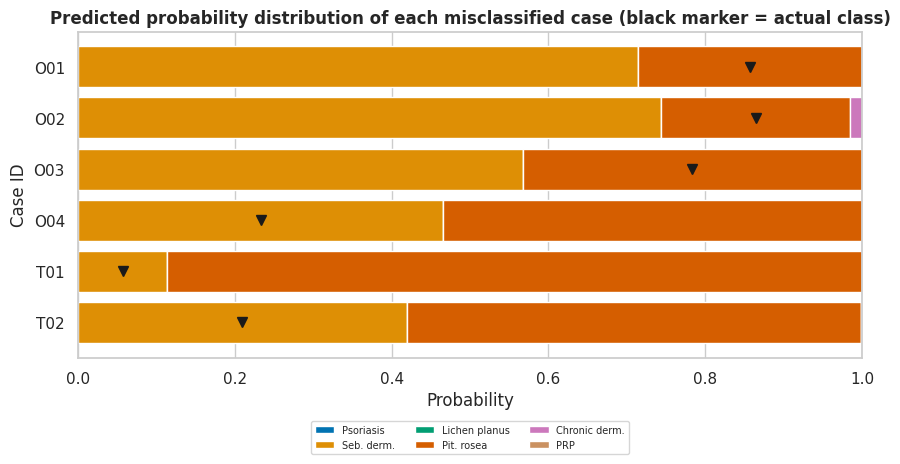

,source,actual,predicted,n_errors
0,OOF-train (n=292),Pityriasis rosea,Seborrheic dermatitis,3
1,OOF-train (n=292),Seborrheic dermatitis,Pityriasis rosea,1
2,"Test (n=74, descriptive)",Seborrheic dermatitis,Pityriasis rosea,2


**Interpretation.** Out-of-fold, 4 of 292 training patients are misclassified; mean top probability is 0.98 for correct predictions and 0.64 for errors. **0 OOF error(s) had a top probability at or above the review threshold (0.9)**, so a high probability does not guarantee a correct prediction whenever this number is above zero. For 4 of the 4 OOF errors the actual class was the model's second choice (`actual_class_rank` = 2). With so few errors these patterns are descriptive and should not be turned into rules.

In [144]:
# 18.2  Misclassification analysis - no original row numbers, ages or feature values are displayed or saved
def error_cases(y_true, P, source, prefix, review_th):
    pr = P.argmax(1); rows = []
    for n, i in enumerate(np.where(pr != y_true)[0], 1):
        order = np.argsort(-P[i]); rank_true = int(np.where(order == y_true[i])[0][0]) + 1
        rows.append({"case_id": f"{prefix}{n:02d}", "source": source, "actual": CLASS_NAMES[int(y_true[i]) + 1], "predicted": CLASS_NAMES[int(pr[i]) + 1],
                     "top_prob": round(float(P[i, order[0]]), 3), "runner_up": CLASS_NAMES[int(order[1]) + 1], "runner_up_prob": round(float(P[i, order[1]]), 3),
                     "actual_class_rank": rank_true, "prob_of_actual_class": round(float(P[i, y_true[i]]), 3),
                     "below_review_threshold": bool(P[i].max() < review_th),
                     **{f"P({SHORT[c+1]})": round(float(P[i, c]), 3) for c in range(6)}})
    return pd.DataFrame(rows)

P_oof_sel = OOFP[CAL_CHOICE]
err_all = pd.concat([error_cases(y_oof, P_oof_sel, "OOF-train (n=%d)" % len(y_oof), "O", REVIEW_TH),
                     error_cases(yt, proba, "Test (n=%d, descriptive)" % len(yt), "T", REVIEW_TH)], ignore_index=True)
display(err_all.drop(columns=[c for c in err_all.columns if c.startswith("P(")]))      # compact view
display(err_all[["case_id"] + [c for c in err_all.columns if c.startswith("P(")]])      # full probability distribution
err_all.to_csv(f"{EVAL_DIR}/error_analysis_privacy_safe.csv", index=False)

# figure: probability distribution for every error case (marker = actual class)
if len(err_all):
    fig, ax = plt.subplots(figsize=(9, 0.55*len(err_all) + 1.6)); cols = [c for c in err_all.columns if c.startswith("P(")]; left = np.zeros(len(err_all))
    for c_i, c in enumerate(cols):
        ax.barh(err_all.case_id, err_all[c], left=left, color=CLASS_COLORS[c_i+1], label=c[2:-1]); left += err_all[c].values
    for yi, (_, r) in enumerate(err_all.iterrows()):
        cum = err_all.loc[yi, cols].values.cumsum(); k_true = [n for n in range(1, 7) if CLASS_NAMES[n] == r.actual][0] - 1
        ax.plot((cum[k_true] - err_all.loc[yi, cols[k_true]] / 2), yi, marker="v", color="k", markersize=7)
    ax.invert_yaxis(); ax.set(title="Predicted probability distribution of each misclassified case (black marker = actual class)", xlabel="Probability", ylabel="Case ID", xlim=(0, 1))
    ax.legend(fontsize=7, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.18)); plt.tight_layout(); savefig("37_error_probability_distributions"); plt.show()

# aggregate patterns
pat = err_all.groupby(["source", "actual", "predicted"]).size().rename("n_errors").reset_index(); display(pat)
ok_o = (P_oof_sel.argmax(1) == y_oof); co = P_oof_sel.max(1)
n_hi = int((err_all.query("source.str.startswith('OOF')", engine="python").top_prob >= REVIEW_TH).sum())
oof_err = err_all[err_all.source.str.startswith("OOF")]; n_rank2 = int((oof_err.actual_class_rank == 2).sum())
obs(f"Out-of-fold, {int((~ok_o).sum())} of {len(y_oof)} training patients are misclassified; mean top probability is {co[ok_o].mean():.2f} for correct predictions and "
    f"{(co[~ok_o].mean() if (~ok_o).any() else float('nan')):.2f} for errors. **{n_hi} OOF error(s) had a top probability at or above the review threshold ({REVIEW_TH})**, "
    f"so a high probability does not guarantee a correct prediction whenever this number is above zero. "
    f"For {n_rank2} of the {len(oof_err)} OOF errors the actual class was the model's second choice (`actual_class_rank` = 2). "
    f"With so few errors these patterns are descriptive and should not be turned into rules.")

## 19. Explainable AI with SHAP
SHAP values describe how each feature moved the model's predicted probability for each class. They explain **the model**, not medicine: they do not establish causation and are not diagnostic rules. The (uncalibrated) selected pipeline is explained on the **test patients**; no model decisions depend on this section.

**Revision notes (post-audit).**
* **Post-evaluation, descriptive.** SHAP values are computed *after* the final test evaluation, on the test patients, to help humans inspect the model. They are **not** used to select features, tune the model, choose the calibrator or set the review threshold, and they must not be used that way.
* **Which model is explained.** SHAP explains the **uncalibrated** Extra Trees pipeline (`base_model`), while the probabilities reported in Section 18 come from the **calibrated** `final_model`. The calibration step (a monotone remapping of probabilities) is not part of the explanation, so SHAP contributions and the reported probabilities are related but not identical.
* **Illustrative examples are not representative.** The individual-patient explanation deliberately uses a *misclassified* test patient. It illustrates how an error can arise; it says nothing about typical cases.
* **Explains the model, not the disease.** SHAP does not show causation or diagnostic criteria. With 74 test patients the global ranking is noisy; a training-patient ranking is added after the permutation-importance cell for comparison.


In [145]:
import shap
pre, clf = base_model[:-1], base_model[-1]
Xt = pd.DataFrame(pre.transform(X_test), columns=FEATURES, index=X_test.index)       # imputed (and scaled if the pipeline scales) test features
Xt_raw = X_test.copy()
TREE_TYPES = (RandomForestClassifier, ExtraTreesClassifier, XGBClassifier, CatBoostClassifier, GradientBoostingClassifier)
def to3d(sv):
    if isinstance(sv, list): return np.stack(sv, axis=-1)
    sv = sv.values if hasattr(sv, "values") else np.asarray(sv)
    return sv

t0 = time.time()
if isinstance(clf, TREE_TYPES):
    expl = shap.TreeExplainer(clf); sv = to3d(expl.shap_values(Xt)); ev = np.ravel(expl.expected_value); kind = "TreeExplainer"
else:
    bg = pd.DataFrame(pre.transform(X_train), columns=FEATURES)
    bg = bg.sample(60, random_state=SEED)
    expl = shap.Explainer(clf.predict_proba, bg, seed=SEED); ex = expl(Xt); sv = to3d(ex); ev = np.ravel(ex.base_values[0]); kind = "model-agnostic Explainer (permutation)"
print(f"{type(clf).__name__}: {kind}; SHAP array {sv.shape} (patients, features, classes) in {time.time()-t0:.0f}s")
if sv.shape == (len(Xt), 6, len(FEATURES)): sv = np.transpose(sv, (0, 2, 1))      # some versions return (patients, classes, features)
assert sv.shape == (len(Xt), len(FEATURES), 6), sv.shape
mean_abs = np.abs(sv).mean(axis=(0, 2)); shap_global = pd.Series(mean_abs, index=FEATURES).sort_values(ascending=False)
display(shap_global.head(12).round(4).to_frame("mean |SHAP| (all classes)"))

ExtraTreesClassifier: TreeExplainer; SHAP array (74, 34, 6) (patients, features, classes) in 0s


,mean |SHAP| (all classes)
clubbing_of_the_rete_ridges,0.0375
elongation_of_the_rete_ridges,0.0304
fibrosis_of_the_papillary_dermis,0.0293
spongiosis,0.0277
thinning_of_the_suprapapillary_epidermis,0.0228
vacuolisation_and_damage_of_basal_layer,0.0200
koebner_phenomenon,0.0198
PNL_infiltrate,0.0169
saw-tooth_appearance_of_retes,0.0169
knee_and_elbow_involvement,0.0137


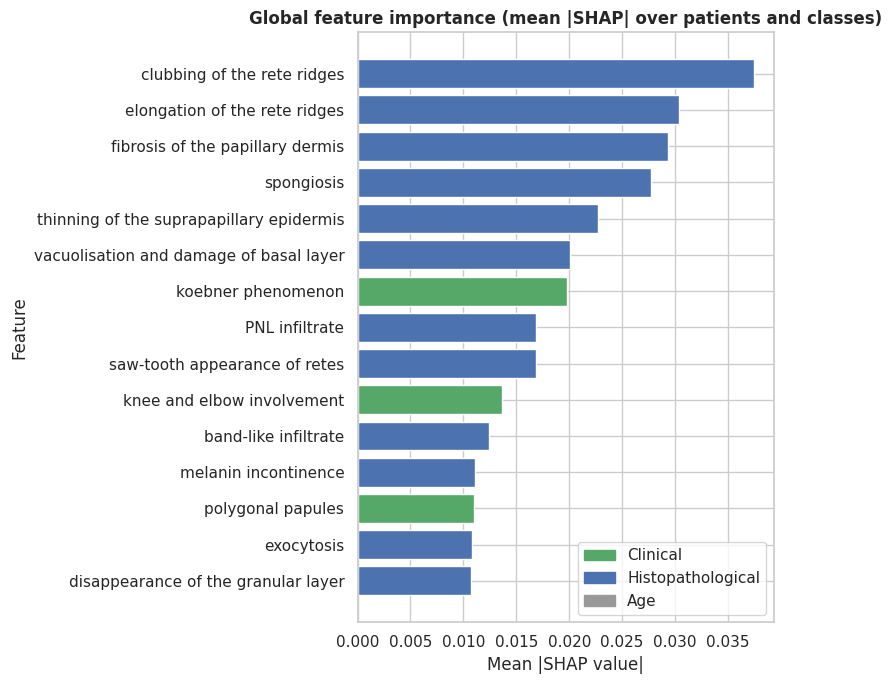

**Interpretation.** Top features by mean |SHAP|: clubbing_of_the_rete_ridges, elongation_of_the_rete_ridges, fibrosis_of_the_papillary_dermis, spongiosis, thinning_of_the_suprapapillary_epidermis. Of the top 15, **12 are histopathological, 3 clinical**, 0 Age.

In [146]:
fig, ax = plt.subplots(figsize=(8, 7)); t = shap_global.head(15).iloc[::-1]
ax.barh([i.replace("_", " ") for i in t.index], t.values, color=["#55A868" if i in CLINICAL else "#4C72B0" if i in HISTO else "#999" for i in t.index])
ax.set(title="Global feature importance (mean |SHAP| over patients and classes)", xlabel="Mean |SHAP value|", ylabel="Feature")
ax.legend(handles=[Patch(color="#55A868", label="Clinical"), Patch(color="#4C72B0", label="Histopathological"), Patch(color="#999", label="Age")], loc="lower right"); plt.tight_layout(); savefig("30_shap_global_bar"); plt.show()
g15 = shap_global.head(15)
obs(f"Top features by mean |SHAP|: {', '.join(shap_global.index[:5])}. Of the top 15, **{sum(i in HISTO for i in g15.index)} are histopathological, {sum(i in CLINICAL for i in g15.index)} clinical**, {sum(i=='Age' for i in g15.index)} Age.")

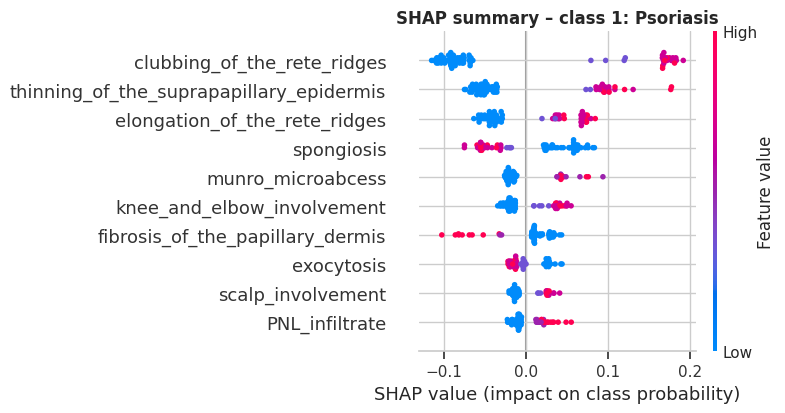

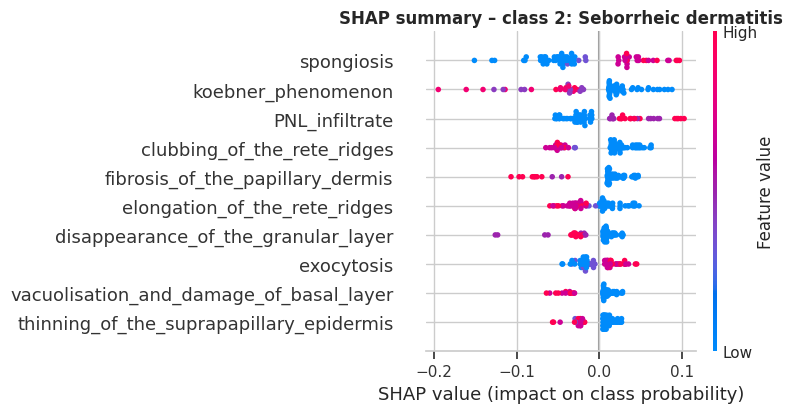

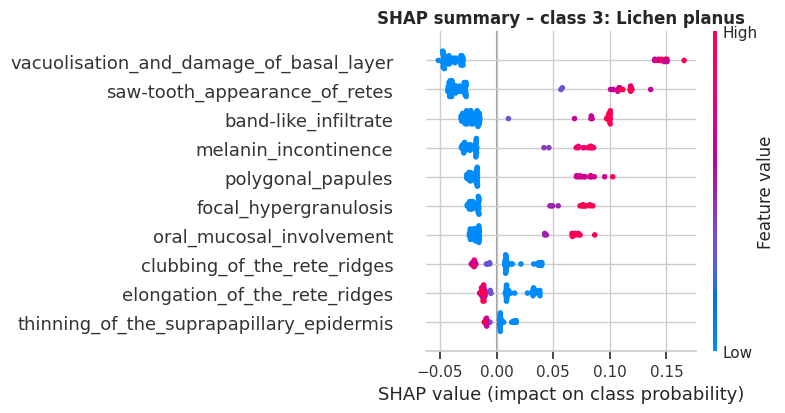

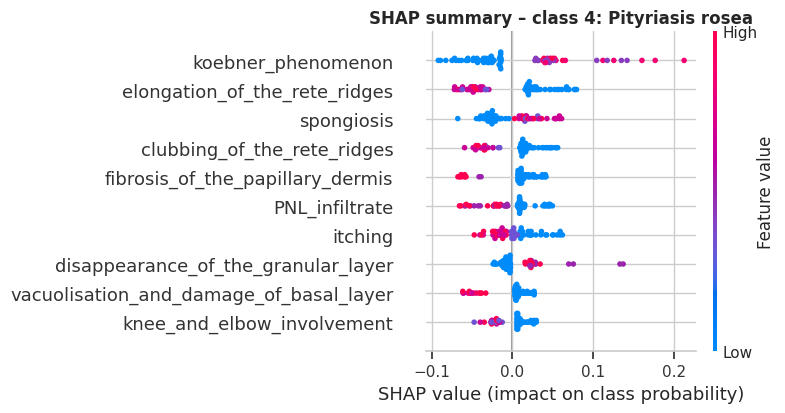

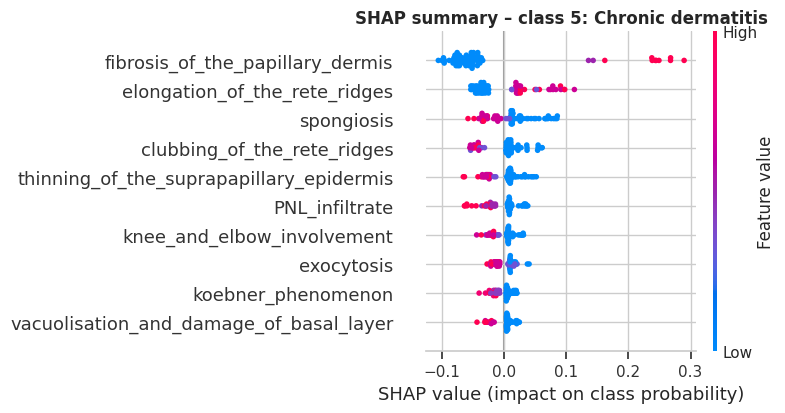

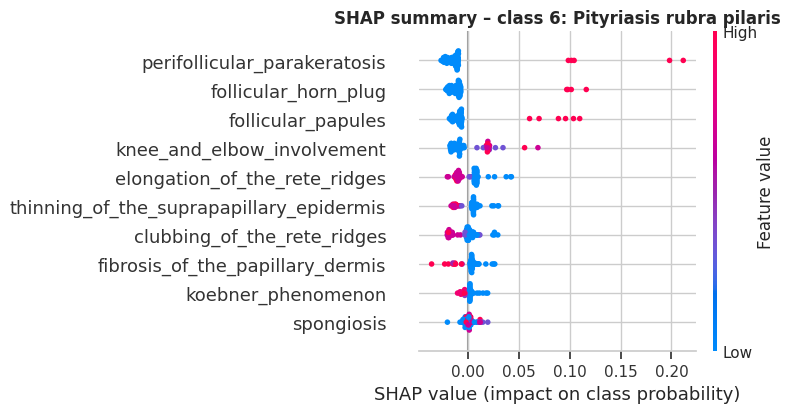

In [147]:
# beeswarm summary per class (feature values shown in original units for readability)
for k in range(6):
    plt.figure(); shap.summary_plot(sv[:, :, k], Xt_raw, feature_names=FEATURES, max_display=10, show=False, plot_size=(8, 4.3))
    plt.title(f"SHAP summary – class {k+1}: {CLASS_NAMES[k+1]}", fontweight="bold"); plt.xlabel("SHAP value (impact on class probability)")
    plt.tight_layout(); savefig(f"31_shap_summary_class{k+1}"); plt.show()

In [148]:
# class-specific contributions
cls_top = {CLASS_NAMES[k+1]: pd.Series(np.abs(sv[:, :, k]).mean(0), index=FEATURES).sort_values(ascending=False).head(5) for k in range(6)}
cs = pd.DataFrame({c: [f"{f} ({v:.3f})" for f, v in s.items()] for c, s in cls_top.items()}, index=[f"#{i}" for i in range(1, 6)]); display(cs)
obs("Top-5 features by mean |SHAP| are listed per class above. Different diseases are driven by different findings, consistent with the class profiles in Section 8.12, e.g. " +
    "; ".join(f"**{c}**: {s.index[0]}" for c, s in list(cls_top.items())[:3]) + ".")

,Psoriasis,Seborrheic dermatitis,Lichen planus,Pityriasis rosea,Chronic dermatitis,Pityriasis rubra pilaris
#1,clubbing_of_the_rete_ridges (0.112),spongiosis (0.053),vacuolisation_and_damage_of_basal_layer (0.060),koebner_phenomenon (0.053),fibrosis_of_the_papillary_dermis (0.088),perifollicular_parakeratosis (0.024)
#2,thinning_of_the_suprapapillary_epidermis (0.068),koebner_phenomenon (0.044),saw-tooth_appearance_of_retes (0.051),elongation_of_the_rete_ridges (0.043),elongation_of_the_rete_ridges (0.041),follicular_horn_plug (0.017)
#3,elongation_of_the_rete_ridges (0.050),PNL_infiltrate (0.035),band-like_infiltrate (0.037),spongiosis (0.028),spongiosis (0.030),follicular_papules (0.017)
#4,spongiosis (0.048),clubbing_of_the_rete_ridges (0.035),melanin_incontinence (0.033),clubbing_of_the_rete_ridges (0.026),clubbing_of_the_rete_ridges (0.027),knee_and_elbow_involvement (0.015)
#5,munro_microabcess (0.027),fibrosis_of_the_papillary_dermis (0.028),polygonal_papules (0.033),fibrosis_of_the_papillary_dermis (0.023),thinning_of_the_suprapapillary_epidermis (0.020),elongation_of_the_rete_ridges (0.010)


**Interpretation.** Top-5 features by mean |SHAP| are listed per class above. Different diseases are driven by different findings, consistent with the class profiles in Section 8.12, e.g. **Psoriasis**: clubbing_of_the_rete_ridges; **Seborrheic dermatitis**: spongiosis; **Lichen planus**: vacuolisation_and_damage_of_basal_layer.

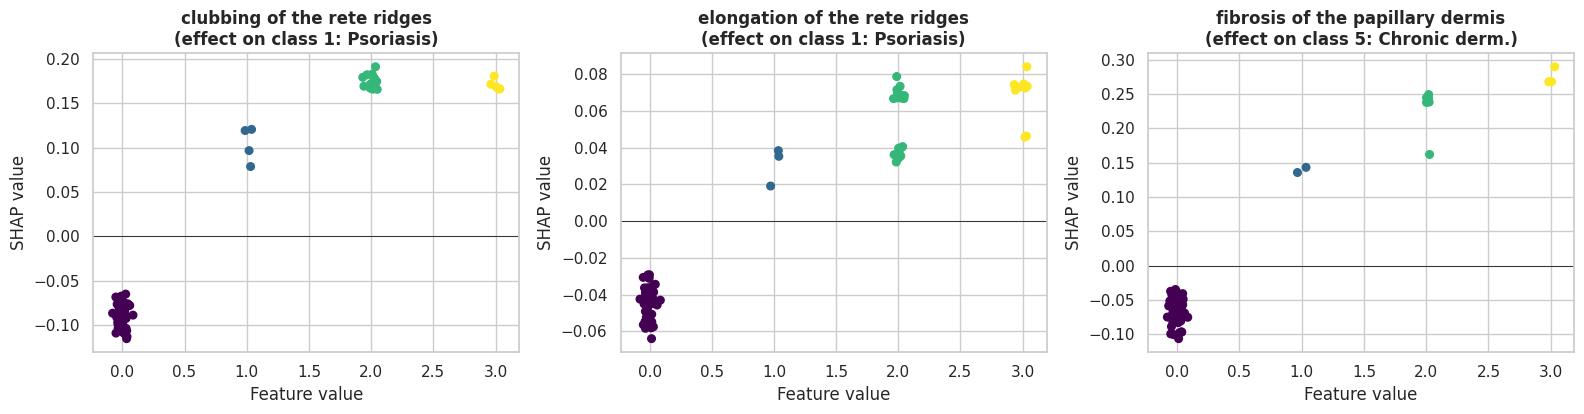

In [149]:
# dependence plots for the top-3 features, for the class they influence most
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for a, f in zip(axes, shap_global.index[:3]):
    fi = FEATURES.index(f); k = int(np.abs(sv[:, fi, :]).mean(0).argmax())
    jitter = np.random.default_rng(SEED).normal(0, 0.04, len(Xt_raw))
    sc_ = a.scatter(Xt_raw[f].values + jitter, sv[:, fi, k], c=Xt_raw[f].values, cmap="viridis", s=30)
    a.axhline(0, color="k", lw=.6); a.set(title=f"{f.replace('_',' ')}\n(effect on class {k+1}: {SHORT[k+1]})", xlabel="Feature value", ylabel="SHAP value")
plt.tight_layout(); savefig("32_shap_dependence"); plt.show()

Patient (row 140): true = Seborrheic dermatitis, predicted = Pityriasis rosea (confidence 0.89)


,Psoriasis,Seborrheic dermatitis,Lichen planus,Pityriasis rosea,Chronic dermatitis,Pityriasis rubra pilaris
class probability,0.0,0.114,0.0,0.886,0.0,0.0


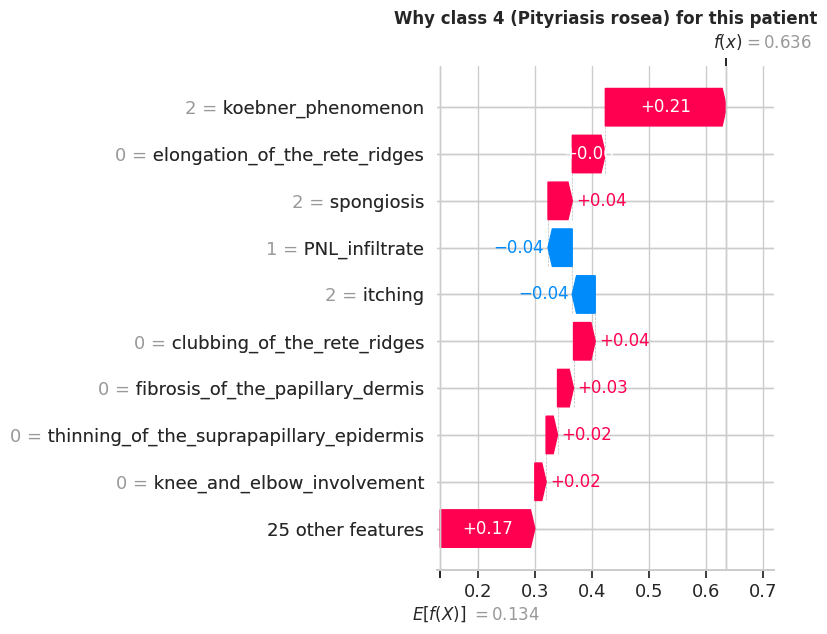

In [150]:
# individual patient explanation: first misclassified patient, otherwise the lowest-confidence test patient
idx = int(np.where(pred != yt)[0][0]) if (pred != yt).any() else int(conf.argmin())
k = int(pred[idx]); pid = X_test.index[idx]
print(f"Patient (row {pid}): true = {CLASS_NAMES[yt[idx]+1]}, predicted = {CLASS_NAMES[k+1]} (confidence {conf[idx]:.2f})")
display(pd.Series({CLASS_NAMES[c+1]: round(float(proba[idx, c]), 3) for c in range(6)}).to_frame("class probability").T)
exp = shap.Explanation(values=sv[idx, :, k], base_values=ev[k] if len(ev) > k else 0, data=Xt_raw.iloc[idx].values, feature_names=FEATURES)
plt.figure(); shap.plots.waterfall(exp, max_display=10, show=False); plt.title(f"Why class {k+1} ({CLASS_NAMES[k+1]}) for this patient", fontweight="bold"); plt.tight_layout(); savefig("33_shap_individual_patient"); plt.show()

> ⚠️ **Descriptive only.** The permutation importance in the next cell is computed **on the test set**. It is shown purely to compare with SHAP after the evaluation. It must **not** be used for feature selection, feature removal, model selection or tuning - doing so would turn the test set into a tuning set and invalidate the test estimate. (Selection-grade permutation importance, computed on held-out *training* CV folds, is in Section 12.) With 74 test patients, importances are noisy and correlated findings share credit.

,mean|SHAP|,permutation_dF1_test,"permutation_dF1_trainCV(RF, Sec.12)"
clubbing_of_the_rete_ridges,0.0375,0.0249,-0.0021
elongation_of_the_rete_ridges,0.0304,0.0200,-0.0048
fibrosis_of_the_papillary_dermis,0.0293,0.0496,0.0385
spongiosis,0.0277,0.0205,-0.0015
thinning_of_the_suprapapillary_epidermis,0.0228,0.0186,0.0032
vacuolisation_and_damage_of_basal_layer,0.0200,0.0005,0.0000
koebner_phenomenon,0.0198,0.0503,0.0715
PNL_infiltrate,0.0169,0.0404,-0.0019
saw-tooth_appearance_of_retes,0.0169,0.0000,0.0000
knee_and_elbow_involvement,0.0137,0.0172,-0.0024


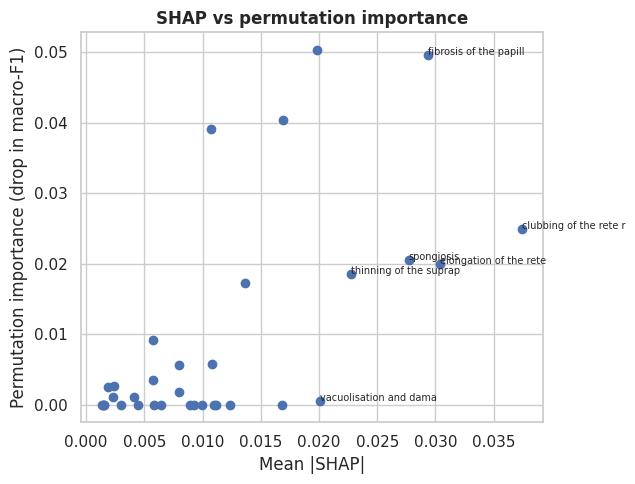

**Interpretation.** SHAP and test-set permutation importance agree moderately (Spearman ρ = 0.54; vs training-CV permutation ρ = 0.37); 8 of the top-10 features appear in both. Permutation importance is near zero for many features because correlated findings (Section 8.3) can substitute for each other, whereas SHAP shares credit among them; with 74 test patients both are noisy. Neither shows medical causation.

In [151]:
# compare SHAP with permutation importance (computed on the test set, scoring macro-F1)
pi = permutation_importance(base_model, X_test, y_test_enc, n_repeats=30, scoring="f1_macro", random_state=SEED, n_jobs=1)
perm_te = pd.Series(pi.importances_mean, index=FEATURES)
cmp_ = pd.DataFrame({"mean|SHAP|": shap_global, "permutation_dF1_test": perm_te.reindex(shap_global.index), "permutation_dF1_trainCV(RF, Sec.12)": perm.reindex(shap_global.index)})
rho_test = stats.spearmanr(cmp_["mean|SHAP|"], cmp_["permutation_dF1_test"])[0]; rho_cv = stats.spearmanr(cmp_["mean|SHAP|"], cmp_["permutation_dF1_trainCV(RF, Sec.12)"])[0]
display(cmp_.head(10).round(4))
fig, ax = plt.subplots(figsize=(6.5, 5)); ax.scatter(cmp_["mean|SHAP|"], cmp_["permutation_dF1_test"], color="#4C72B0")
for f in cmp_.index[:6]: ax.annotate(f.replace("_", " ")[:22], (cmp_.loc[f, "mean|SHAP|"], cmp_.loc[f, "permutation_dF1_test"]), fontsize=7)
ax.set(title="SHAP vs permutation importance", xlabel="Mean |SHAP|", ylabel="Permutation importance (drop in macro-F1)"); plt.tight_layout(); savefig("34_shap_vs_permutation"); plt.show()
top_s, top_p = set(shap_global.index[:10]), set(perm_te.sort_values(ascending=False).index[:10])
obs(f"SHAP and test-set permutation importance agree moderately (Spearman ρ = {rho_test:.2f}; vs training-CV permutation ρ = {rho_cv:.2f}); {len(top_s & top_p)} of the top-10 features appear in both. "
    "Permutation importance is near zero for many features because correlated findings (Section 8.3) can substitute for each other, whereas SHAP shares credit among them; with 74 test patients both are noisy. "
    "Neither shows medical causation.")

,mean|SHAP| train patients,mean|SHAP| test patients
clubbing_of_the_rete_ridges,0.0374,0.0375
fibrosis_of_the_papillary_dermis,0.0295,0.0293
elongation_of_the_rete_ridges,0.0294,0.0304
spongiosis,0.0272,0.0277
thinning_of_the_suprapapillary_epidermis,0.0216,0.0228
vacuolisation_and_damage_of_basal_layer,0.0200,0.0200
koebner_phenomenon,0.0195,0.0198
saw-tooth_appearance_of_retes,0.0165,0.0169
PNL_infiltrate,0.0161,0.0169
knee_and_elbow_involvement,0.0138,0.0137


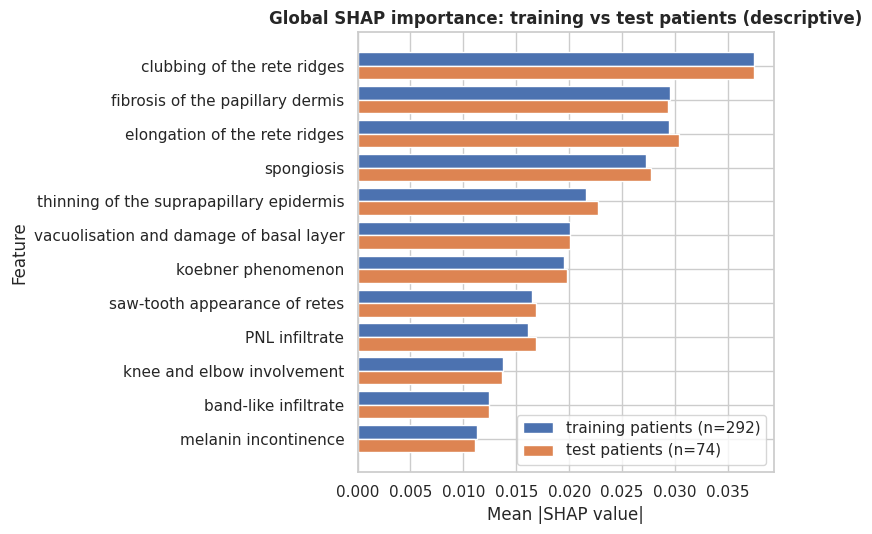

**Interpretation.** The SHAP ranking on training vs test patients has Spearman rho = 1.00; 10 of the top-10 features appear in both. The global ranking is broadly consistent, so it does not hinge on the 74 test patients. This is a description of the model's behaviour; it is not evidence that these findings are diagnostically causal.

In [152]:
# SHAP ranking on TRAINING patients (same fitted, uncalibrated model) - descriptive comparison with the test-patient ranking above.
# These are in-sample explanations of a model that has seen these patients; they describe model behaviour and are not a performance estimate.
if isinstance(clf, TREE_TYPES):
    Xtr_t = pd.DataFrame(pre.transform(X_train), columns=FEATURES, index=X_train.index)
    sv_tr = to3d(expl.shap_values(Xtr_t))
    if sv_tr.shape == (len(Xtr_t), 6, len(FEATURES)): sv_tr = np.transpose(sv_tr, (0, 2, 1))
    assert sv_tr.shape == (len(Xtr_t), len(FEATURES), 6), sv_tr.shape
    shap_global_tr = pd.Series(np.abs(sv_tr).mean(axis=(0, 2)), index=FEATURES).sort_values(ascending=False)
    cmp_tr = pd.DataFrame({"mean|SHAP| train patients": shap_global_tr, "mean|SHAP| test patients": shap_global.reindex(shap_global_tr.index)})
    rho_tr = stats.spearmanr(cmp_tr.iloc[:, 0], cmp_tr.iloc[:, 1])[0]; ov = len(set(shap_global_tr.index[:10]) & set(shap_global.index[:10]))
    display(cmp_tr.head(10).round(4))
    t = cmp_tr.head(12).iloc[::-1]; fig, ax = plt.subplots(figsize=(8, 5.5)); yy = np.arange(len(t))
    ax.barh(yy + 0.2, t.iloc[:, 0], height=0.4, color="#4C72B0", label="training patients (n=%d)" % len(Xtr_t)); ax.barh(yy - 0.2, t.iloc[:, 1], height=0.4, color="#DD8452", label="test patients (n=%d)" % len(Xt))
    ax.set_yticks(yy); ax.set_yticklabels([i.replace("_", " ") for i in t.index]); ax.set(title="Global SHAP importance: training vs test patients (descriptive)", xlabel="Mean |SHAP value|", ylabel="Feature"); ax.legend()
    plt.tight_layout(); savefig("38_shap_train_vs_test"); plt.show()
    similar = rho_tr >= 0.7
    obs(f"The SHAP ranking on training vs test patients has Spearman rho = {rho_tr:.2f}; {ov} of the top-10 features appear in both. "
        + ("The global ranking is broadly consistent, so it does not hinge on the 74 test patients. " if similar else "The rankings differ noticeably, so the 74-patient test ranking should be read with caution. ")
        + "This is a description of the model's behaviour; it is not evidence that these findings are diagnostically causal.")
else:
    print("Training-patient SHAP comparison is implemented for tree models only; the selected model is not a tree ensemble.")

## 20. Doctor recommendations and decision support (Task 3)
Everything below is derived from this dataset's results and is an **association-based, educational** analysis, not clinical guidance.

> **Revision:** the original "Suggestions to doctors" cell below is kept for the audit trail but is **superseded by Section 20.1** (more cautious wording, explicit specialist-review warnings, low-confidence explanation, disclaimers). Nothing in this section is treatment or diagnostic advice.


In [153]:
# (a) most distinctive findings per disease (mean grade in the disease minus mean grade in all other patients; full data, descriptive)
G = [f for f in FEATURES if f != "Age"]; rows = []
for c in range(1, 7):
    diff = (df.loc[df["class"] == c, G].mean() - df.loc[df["class"] != c, G].mean()).sort_values(ascending=False).head(4)
    rows.append([CLASS_NAMES[c], ", ".join(f"{f} (+{v:.1f}, {'clin' if f in CLINICAL else 'histo'})" for f, v in diff.items())])
display(pd.DataFrame(rows, columns=["Disease", "Findings most elevated vs other patients"]).style.hide(axis="index"))

Disease,Findings most elevated vs other patients
Psoriasis,"clubbing_of_the_rete_ridges (+2.1, histo), thinning_of_the_suprapapillary_epidermis (+2.0, histo), elongation_of_the_rete_ridges (+1.8, histo), knee_and_elbow_involvement (+1.5, clin)"
Seborrheic dermatitis,"spongiosis (+1.5, histo), exocytosis (+1.0, histo), PNL_infiltrate (+0.6, histo), eosinophils_in_the_infiltrate (+0.4, histo)"
Lichen planus,"band-like_infiltrate (+2.7, histo), vacuolisation_and_damage_of_basal_layer (+2.3, histo), saw-tooth_appearance_of_retes (+2.3, histo), polygonal_papules (+2.3, clin)"
Pityriasis rosea,"spongiosis (+1.2, histo), exocytosis (+0.8, histo), koebner_phenomenon (+0.6, clin), disappearance_of_the_granular_layer (+-0.1, histo)"
Chronic dermatitis,"fibrosis_of_the_papillary_dermis (+2.3, histo), elongation_of_the_rete_ridges (+1.0, histo), itching (+0.6, clin), acanthosis (+0.3, histo)"
Pityriasis rubra pilaris,"follicular_papules (+2.2, clin), perifollicular_parakeratosis (+2.0, histo), follicular_horn_plug (+1.7, histo), knee_and_elbow_involvement (+1.1, clin)"


In [154]:
# (b) which evidence matters: clinical-only vs combined, and an early-triage analysis with a clinical-only model
clin_rf = rf_pipe(); P_c = cross_val_predict(clin_rf, X_train[CLINICAL], y_train_enc, cv=cv5, method="predict_proba")
P_all = cross_val_predict(rf_pipe(), X_train, y_train_enc, cv=cv5, method="predict_proba")
cf_c, ok_c = P_c.max(1), P_c.argmax(1) == y_train_enc.values
rows = []
for th in [0.6, 0.7, 0.8, 0.9]:
    m = cf_c >= th; rows.append(dict(clinical_only_confidence_cutoff=th, patients_confident=m.mean(), accuracy_when_confident=ok_c[m].mean() if m.any() else np.nan, share_needing_biopsy_evidence=1-m.mean()))
triage = pd.DataFrame(rows).set_index("clinical_only_confidence_cutoff"); display(triage.round(3))
clin_imp = pd.Series(clin_rf.fit(X_train[CLINICAL], y_train_enc).named_steps["clf"].feature_importances_, index=CLINICAL).sort_values(ascending=False)
print("Most informative clinical findings (RF importance, clinical-only model):", [f"{f} ({v:.2f})" for f, v in clin_imp.head(5).items()])
print(f"OOF accuracy: clinical-only RF {np.mean(ok_c):.3f} vs all-feature RF {np.mean(P_all.argmax(1) == y_train_enc.values):.3f}")

,patients_confident,accuracy_when_confident,share_needing_biopsy_evidence
clinical_only_confidence_cutoff,,,
0.6,0.812,0.920,0.188
0.7,0.743,0.931,0.257
0.8,0.616,0.939,0.384
0.9,0.479,0.957,0.521


Most informative clinical findings (RF importance, clinical-only model): ['knee_and_elbow_involvement (0.13)', 'scalp_involvement (0.12)', 'polygonal_papules (0.12)', 'koebner_phenomenon (0.12)', 'oral_mucosal_involvement (0.11)']
OOF accuracy: clinical-only RF 0.866 vs all-feature RF 0.973


In [155]:
# (c) confusable disease pairs and difficult cases (out-of-fold on training patients = 292 samples, more reliable than the 74 test patients)
P = OOFP[CAL_CHOICE]; po = P.argmax(1); cm_o = confusion_matrix(y_train_enc, po, labels=range(6)); off = cm_o.copy(); np.fill_diagonal(off, 0)
pair_cnt = {(i, j): (int(off[i, j] + off[j, i]), int(off[i, j]), int(off[j, i])) for i in range(6) for j in range(i+1, 6) if off[i, j] + off[j, i] > 0}
pairs = sorted([(v[0], i, j) for (i, j), v in pair_cnt.items()], reverse=True)[:5]
print("Most frequently confused disease pairs (out-of-fold errors, both directions combined):")
for n, i, j in pairs: print(f"  {CLASS_NAMES[i+1]} <-> {CLASS_NAMES[j+1]}: {n} errors ({pair_cnt[(i,j)][1]} true {SHORT[i+1]} predicted {SHORT[j+1]}, {pair_cnt[(i,j)][2]} the reverse)")
review = (P.max(1) < REVIEW_TH) | (po != y_train_enc.values)
by_cls = pd.DataFrame({"patients": y_train_enc.value_counts().sort_index().values, "misclassified": [int(((po != y_train_enc.values) & (y_train_enc.values == k)).sum()) for k in range(6)],
                       "low_confidence": [int(((P.max(1) < REVIEW_TH) & (y_train_enc.values == k)).sum()) for k in range(6)]}, index=[CLASS_NAMES[i] for i in range(1, 7)])
by_cls["share_needing_review_%"] = (100*pd.Series(review).groupby(y_train_enc.values).mean().values).round(1); display(by_cls)

Most frequently confused disease pairs (out-of-fold errors, both directions combined):
  Seborrheic dermatitis <-> Pityriasis rosea: 4 errors (1 true Seb. derm. predicted Pit. rosea, 3 the reverse)


,patients,misclassified,low_confidence,share_needing_review_%
Psoriasis,89,0,0,0.0
Seborrheic dermatitis,49,1,10,20.4
Lichen planus,57,0,0,0.0
Pityriasis rosea,39,3,7,17.9
Chronic dermatitis,42,0,2,4.8
Pityriasis rubra pilaris,16,0,1,6.2


In [156]:
DISCLAIMER = "EXPERIMENTAL EDUCATIONAL OUTPUT - not a medical diagnosis. Final diagnosis must be made by a qualified clinician."
def predict_with_support(row, model=final_model, threshold=REVIEW_TH):
    """Decision-support output for ONE patient (a one-row DataFrame with the 34 feature columns, same order as training)."""
    p = model.predict_proba(row[FEATURES])[0]; order_ = np.argsort(-p)
    return {"predicted_class": int(order_[0]) + 1, "predicted_disease": CLASS_NAMES[int(order_[0]) + 1], "confidence": round(float(p[order_[0]]), 3),
            "runner_up": CLASS_NAMES[int(order_[1]) + 1], "runner_up_probability": round(float(p[order_[1]]), 3),
            "probabilities": {CLASS_NAMES[i+1]: round(float(p[i]), 3) for i in range(6)},
            "needs_specialist_review": bool(p[order_[0]] < threshold), "warning": DISCLAIMER}
demo = predict_with_support(X_test.iloc[[idx]]); print(json.dumps(demo, indent=2)); print("True class of this test patient:", CLASS_NAMES[yt[idx]+1])

{
  "predicted_class": 4,
  "predicted_disease": "Pityriasis rosea",
  "confidence": 0.886,
  "runner_up": "Seborrheic dermatitis",
  "runner_up_probability": 0.114,
  "probabilities": {
    "Psoriasis": 0.0,
    "Seborrheic dermatitis": 0.114,
    "Lichen planus": 0.0,
    "Pityriasis rosea": 0.886,
    "Chronic dermatitis": 0.0,
    "Pityriasis rubra pilaris": 0.0
  },
  "needs_specialist_review": true,
  "warning": "EXPERIMENTAL EDUCATIONAL OUTPUT - not a medical diagnosis. Final diagnosis must be made by a qualified clinician."
}
True class of this test patient: Seborrheic dermatitis


In [157]:
c_ = exp_ABC = pd.read_csv(f"{EVAL_DIR}/experiment_ABC.csv").groupby("feature_set")["macro_f1"].mean()
hist_top = [f for f in shap_global.index[:10] if f in HISTO]; clin_top = [f for f in shap_global.index[:10] if f in CLINICAL]
t6 = triage.loc[0.8] if 0.8 in triage.index else triage.iloc[1]
display(Markdown(f"""
### Suggestions to doctors (derived from the results above)

1. **Record all graded findings, not only the visible ones.** Macro-F1 from cross-validation was **{c_.iloc[0]:.3f}** with clinical findings only, **{c_.iloc[1]:.3f}** with histopathology only and **{c_.iloc[2]:.3f}** with both (Section 10). The combination is clearly more reliable than either alone in this dataset.
2. **Histopathology carries most of the discriminating signal.** Among the 10 most influential features for the final model, histopathological: {', '.join(hist_top) or 'none'}; clinical: {', '.join(clin_top) or 'none'}. When clinical findings are ambiguous (confusable pairs below), prioritise biopsy evidence.
3. **Use clinical findings for early triage, with a safety net.** A clinical-only model was confident (top probability ≥ 0.8) for **{100*t6.patients_confident:.0f}%** of training patients with accuracy **{t6.accuracy_when_confident:.3f}** in that group; the remaining **{100*t6.share_needing_biopsy_evidence:.0f}%** are the ones where biopsy-based evidence adds the most. Most informative clinical findings: {', '.join(clin_imp.index[:5])}.
4. **Be alert to the confusable pairs.** Most frequent out-of-fold confusions: {'; '.join(f'{CLASS_NAMES[i+1]} vs {CLASS_NAMES[j+1]} ({n})' for n, i, j in pairs[:3])}. These diseases overlap in findings, and the dataset's note that a disease can resemble another at an early stage supports **re-evaluation / follow-up** for such patients.
5. **Route low-confidence predictions to specialist review.** Predictions with top probability below **{REVIEW_TH}** are flagged; in training out-of-fold data this flags {100*unc.loc[REVIEW_TH,'flagged_share']:.0f}% of patients and captures {100*unc.loc[REVIEW_TH,'errors_caught']:.0f}% of the model's errors.
6. **Treat Pityriasis rubra pilaris (class 6) predictions with extra care.** It has the fewest patients ({int((df['class']==6).sum())}); the test set holds only {int((yt==5).sum())}, so its measured accuracy is uncertain.
7. **Show probabilities, not just a label,** and the findings that drove the prediction (SHAP, Section 19) so clinicians can check them against their own judgement.

> {DISCLAIMER}  This model was built on {len(df)} patients from one database; it has had **no external or prospective clinical validation**.

**Decision-support concept:** clinical findings → histopathological findings → validated preprocessing pipeline → model → class probabilities + uncertainty flag → clinician review → diagnosis by a qualified doctor.
"""))


### Suggestions to doctors (derived from the results above)

1. **Record all graded findings, not only the visible ones.** Macro-F1 from cross-validation was **0.860** with clinical findings only, **0.945** with histopathology only and **0.969** with both (Section 10). The combination is clearly more reliable than either alone in this dataset.
2. **Histopathology carries most of the discriminating signal.** Among the 10 most influential features for the final model, histopathological: clubbing_of_the_rete_ridges, elongation_of_the_rete_ridges, fibrosis_of_the_papillary_dermis, spongiosis, thinning_of_the_suprapapillary_epidermis, vacuolisation_and_damage_of_basal_layer, PNL_infiltrate, saw-tooth_appearance_of_retes; clinical: koebner_phenomenon, knee_and_elbow_involvement. When clinical findings are ambiguous (confusable pairs below), prioritise biopsy evidence.
3. **Use clinical findings for early triage, with a safety net.** A clinical-only model was confident (top probability ≥ 0.8) for **62%** of training patients with accuracy **0.939** in that group; the remaining **38%** are the ones where biopsy-based evidence adds the most. Most informative clinical findings: knee_and_elbow_involvement, scalp_involvement, polygonal_papules, koebner_phenomenon, oral_mucosal_involvement.
4. **Be alert to the confusable pairs.** Most frequent out-of-fold confusions: Seborrheic dermatitis vs Pityriasis rosea (4). These diseases overlap in findings, and the dataset's note that a disease can resemble another at an early stage supports **re-evaluation / follow-up** for such patients.
5. **Route low-confidence predictions to specialist review.** Predictions with top probability below **0.9** are flagged; in training out-of-fold data this flags 7% of patients and captures 100% of the model's errors.
6. **Treat Pityriasis rubra pilaris (class 6) predictions with extra care.** It has the fewest patients (20); the test set holds only 4, so its measured accuracy is uncertain.
7. **Show probabilities, not just a label,** and the findings that drove the prediction (SHAP, Section 19) so clinicians can check them against their own judgement.

> EXPERIMENTAL EDUCATIONAL OUTPUT - not a medical diagnosis. Final diagnosis must be made by a qualified clinician.  This model was built on 366 patients from one database; it has had **no external or prospective clinical validation**.

**Decision-support concept:** clinical findings → histopathological findings → validated preprocessing pipeline → model → class probabilities + uncertainty flag → clinician review → diagnosis by a qualified doctor.


### 20.1 Revised notes for clinicians (supersedes "Suggestions to doctors" above)
These notes summarise what the *research model* showed on this dataset. They are **not clinical guidance**, **not a triage protocol**, and **not a diagnosis**. Model output must never be the sole basis for a diagnosis or for treatment decisions; every case requires assessment by a qualified clinician (dermatologist, with dermatopathology input where biopsy findings are involved).

In [158]:
# 20.1 Revised clinician-facing notes. Every number is computed from the objects created above; the test set is not used here.
n_oof_err = int((~ok_oof).sum()); n_flag_err = int(((c_oof < REVIEW_TH) & ~ok_oof).sum()); n_hi_err = int(((c_oof >= REVIEW_TH) & ~ok_oof).sum())
max_err_conf = float(c_oof[~ok_oof].max()) if n_oof_err else float("nan")
acc_clin, acc_all = float(np.mean(ok_c)), float(np.mean(P_all.argmax(1) == y_train_enc.values))
n6_train = int((y_train == 6).sum())
display(Markdown(f"""
> **Read first.** Educational / research prototype built on {len(df)} patients from a single database. It has had **no external or prospective clinical validation**. Output is **not a medical diagnosis** and must **not be used as the sole basis for diagnosis or treatment decisions**. A qualified clinician must review every case.

1. **Combined findings performed best in this dataset.** In cross-validation on training patients, macro-F1 was {c_.iloc[0]:.3f} using clinical grades only, {c_.iloc[1]:.3f} using histopathological grades only and {c_.iloc[2]:.3f} using both (Section 10). This indicates that, in this curated dataset, the two kinds of findings carry complementary information. Whether this holds in routine practice is an open question for clinical studies.
2. **Which findings the model relied on.** Among the ten most influential features (mean |SHAP|), histopathological: {', '.join(hist_top) or 'none'}; clinical: {', '.join(clin_top) or 'none'}. This describes the **model's behaviour**, not disease mechanisms or diagnostic criteria, and it is not a checklist.
3. **Clinical-only model (exploratory observation).** Out-of-fold accuracy was {acc_clin:.3f} for a random forest using clinical grades only versus {acc_all:.3f} using all findings. This is an exploratory result on {len(y_train)} patients; it is **not** a triage rule and has not been evaluated prospectively. Whether a biopsy is needed is a clinical decision.
4. **Diseases with overlapping findings.** The most frequent out-of-fold confusions were: {'; '.join(f'{CLASS_NAMES[i+1]} vs {CLASS_NAMES[j+1]} ({n} errors)' for n, i, j in pairs[:3])}. When the runner-up probability points to one of these partners, treat the prediction as uncertain. The dataset documentation notes that a disease can resemble another in its early stage, which supports clinical re-evaluation and follow-up.
5. **Low-confidence flag.** A prediction is flagged "low confidence" when its top probability is below **{REVIEW_TH}**. Out-of-fold, this flagged {100*unc.loc[REVIEW_TH,'flagged_share']:.0f}% of training patients. Of only **{n_oof_err} out-of-fold errors**, {n_flag_err} were flagged and **{n_hi_err} were not** (highest error confidence: {max_err_conf:.2f}). The counts are too small for reliable percentages, and **a prediction that is not flagged is not "safe"**: high-probability errors occur.
6. **Why a prediction can be low-confidence.** (a) the findings overlap between two or more diseases; (b) an early or atypical presentation; (c) a mixed or unusual combination of grades not well represented in the training data; (d) inconsistent or missing grading (inter-observer variability is unknown; Age is imputed when missing); (e) rare classes with few training patients; (f) the probability scale is a calibrated model score, not a clinical risk. A low-confidence output means "the model is unsure", not "the diagnosis is X or Y".
7. **Pityriasis rubra pilaris (class 6).** Only {int((df['class']==6).sum())} patients in total ({n6_train} in training, {int((yt==5).sum())} in the test set), so its measured performance is highly uncertain. Interpret predictions for this class with particular caution.
8. **Probabilities.** Show probabilities for all six classes together with their uncertainty, never a single label alone. Very small values are displayed as "<1 %", because an exact 0 produced by the calibrator does not mean a disease is excluded.

> {DISCLAIMER} This tool must not be used for patient care.
"""))


> **Read first.** Educational / research prototype built on 366 patients from a single database. It has had **no external or prospective clinical validation**. Output is **not a medical diagnosis** and must **not be used as the sole basis for diagnosis or treatment decisions**. A qualified clinician must review every case.

1. **Combined findings performed best in this dataset.** In cross-validation on training patients, macro-F1 was 0.860 using clinical grades only, 0.945 using histopathological grades only and 0.969 using both (Section 10). This indicates that, in this curated dataset, the two kinds of findings carry complementary information. Whether this holds in routine practice is an open question for clinical studies.
2. **Which findings the model relied on.** Among the ten most influential features (mean |SHAP|), histopathological: clubbing_of_the_rete_ridges, elongation_of_the_rete_ridges, fibrosis_of_the_papillary_dermis, spongiosis, thinning_of_the_suprapapillary_epidermis, vacuolisation_and_damage_of_basal_layer, PNL_infiltrate, saw-tooth_appearance_of_retes; clinical: koebner_phenomenon, knee_and_elbow_involvement. This describes the **model's behaviour**, not disease mechanisms or diagnostic criteria, and it is not a checklist.
3. **Clinical-only model (exploratory observation).** Out-of-fold accuracy was 0.866 for a random forest using clinical grades only versus 0.973 using all findings. This is an exploratory result on 292 patients; it is **not** a triage rule and has not been evaluated prospectively. Whether a biopsy is needed is a clinical decision.
4. **Diseases with overlapping findings.** The most frequent out-of-fold confusions were: Seborrheic dermatitis vs Pityriasis rosea (4 errors). When the runner-up probability points to one of these partners, treat the prediction as uncertain. The dataset documentation notes that a disease can resemble another in its early stage, which supports clinical re-evaluation and follow-up.
5. **Low-confidence flag.** A prediction is flagged "low confidence" when its top probability is below **0.9**. Out-of-fold, this flagged 7% of training patients. Of only **4 out-of-fold errors**, 4 were flagged and **0 were not** (highest error confidence: 0.74). The counts are too small for reliable percentages, and **a prediction that is not flagged is not "safe"**: high-probability errors occur.
6. **Why a prediction can be low-confidence.** (a) the findings overlap between two or more diseases; (b) an early or atypical presentation; (c) a mixed or unusual combination of grades not well represented in the training data; (d) inconsistent or missing grading (inter-observer variability is unknown; Age is imputed when missing); (e) rare classes with few training patients; (f) the probability scale is a calibrated model score, not a clinical risk. A low-confidence output means "the model is unsure", not "the diagnosis is X or Y".
7. **Pityriasis rubra pilaris (class 6).** Only 20 patients in total (16 in training, 4 in the test set), so its measured performance is highly uncertain. Interpret predictions for this class with particular caution.
8. **Probabilities.** Show probabilities for all six classes together with their uncertainty, never a single label alone. Very small values are displayed as "<1 %", because an exact 0 produced by the calibrator does not mean a disease is excluded.

> EXPERIMENTAL EDUCATIONAL OUTPUT - not a medical diagnosis. Final diagnosis must be made by a qualified clinician. This tool must not be used for patient care.


In [159]:
# 20.1b  predict_with_support_v2: decision-SUPPORT output for research/education. It never recommends treatment or a diagnosis.
DISCLAIMER_FULL = ("EXPERIMENTAL EDUCATIONAL / RESEARCH OUTPUT - NOT A MEDICAL DIAGNOSIS. Trained on 366 patients from one database; no external or prospective clinical validation. "
                   "Must not be used as the sole basis for diagnosis or treatment decisions. Specialist review is required for every case.")
LOW_CONFIDENCE_REASONS = ["Findings overlap between more than one disease.", "Early or atypical presentation.",
                          "Unusual combination of grades that is poorly represented in the training data.",
                          "Missing or inconsistent grading (Age is imputed if missing; grader variability is unknown).",
                          "Rare class with few training patients."]
def _fmt_prob(p): return "<1%" if p < 0.01 else f"{100*p:.0f}%"

def predict_with_support_v2(row, model=None, threshold=None):
    """One patient (a one-row DataFrame with the 34 feature columns) -> probabilities for all six classes plus cautionary context."""
    model = final_model if model is None else model; threshold = REVIEW_TH if threshold is None else threshold
    if not isinstance(row, pd.DataFrame) or len(row) != 1: raise ValueError("row must be a DataFrame with exactly one patient")
    missing = [f for f in FEATURES if f not in row.columns]
    if missing: raise ValueError(f"missing feature columns: {missing}")
    p = model.predict_proba(row[FEATURES])[0]; o = np.argsort(-p); top, second = int(o[0]), int(o[1]); low = bool(p[top] < threshold)
    notes = ["Model output only. A qualified clinician must review the case; this is not a diagnosis and not treatment advice.",
             "A high probability does not guarantee a correct prediction (high-probability errors occurred in validation).",
             "Probabilities are model scores from a single small research dataset, not clinical risks."]
    if low: notes.insert(0, "LOW CONFIDENCE: the top probability is below the review threshold. Specialist review is especially important.")
    if top == 5 or second == 5: notes.append("Pityriasis rubra pilaris is the rarest class (20 patients); its predictions are the least certain.")
    if len(pairs) and {top, second} == {pairs[0][1], pairs[0][2]}:
        notes.append(f"The two leading classes ({CLASS_NAMES[top+1]} and {CLASS_NAMES[second+1]}) are the pair most often confused in out-of-fold validation.")
    return {"predicted_class": top + 1, "predicted_disease": CLASS_NAMES[top + 1], "top_probability": round(float(p[top]), 3),
            "runner_up": CLASS_NAMES[second + 1], "runner_up_probability": round(float(p[second]), 3), "margin_top_two": round(float(p[top] - p[second]), 3),
            "probabilities": {CLASS_NAMES[i + 1]: round(float(p[i]), 3) for i in range(6)},
            "probabilities_display": {CLASS_NAMES[i + 1]: _fmt_prob(float(p[i])) for i in range(6)},
            "low_confidence": low, "review_threshold": float(threshold),
            "low_confidence_possible_reasons": LOW_CONFIDENCE_REASONS if low else [],
            "specialist_review_required": True,          # always True: the model output is never a substitute for clinical assessment
            "notes": notes, "disclaimer": DISCLAIMER_FULL}

demo2 = predict_with_support_v2(X_test.iloc[[idx]])     # illustration only: the same misclassified test patient used in Section 19
print(json.dumps(demo2, indent=2)); print("(actual class of this illustrative test patient: %s)" % CLASS_NAMES[yt[idx]+1])

{
  "predicted_class": 4,
  "predicted_disease": "Pityriasis rosea",
  "top_probability": 0.886,
  "runner_up": "Seborrheic dermatitis",
  "runner_up_probability": 0.114,
  "margin_top_two": 0.772,
  "probabilities": {
    "Psoriasis": 0.0,
    "Seborrheic dermatitis": 0.114,
    "Lichen planus": 0.0,
    "Pityriasis rosea": 0.886,
    "Chronic dermatitis": 0.0,
    "Pityriasis rubra pilaris": 0.0
  },
  "probabilities_display": {
    "Psoriasis": "<1%",
    "Seborrheic dermatitis": "11%",
    "Lichen planus": "<1%",
    "Pityriasis rosea": "89%",
    "Chronic dermatitis": "<1%",
    "Pityriasis rubra pilaris": "<1%"
  },
  "low_confidence": true,
  "review_threshold": 0.9,
  "low_confidence_possible_reasons": [
    "Findings overlap between more than one disease.",
    "Early or atypical presentation.",
    "Unusual combination of grades that is poorly represented in the training data.",
    "Missing or inconsistent grading (Age is imputed if missing; grader variability is unknown).",

## 21. Challenges, limitations and solutions (Report on Challenges faced)

In [160]:
chal = pd.DataFrame([
 ["Missing Age stored as '?'", f"{int((pd.read_csv(DATA_PATH)['Age'].astype(str)=='?').sum())} of {len(df)} rows; hid from isnull(); Age read as text", "Convert '?' → NaN, numeric dtype; median imputation fitted inside CV folds", "No rows deleted; no leakage from validation/test data"],
 ["Class imbalance", f"Largest:smallest class = {y.value_counts().max()/y.value_counts().min():.1f}:1 (class 6 has {int((y==6).sum())} patients)", "Macro-F1 / class-wise recall as primary metrics; stratified splits; class-weight, oversampling and SMOTE compared (Sec. 16.1)", "Accuracy alone hides minority-class failure; resampling inside folds only avoids leakage"],
 ["Limited data", f"{len(df)} patients, {int(y_test.shape[0])} in test", "Stratified 5-fold + 5×3 repeated CV; bootstrap CI on test", "A single split would be too noisy"],
 ["Similar disease characteristics", "All six share erythema and scaling; findings overlap", "Class-wise evaluation, confusion matrices, error analysis", "Shows where the model and clinicians are most likely to disagree"],
 ["Ordinal 0–3 features (zero-inflated)", f"{int((zero_share>0.5).sum())} of 33 graded features are mostly 0", "Spearman correlation, Kruskal–Wallis; tree-based and regularised models", "Pearson/ANOVA assumptions do not hold for ordinal grades"],
 ["Redundant correlated features", f"{n_hi} feature pairs with |ρ|>0.7", "Feature-selection experiments inside CV; permutation + SHAP; regularised models", "Selection changes were within noise, so all 34 features were kept"],
 ["Different feature scales", "Age (years) vs 0–3 grades", "StandardScaler in pipelines for LogReg / KNN / SVM only", "Scale-sensitive models need it; trees do not"],
 ["Overfitting risk", "Small n, many models and tuning trials", "Cross-validation, regularisation, re-estimating tuned models on independent folds, untouched test set", "Prevents crediting luck from tuning"],
 ["Hard-to-interpret models", "Ensemble / kernel models", "SHAP + permutation importance, individual explanations", "Gives clinicians the reasons behind a prediction"],
 ["Uncertain predictions", "Probabilities may be miscalibrated", f"Calibration compared on out-of-fold data ({CAL_CHOICE} chosen); review threshold {REVIEW_TH}", "Low-confidence patients are routed to specialists"],
 ["Reproducibility", "Random elements", "Fixed seeds, pipelines saved with preprocessing, requirements.txt", "Notebook re-runs end to end"],
], columns=["Challenge", "Evidence in this data", "Technique used", "Reason / outcome"])
chal.to_csv(f"{EVAL_DIR}/challenges_and_solutions.csv", index=False); display(chal.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

Challenge,Evidence in this data,Technique used,Reason / outcome
Missing Age stored as '?',8 of 366 rows; hid from isnull(); Age read as text,"Convert '?' → NaN, numeric dtype; median imputation fitted inside CV folds",No rows deleted; no leakage from validation/test data
Class imbalance,Largest:smallest class = 5.6:1 (class 6 has 20 patients),"Macro-F1 / class-wise recall as primary metrics; stratified splits; class-weight, oversampling and SMOTE compared (Sec. 16.1)",Accuracy alone hides minority-class failure; resampling inside folds only avoids leakage
Limited data,"366 patients, 74 in test",Stratified 5-fold + 5×3 repeated CV; bootstrap CI on test,A single split would be too noisy
Similar disease characteristics,All six share erythema and scaling; findings overlap,"Class-wise evaluation, confusion matrices, error analysis",Shows where the model and clinicians are most likely to disagree
Ordinal 0–3 features (zero-inflated),25 of 33 graded features are mostly 0,"Spearman correlation, Kruskal–Wallis; tree-based and regularised models",Pearson/ANOVA assumptions do not hold for ordinal grades
Redundant correlated features,0 feature pairs with |ρ|>0.7,Feature-selection experiments inside CV; permutation + SHAP; regularised models,"Selection changes were within noise, so all 34 features were kept"
Different feature scales,Age (years) vs 0–3 grades,StandardScaler in pipelines for LogReg / KNN / SVM only,Scale-sensitive models need it; trees do not
Overfitting risk,"Small n, many models and tuning trials","Cross-validation, regularisation, re-estimating tuned models on independent folds, untouched test set",Prevents crediting luck from tuning
Hard-to-interpret models,Ensemble / kernel models,"SHAP + permutation importance, individual explanations",Gives clinicians the reasons behind a prediction
Uncertain predictions,Probabilities may be miscalibrated,Calibration compared on out-of-fold data (isotonic chosen); review threshold 0.9,Low-confidence patients are routed to specialists


### Limitations
* **Small sample from one database** (366 patients); no external or prospective validation.
* **Test set of 74** (only 4 patients in class 6) – single-split metrics are noisy; rely on CV and the bootstrap intervals.
* Features are expert-graded **ordinal scores**; inter-observer variability of the grading is unknown and may differ in other hospitals.
* High scores here mostly reflect that histopathology separates these classes well in this curated dataset; real-world early-stage, atypical presentations are likely harder.
* Age was missing for 8 patients (imputed); one patient is aged 0 (kept as recorded).
* SHAP and permutation importance describe the model, not disease mechanisms.
* **Not a medical device and not a diagnosis.**
* **Calibration is not clinical risk.** Calibrated probabilities reflect this one small dataset; they were checked on only a handful of out-of-fold errors, can contain exact 0/1 values (isotonic step function), and are not validated as clinical probabilities (Section 18.1).
* **High confidence is not correctness.** Out-of-fold and test errors include predictions with high top probability (Section 18.2); the low-confidence flag does not catch all errors.
* **Test-set reads.** The test set was never used for selection or tuning, but it was read more than once after the model was frozen for descriptive analyses (Section 13); test-set metrics and test-set permutation importance are descriptive.
* **Not for clinical use.** Predictions must not be the sole basis for diagnosis or treatment decisions; specialist review is always required.


### Saving the production model
Two artefacts are saved with their preprocessing: the pipeline **fitted on the training set** (this is the model whose test results are reported) and a **refit on all 366 patients** (what one would deploy after the evaluation is finished; its performance is expected to match the reported estimates but cannot be re-tested on held-out data).

In [161]:
import sklearn, platform
final_full = clone(variants[CAL_CHOICE]).fit(X, y - 1)
joblib.dump(final_model, f"{MODEL_DIR}/best_skin_disorder_model.joblib"); joblib.dump(final_full, f"{MODEL_DIR}/best_skin_disorder_model_full_data.joblib")
meta = {"selected_model": FINAL_NAME, "calibration": CAL_CHOICE, "selection_rule": "highest mean macro-F1 on independent 5x3 repeated CV (training data); ties within 0.003 -> fastest",
        "feature_order": FEATURES, "class_mapping_model_output_to_label": {str(i): f"{i+1} {CLASS_NAMES[i+1]}" for i in range(6)},
        "parameters": {k: (v if isinstance(v, (int, float, str, bool, type(None))) else str(v)) for k, v in final_base.get_params().items() if k.startswith("clf__")},
        "cv_macro_f1_mean": float(fold.mean()), "cv_macro_f1_sd": float(fold.std()),
        "test_metrics": {k: float(v) for k, v in TEST.items()}, "test_macro_f1_95ci": [float(ci["macro_f1"][0]), float(ci["macro_f1"][1])],
        "review_threshold_top_probability": REVIEW_TH, "n_train": int(len(X_train)), "n_test": int(len(X_test)), "random_seed": SEED,
        "versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__, "numpy": np.__version__, "pandas": pd.__version__},
        "disclaimer": DISCLAIMER + " Developed on 366 patients, no external clinical validation."}
json.dump(meta, open(f"{MODEL_DIR}/model_metadata.json", "w"), indent=2)

loaded = joblib.load(f"{MODEL_DIR}/best_skin_disorder_model.joblib")
same = np.allclose(loaded.predict_proba(X_test), final_model.predict_proba(X_test)); print("Reloaded model reproduces test probabilities:", same)
assert same
pd.DataFrame({k: v for k, v in TEST.items()}, index=["test"]).T.to_csv(f"{EVAL_DIR}/final_test_metrics.csv")
print("Saved:", sorted(os.listdir(MODEL_DIR)))

Reloaded model reproduces test probabilities: True
Saved: ['best_skin_disorder_model.joblib', 'best_skin_disorder_model_full_data.joblib', 'model_metadata.json']


## Model Comparison Report and production recommendation

In [162]:
best_row = cand_tab.loc[FINAL_NAME]
top_rows = cand_tab.head(6)[["accuracy", "f1_macro", "f1_macro_sd", "balanced_accuracy", "mcc", "fit_time_s"]].round(3)
display(Markdown(f"""
**Models compared:** {len(comp)} algorithms with default settings (Section 16), then the strongest tuned with RandomizedSearchCV and Optuna and re-estimated on independent repeated folds (Section 17).

**Recommended for production: `{FINAL_NAME}`** with **{CAL_CHOICE}** probabilities.
* Cross-validated macro-F1 **{best_row.f1_macro:.3f} ± {best_row.f1_macro_sd:.3f}** (accuracy {best_row.accuracy:.3f}, balanced accuracy {best_row.balanced_accuracy:.3f}, MCC {best_row.mcc:.3f}); training time {best_row.fit_time_s:.2f} s per fit.
* Single hold-out test result: accuracy {TEST['accuracy']:.3f}, macro-F1 {TEST['macro_f1']:.3f} (95% bootstrap CI {ci['macro_f1'][0]:.3f}–{ci['macro_f1'][1]:.3f}), macro OvR ROC-AUC {TEST['roc_auc_ovr_macro']:.3f}; inference {single_ms:.1f} ms per patient.
* Why: highest cross-validated macro-F1 on independent folds (ties within 0.003 broken in favour of the faster model), stable across folds, with calibrated probabilities and SHAP explanations available.
* **Caveat:** the leading models are within about one fold-SD of each other ({cand_tab.f1_macro.head(5).max()-cand_tab.f1_macro.head(5).min():.3f} spread among the top 5), so the choice among them is not statistically decisive; any of them would be reasonable and the ranking could change with more data.
"""))
display(top_rows)


**Models compared:** 12 algorithms with default settings (Section 16), then the strongest tuned with RandomizedSearchCV and Optuna and re-estimated on independent repeated folds (Section 17).

**Recommended for production: `Extra Trees | RandomizedSearch`** with **isotonic** probabilities.
* Cross-validated macro-F1 **0.984 ± 0.018** (accuracy 0.986, balanced accuracy 0.984, MCC 0.983); training time 0.32 s per fit.
* Single hold-out test result: accuracy 0.973, macro-F1 0.970 (95% bootstrap CI 0.917–1.000), macro OvR ROC-AUC 0.999; inference 90.1 ms per patient.
* Why: highest cross-validated macro-F1 on independent folds (ties within 0.003 broken in favour of the faster model), stable across folds, with calibrated probabilities and SHAP explanations available.
* **Caveat:** the leading models are within about one fold-SD of each other (0.005 spread among the top 5), so the choice among them is not statistically decisive; any of them would be reasonable and the ranking could change with more data.


,accuracy,f1_macro,f1_macro_sd,balanced_accuracy,mcc,fit_time_s
Extra Trees | RandomizedSearch,0.986,0.984,0.018,0.984,0.983,0.317
Extra Trees | default,0.985,0.983,0.017,0.983,0.982,0.493
Extra Trees | Optuna,0.984,0.982,0.017,0.981,0.980,0.371
Logistic Regression | Optuna,0.982,0.979,0.017,0.980,0.978,0.017
Logistic Regression | RandomizedSearch,0.982,0.979,0.017,0.980,0.978,0.023
SVM | default,0.981,0.978,0.012,0.979,0.976,0.026


## 22. Conclusion and future enhancements

In [163]:
n_err = int((pred != yt).sum())
display(Markdown(f"""
### Summary of results (all figures computed in this notebook)

* **Dataset:** {len(df)} patients, 34 predictors (11 clinical, 22 histopathological, Age), 6 classes; smallest class {int(y.value_counts().min())} patients (imbalance {y.value_counts().max()/y.value_counts().min():.1f}:1). 8 missing Ages were hidden as `?`; no duplicates or out-of-range values.
* **EDA / statistics:** all {n_sig} of {len(tests)} features differ across classes after Holm correction; strongest effects: {', '.join(tests.feature.head(3))}. Histopathological features have larger mean effect sizes (ε² {eff_hi['epsilon2'].mean():.2f}) than clinical ones ({eff_cl['epsilon2'].mean():.2f}).
* **Clinical vs histopathological evidence:** macro-F1 {c_.iloc[0]:.3f} (clinical) → {c_.iloc[1]:.3f} (histopathological) → {c_.iloc[2]:.3f} (combined).
* **Model comparison:** {len(comp)-1} real models vs a Dummy benchmark (macro-F1 {RESULTS['Dummy (most frequent)']['f1_macro']:.3f}); best default model {comp.index[0]} ({comp.f1_macro.iloc[0]:.3f}). Imbalance handling and tuning produced gains mostly within fold-to-fold noise.
* **Selected model:** `{FINAL_NAME}` ({CAL_CHOICE}); CV macro-F1 {best_row.f1_macro:.3f}; **test accuracy {TEST['accuracy']:.3f}, macro-F1 {TEST['macro_f1']:.3f}** with {n_err} of {len(yt)} test patients misclassified.
* **Important features:** {', '.join(shap_global.index[:5])} (SHAP).
* **Limitations:** small single-source dataset, 4 test patients in class 6, graded-score subjectivity, no external validation.

### Future enhancements
1. External and prospective validation on data from other hospitals and graders.
2. Study inter-observer variability and robustness to missing or noisy histopathology grades.
3. A clinical-only early-triage model with prospective evaluation of when biopsy is needed.
4. Experiment tracking (MLflow), then the optional Streamlit dashboard, FastAPI service, tests and Docker packaging once the model is validated.
5. Ordinal-aware models and more data for the rarest class.

> {DISCLAIMER}
"""))


### Summary of results (all figures computed in this notebook)

* **Dataset:** 366 patients, 34 predictors (11 clinical, 22 histopathological, Age), 6 classes; smallest class 20 patients (imbalance 5.6:1). 8 missing Ages were hidden as `?`; no duplicates or out-of-range values.
* **EDA / statistics:** all 34 of 34 features differ across classes after Holm correction; strongest effects: vacuolisation_and_damage_of_basal_layer, saw-tooth_appearance_of_retes, melanin_incontinence. Histopathological features have larger mean effect sizes (ε² 0.63) than clinical ones (0.50).
* **Clinical vs histopathological evidence:** macro-F1 0.860 (clinical) → 0.945 (histopathological) → 0.969 (combined).
* **Model comparison:** 11 real models vs a Dummy benchmark (macro-F1 0.078); best default model Extra Trees (0.981). Imbalance handling and tuning produced gains mostly within fold-to-fold noise.
* **Selected model:** `Extra Trees | RandomizedSearch` (isotonic); CV macro-F1 0.984; **test accuracy 0.973, macro-F1 0.970** with 2 of 74 test patients misclassified.
* **Important features:** clubbing_of_the_rete_ridges, elongation_of_the_rete_ridges, fibrosis_of_the_papillary_dermis, spongiosis, thinning_of_the_suprapapillary_epidermis (SHAP).
* **Limitations:** small single-source dataset, 4 test patients in class 6, graded-score subjectivity, no external validation.

### Future enhancements
1. External and prospective validation on data from other hospitals and graders.
2. Study inter-observer variability and robustness to missing or noisy histopathology grades.
3. A clinical-only early-triage model with prospective evaluation of when biopsy is needed.
4. Experiment tracking (MLflow), then the optional Streamlit dashboard, FastAPI service, tests and Docker packaging once the model is validated.
5. Ordinal-aware models and more data for the rarest class.

> EXPERIMENTAL EDUCATIONAL OUTPUT - not a medical diagnosis. Final diagnosis must be made by a qualified clinician.
